In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
from sklearn.preprocessing import MultiLabelBinarizer
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from scipy.stats.contingency import association
from scipy.stats import kruskal
import scipy.stats as stats

<h3>Read-in Data</h3>

- read in hourly operating data for the 6y timeframe
- create an "all_hours" df that only consists of timestamp, facility id, unit id, and all emission types for the complete timeframe -> all hours (shortened version that minimizes size by leaving out unnecessary columns for autocorrelation anlysis -> requires full time continuity)
- read in daily operating data for the entire CAMPD timeframe (2010 is missing, so we replace it with aggregated hourly data)

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

<h4>TX</h4>

In [3]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date", "datetime"])

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_tx[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_tx_all_hours = full_index.merge(campd_tx[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_tx_all_hours["NOx Mass (lbs)"] = campd_tx_all_hours["NOx Mass (lbs)"].fillna(0)
campd_tx_all_hours["CO2 Mass (short tons)"] = campd_tx_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_tx_all_hours["SO2 Mass (lbs)"] = campd_tx_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_tx_all_hours.to_csv("TX/Hourly/Concatted File/tx_2019_2024_all_hours_emissions_only.csv", index=False)

In [158]:
campd_tx_all_hours = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict, parse_dates=["datetime"])

In [36]:
print("Operating Hours Shape: ", campd_tx.shape)
print("All Hours Shape: ", campd_tx_all_hours.shape)

Operating Hours Shape:  (9262325, 54)
All Hours Shape:  (20517120, 6)


<h4>NY</h4>

In [5]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date", "datetime"])

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define the full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_ny[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_ny_all_hours = full_index.merge(campd_ny[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_ny_all_hours["NOx Mass (lbs)"] = campd_ny_all_hours["NOx Mass (lbs)"].fillna(0)
campd_ny_all_hours["CO2 Mass (short tons)"] = campd_ny_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_ny_all_hours["SO2 Mass (lbs)"] = campd_ny_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_ny_all_hours.to_csv("NY/Hourly/Concatted File/ny_2019_2024_all_hours_emissions_only.csv", index=False)

In [108]:
campd_ny_all_hours = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict, parse_dates=["datetime"])

In [39]:
print("Operating Hours Shape: ", campd_ny.shape)
print("All Hours Shape: ", campd_ny_all_hours.shape)

Operating Hours Shape:  (2400701, 54)
All Hours Shape:  (10363776, 6)


<h4>WY</h4>

In [6]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date", "datetime"])

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define the full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_wy[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_wy_all_hours = full_index.merge(campd_wy[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_wy_all_hours["NOx Mass (lbs)"] = campd_wy_all_hours["NOx Mass (lbs)"].fillna(0)
campd_wy_all_hours["CO2 Mass (short tons)"] = campd_wy_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_wy_all_hours["SO2 Mass (lbs)"] = campd_wy_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_wy_all_hours.to_csv("WY/Hourly/Concatted File/wy_2019_2024_all_hours_emissions_only.csv", index=False)

In [109]:
campd_wy_all_hours = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict, parse_dates=["datetime"])

In [41]:
print("Operating Hours Shape: ", campd_wy.shape)
print("All Hours Shape: ", campd_wy_all_hours.shape)

Operating Hours Shape:  (993428, 53)
All Hours Shape:  (1315200, 6)


<h4>Daily Data</h4>

In [ ]:
# get daily emission data

# Concat all daily csv files into a single df each

# WY
wy_folder = Path('WY/Daily')
df_list_wy = []
for file in wy_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_wy.append(df)

campd_daily_wy = pd.concat(df_list_wy, ignore_index=True)

# filter out rows with nan values in emission columns
campd_daily_wy = campd_daily_wy[
    ~(campd_daily_wy["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_wy["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_wy["NOx Mass (short tons)"].isna())
]

# TX
tx_folder = Path('TX/Daily')
df_list_tx = []
for file in tx_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_tx.append(df)

campd_daily_tx = pd.concat(df_list_tx, ignore_index=True)

# filter out rows with nan values in emission columns
campd_daily_tx = campd_daily_tx[
    ~(campd_daily_tx["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_tx["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_tx["NOx Mass (short tons)"].isna())
]

# NY
ny_folder = Path('NY/Daily')
df_list_ny = []
for file in ny_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_ny.append(df)

campd_daily_ny = pd.concat(df_list_ny, ignore_index=True)

# filter out rows with nan values in emission columns
campd_daily_ny = campd_daily_ny[
    ~(campd_daily_ny["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_ny["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_ny["NOx Mass (short tons)"].isna())
]

In [ ]:
# daily data for new york is missing in 2010 so we aggregate the hourly data from that year and add it to the daily data
campd_2010_ny = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2010-ny.csv", dtype=campd_type_dict, parse_dates=["Date"])

# convert from lbs to short tons (daily data has short tons)
# note that the epa often uses terms "short tons" and "tons" interchangeably -> natural to the U.S. they mean the non-metric ton which is 2000lbs
campd_2010_ny["NOx Mass (short tons)"] = campd_2010_ny["NOx Mass (lbs)"] / 2000
campd_2010_ny["SO2 Mass (short tons)"] = campd_2010_ny["SO2 Mass (lbs)"] / 2000

# narrow columns
campd_2010_ny = campd_2010_ny[["State","Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)", "NOx Mass (short tons)", "SO2 Mass (short tons)"]]

# group by Date, Facility ID, and Unit ID, then sum CO2, NOx, and SO2 mass
daily_mass_2010 = campd_2010_ny.groupby(["State", "Facility ID", "Unit ID", "Date"])[["CO2 Mass (short tons)", "NOx Mass (short tons)", "SO2 Mass (short tons)"]].sum().reset_index()

# add aggregated data to the daily df
campd_daily_ny = pd.concat([campd_daily_ny, daily_mass_2010], ignore_index=True)

<h3>Emission Trends, Seasonality, Cycles</h3>

- plot emission developments using daily data aggregated by year-ends since 1995


<h4>Since 1995 (daily data)</h4>

In [104]:
# Convert to datetime format
campd_daily_ny['Date'] = pd.to_datetime(campd_daily_ny['Date'])
campd_daily_tx['Date'] = pd.to_datetime(campd_daily_tx['Date'])
campd_daily_wy['Date'] = pd.to_datetime(campd_daily_wy['Date'])

# Set Date as index for resampling
campd_daily_ny.set_index('Date', inplace=True)
campd_daily_tx.set_index('Date', inplace=True)
campd_daily_wy.set_index('Date', inplace=True)

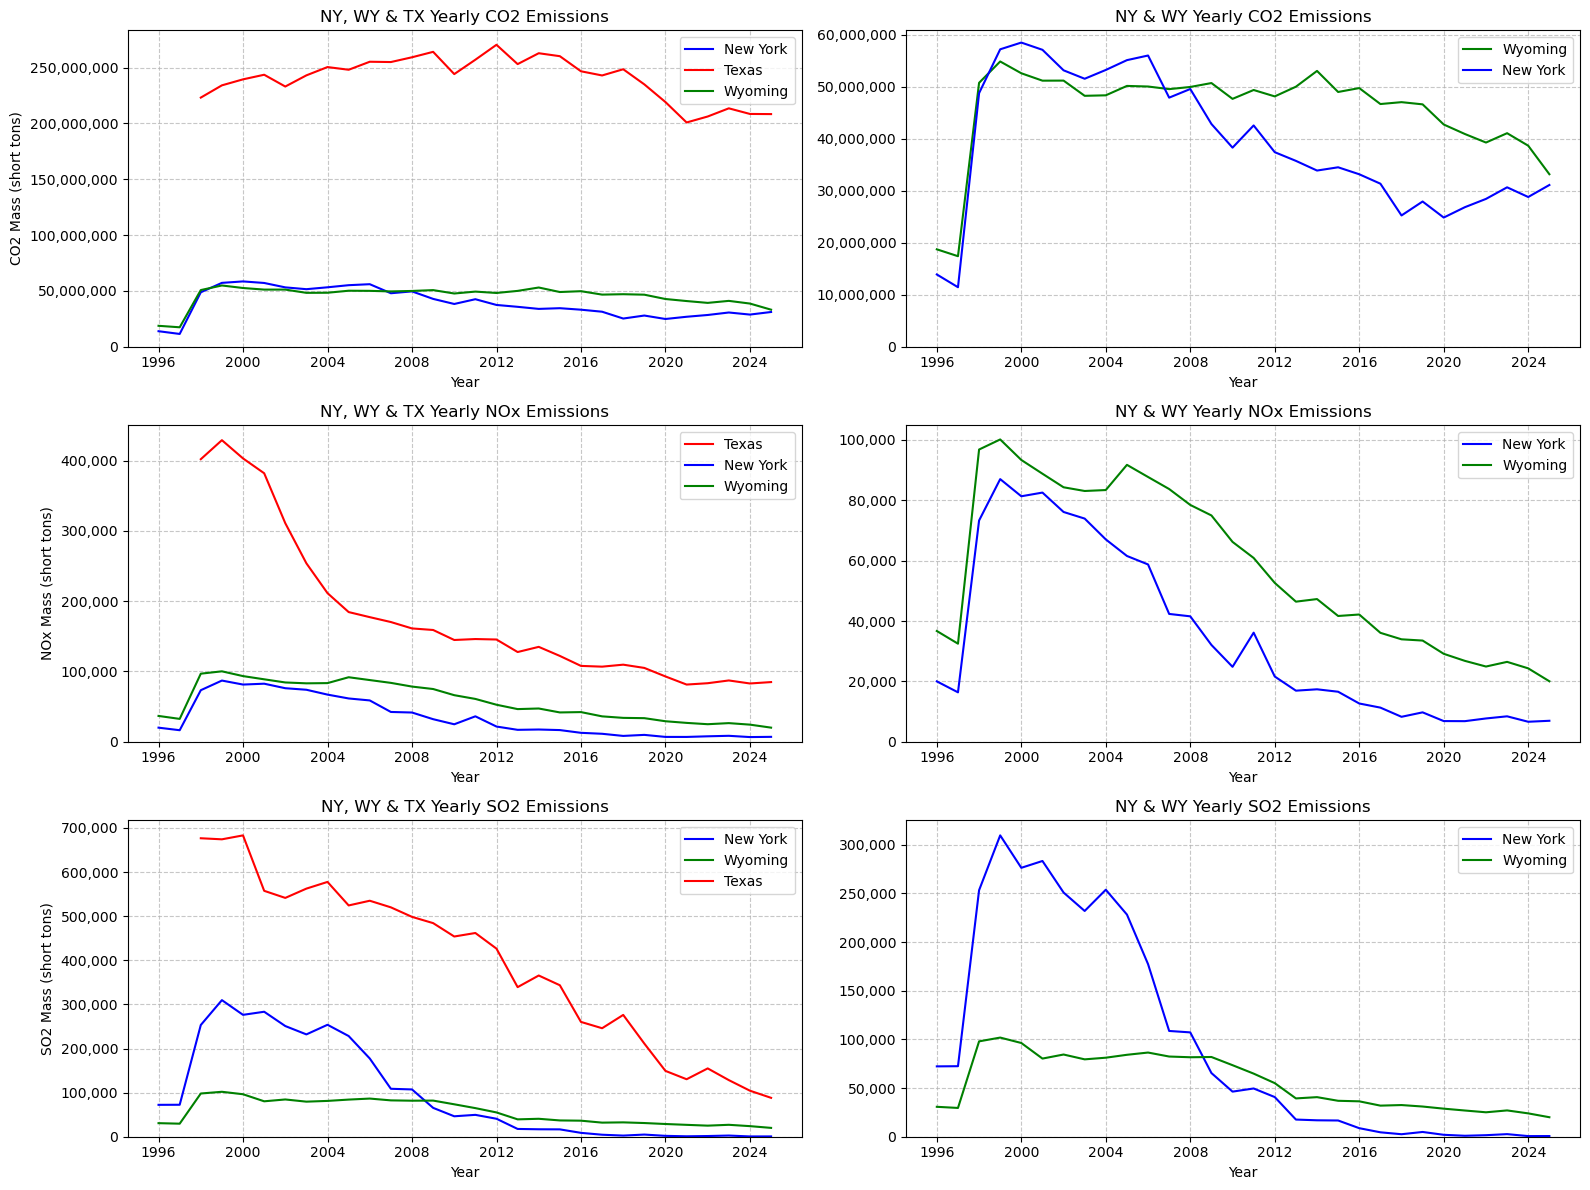

In [100]:
# Resample to yearly NOx emissions (sum)
emissions_by_year_ny_nox = campd_daily_ny["NOx Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_nox = campd_daily_tx["NOx Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_nox = campd_daily_wy["NOx Mass (short tons)"].resample('YE').sum()

# Resample to yearly SO2 emissions (sum)
emissions_by_year_ny_so2 = campd_daily_ny["SO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_so2 = campd_daily_tx["SO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_so2 = campd_daily_wy["SO2 Mass (short tons)"].resample('YE').sum()

# Resample to yearly CO2 emissions (sum)
emissions_by_year_ny_co2 = campd_daily_ny["CO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_co2 = campd_daily_tx["CO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_co2 = campd_daily_wy["CO2 Mass (short tons)"].resample('YE').sum()

# Function to format y-axis numbers with commas
def format_with_commas(x, pos):
    return f"{x:,.0f}"

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# CO2
axes[0, 0].plot(emissions_by_year_ny_co2.index, emissions_by_year_ny_co2.values, color='b', label='New York')
axes[0, 0].plot(emissions_by_year_tx_co2.index, emissions_by_year_tx_co2.values, color='r', label='Texas')
axes[0, 0].plot(emissions_by_year_wy_co2.index, emissions_by_year_wy_co2.values, color='g', label='Wyoming')
axes[0, 0].set_title('NY, WY & TX Yearly CO2 Emissions')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('CO2 Mass (short tons)')
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[0, 0].grid(True, linestyle="--", alpha=0.7)
axes[0, 0].legend()
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[0, 1].plot(emissions_by_year_wy_co2.index, emissions_by_year_wy_co2.values, color='g', label='Wyoming')
axes[0, 1].plot(emissions_by_year_ny_co2.index, emissions_by_year_ny_co2.values, color='b', label='New York')
axes[0, 1].set_title('NY & WY Yearly CO2 Emissions')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylim(bottom=0)
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[0, 1].grid(True, linestyle="--", alpha=0.7)
axes[0, 1].legend()
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# NOx
axes[1, 0].plot(emissions_by_year_tx_nox.index, emissions_by_year_tx_nox.values, color='r', label='Texas')
axes[1, 0].plot(emissions_by_year_ny_nox.index, emissions_by_year_ny_nox.values, color='b', label='New York')
axes[1, 0].plot(emissions_by_year_wy_nox.index, emissions_by_year_wy_nox.values, color='g', label='Wyoming')
axes[1, 0].set_title('NY, WY & TX Yearly NOx Emissions')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('NOx Mass (short tons)')
axes[1, 0].set_ylim(bottom=0)
axes[1, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[1, 0].grid(True, linestyle="--", alpha=0.7)
axes[1, 0].legend()
axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[1, 1].plot(emissions_by_year_ny_nox.index, emissions_by_year_ny_nox.values, color='b', label='New York')
axes[1, 1].plot(emissions_by_year_wy_nox.index, emissions_by_year_wy_nox.values, color='g', label='Wyoming')
axes[1, 1].set_title('NY & WY Yearly NOx Emissions')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylim(bottom=0)
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[1, 1].grid(True, linestyle="--", alpha=0.7)
axes[1, 1].legend()
axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# SO2
axes[2, 0].plot(emissions_by_year_ny_so2.index, emissions_by_year_ny_so2.values, color='b', label='New York')
axes[2, 0].plot(emissions_by_year_wy_so2.index, emissions_by_year_wy_so2.values, color='g', label='Wyoming')
axes[2, 0].plot(emissions_by_year_tx_so2.index, emissions_by_year_tx_so2.values, color='r', label='Texas')
axes[2, 0].set_title('NY, WY & TX Yearly SO2 Emissions')
axes[2, 0].set_xlabel('Year')
axes[2, 0].set_ylabel('SO2 Mass (short tons)')
axes[2, 0].set_ylim(bottom=0)
axes[2, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[2, 0].grid(True, linestyle="--", alpha=0.7)
axes[2, 0].legend()
axes[2, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[2, 1].plot(emissions_by_year_ny_so2.index, emissions_by_year_ny_so2.values, color='b', label='New York')
axes[2, 1].plot(emissions_by_year_wy_so2.index, emissions_by_year_wy_so2.values, color='g', label='Wyoming')
axes[2, 1].set_title('NY & WY Yearly SO2 Emissions')
axes[2, 1].set_xlabel('Year')
axes[2, 1].set_ylim(bottom=0)
axes[2, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[2, 1].grid(True, linestyle="--", alpha=0.7)
axes[2, 1].legend()
axes[2, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

In [ ]:
# Big jump in EGUs in 1997

wy_1996 = campd_daily_wy[campd_daily_wy.index.year == 1996]["Unit ID"].count()
wy_1997 = campd_daily_wy[campd_daily_wy.index.year == 1997]["Unit ID"].count()

ny_1996 = campd_daily_ny[campd_daily_ny.index.year == 1996]["Unit ID"].count()
ny_1997 = campd_daily_ny[campd_daily_ny.index.year == 1997]["Unit ID"].count()

print(f"WY EGUs - 1996: {wy_1996:,}")
print(f"WY EGUs - 1997: {wy_1997:,}")
print("")
print(f"NY EGUs - 1996: {ny_1996:,}")
print(f"NY EGUs - 1997: {ny_1997:,}")

# (TX only started reporting in 1997)

WY EGUs - 1996: 1,360
WY EGUs - 1997: 5,483

NY EGUs - 1996: 3,524
NY EGUs - 1997: 20,093


In [73]:
# TX Emissions Change
print("TX SO2 change since 1997: ", ((emissions_by_year_tx_so2.loc["1997-12-31"] - emissions_by_year_tx_so2.loc["2024-12-31"]) / emissions_by_year_tx_so2.loc["1997-12-31"]) * 100, "%")
print("TX NOx change since 1997: ", ((emissions_by_year_tx_nox.loc["1997-12-31"] - emissions_by_year_tx_nox.loc["2024-12-31"]) / emissions_by_year_tx_nox.loc["1997-12-31"]) * 100, "%")
print("TX CO2 change since 1997: ", ((emissions_by_year_tx_co2.loc["1997-12-31"] - emissions_by_year_tx_co2.loc["2024-12-31"]) / emissions_by_year_tx_co2.loc["1997-12-31"]) * 100, "%")
print("")

# WY Emissions Change
print("WY SO2 change since 1997: ", (emissions_by_year_wy_so2.loc["1997-12-31"] - emissions_by_year_wy_so2.loc["2024-12-31"]) / emissions_by_year_wy_so2.loc["1997-12-31"] * 100, "%")
print("WY NOx change since 1997: ", (emissions_by_year_wy_nox.loc["1997-12-31"] - emissions_by_year_wy_nox.loc["2024-12-31"]) / emissions_by_year_wy_nox.loc["1997-12-31"] * 100, "%")
print("WY CO2 change since 1997: ", (emissions_by_year_wy_co2.loc["1997-12-31"] - emissions_by_year_wy_co2.loc["2024-12-31"]) / emissions_by_year_wy_co2.loc["1997-12-31"] * 100, "%")
print("")

# NY Emissions Change
print("NY SO2 change since 1997: ", (emissions_by_year_ny_so2.loc["1997-12-31"] - emissions_by_year_ny_so2.loc["2024-12-31"]) / emissions_by_year_ny_so2.loc["1997-12-31"] * 100, "%")
print("NY NOx change since 1997: ", (emissions_by_year_ny_nox.loc["1997-12-31"] - emissions_by_year_ny_nox.loc["2024-12-31"]) / emissions_by_year_ny_nox.loc["1997-12-31"] * 100, "%")
print("NY CO2 change since 1997: ", (emissions_by_year_ny_co2.loc["1997-12-31"] - emissions_by_year_ny_co2.loc["2024-12-31"]) / emissions_by_year_ny_co2.loc["1997-12-31"] * 100, "%")

TX SO2 change since 1997:  86.97159992459801 %
TX NOx change since 1997:  78.88850713658553 %
TX CO2 change since 1997:  6.624174728005595 %

WY SO2 change since 1997:  79.55638640739043 %
WY NOx change since 1997:  79.31185034766338 %
WY CO2 change since 1997:  34.63173866263505 %

NY SO2 change since 1997:  99.72453933360444 %
NY NOx change since 1997:  90.5361675489526 %
NY CO2 change since 1997:  36.22466714795023 %


<h4>Last 6Y (hourly data)</h4>

- plot emission developments using hourly data aggregated by month-ends for the past 6 years


In [103]:
# Set date as index for resampling
campd_ny.set_index('datetime', inplace=True)
campd_tx.set_index('datetime', inplace=True)
campd_wy.set_index('datetime', inplace=True)

In [ ]:
# Convert lbs to short tons for consistency
campd_ny["NOx Mass (short tons)"] = campd_ny["NOx Mass (lbs)"] / 2000
campd_tx["NOx Mass (short tons)"] = campd_tx["NOx Mass (lbs)"] / 2000
campd_wy["NOx Mass (short tons)"] = campd_wy["NOx Mass (lbs)"] / 2000

campd_ny["SO2 Mass (short tons)"] = campd_ny["SO2 Mass (lbs)"] / 2000
campd_tx["SO2 Mass (short tons)"] = campd_tx["SO2 Mass (lbs)"] / 2000
campd_wy["SO2 Mass (short tons)"] = campd_wy["SO2 Mass (lbs)"] / 2000

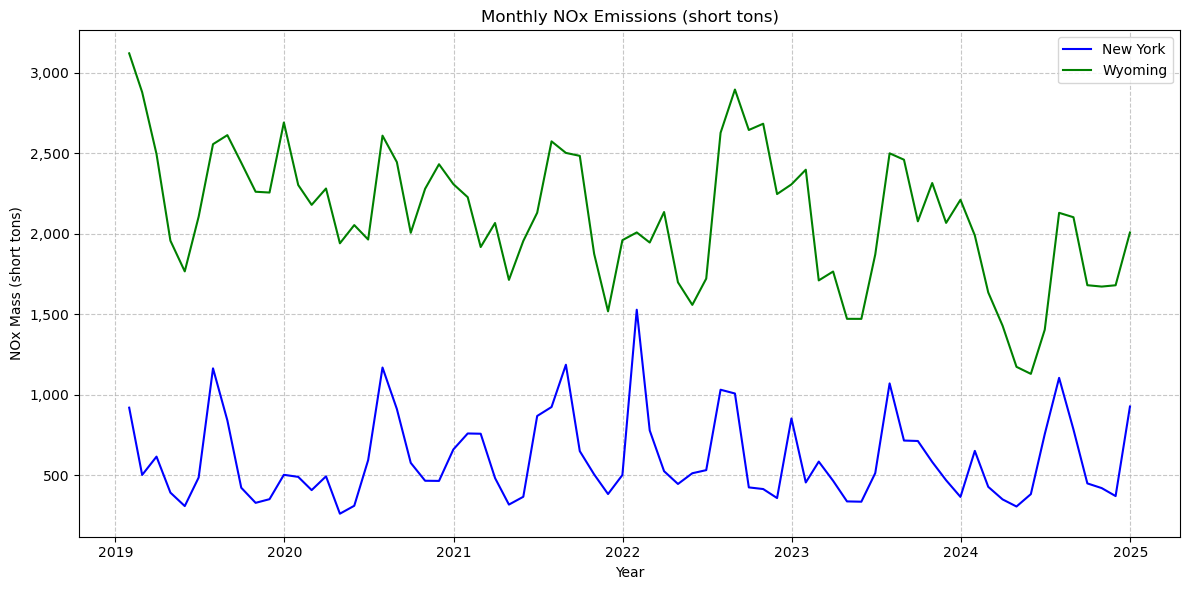

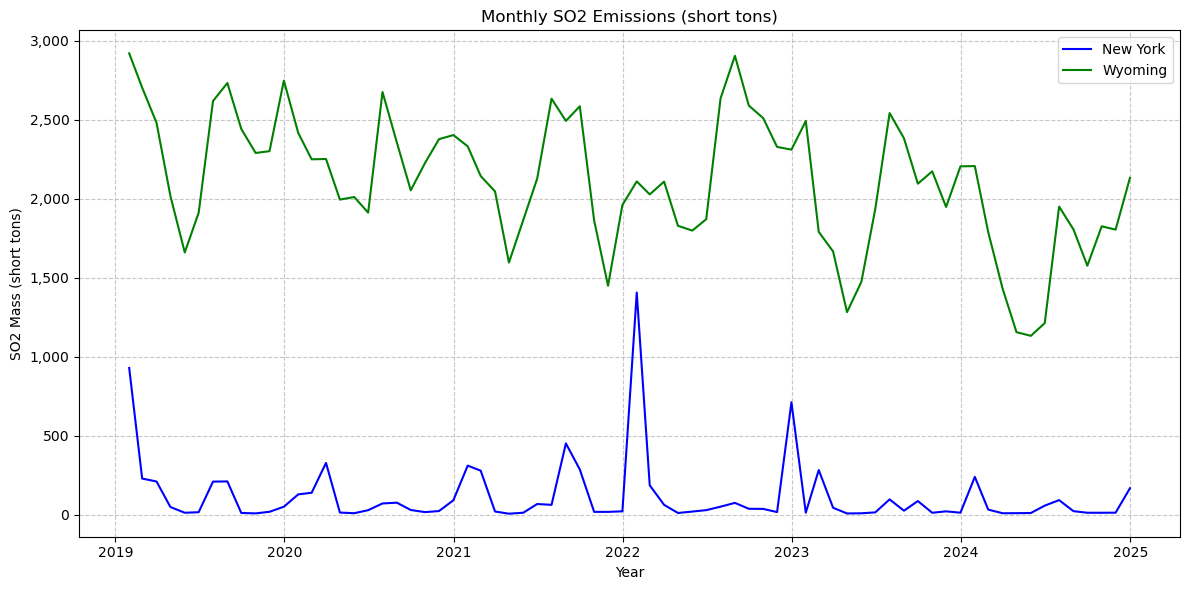

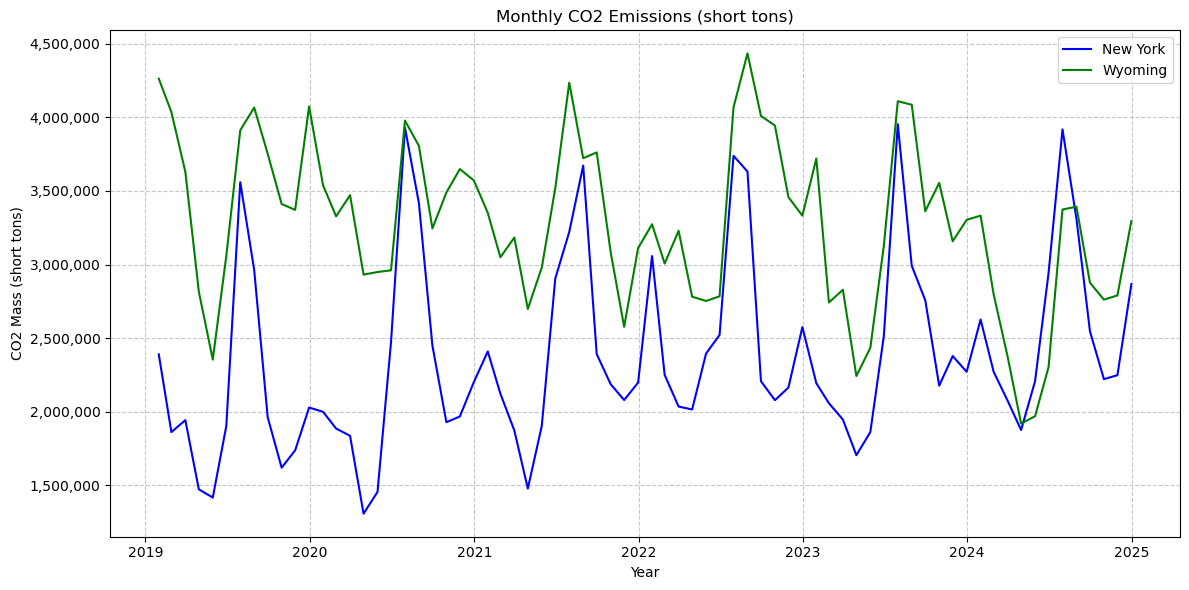

In [ ]:
# Function to format y-axis numbers with commas
def format_with_commas(x, pos):
    return f"{x:,.0f}"

# Resample to monthly NOx emissions (sum)
emissions_by_month_ny = campd_ny["NOx Mass (short tons)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["NOx Mass (short tons)"].resample('ME').sum()

# NOx
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')
plt.title('Monthly NOx Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('NOx Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

# Resample to monthly SO2 emissions (sum)
emissions_by_month_ny = campd_ny["SO2 Mass (short tons)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["SO2 Mass (short tons)"].resample('ME').sum()

# SO2
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')
plt.title('Monthly SO2 Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('SO2 Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

# Resample to monthly CO2 emissions (sum)
emissions_by_month_ny = campd_ny["CO2 Mass (short tons)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["CO2 Mass (short tons)"].resample('ME').sum()

# CO2
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')
plt.title('Monthly CO2 Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('CO2 Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

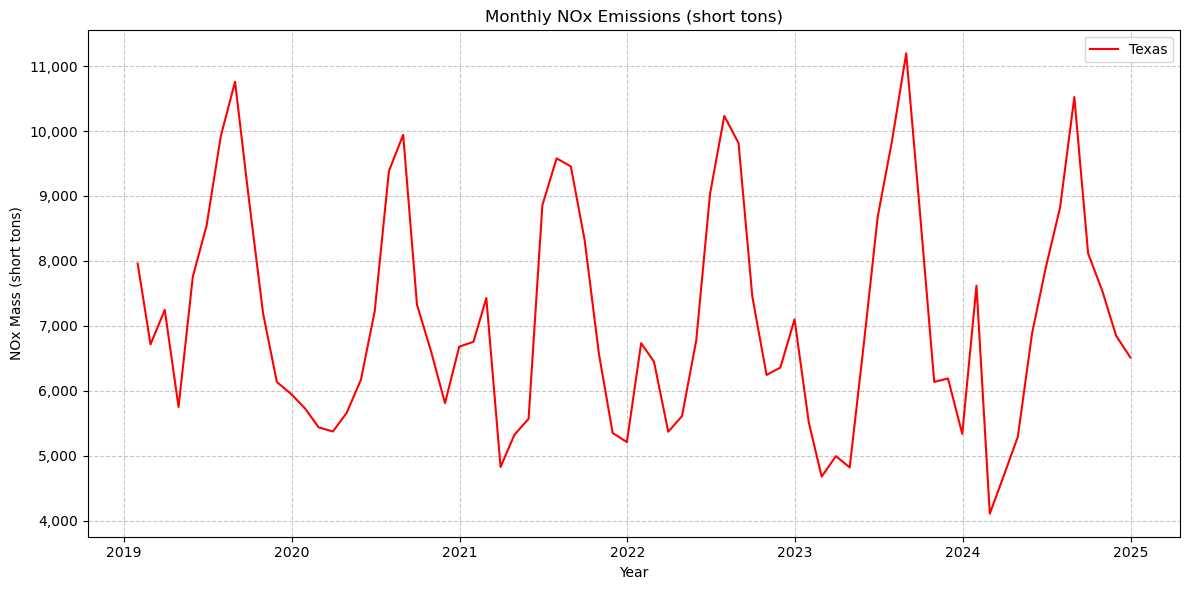

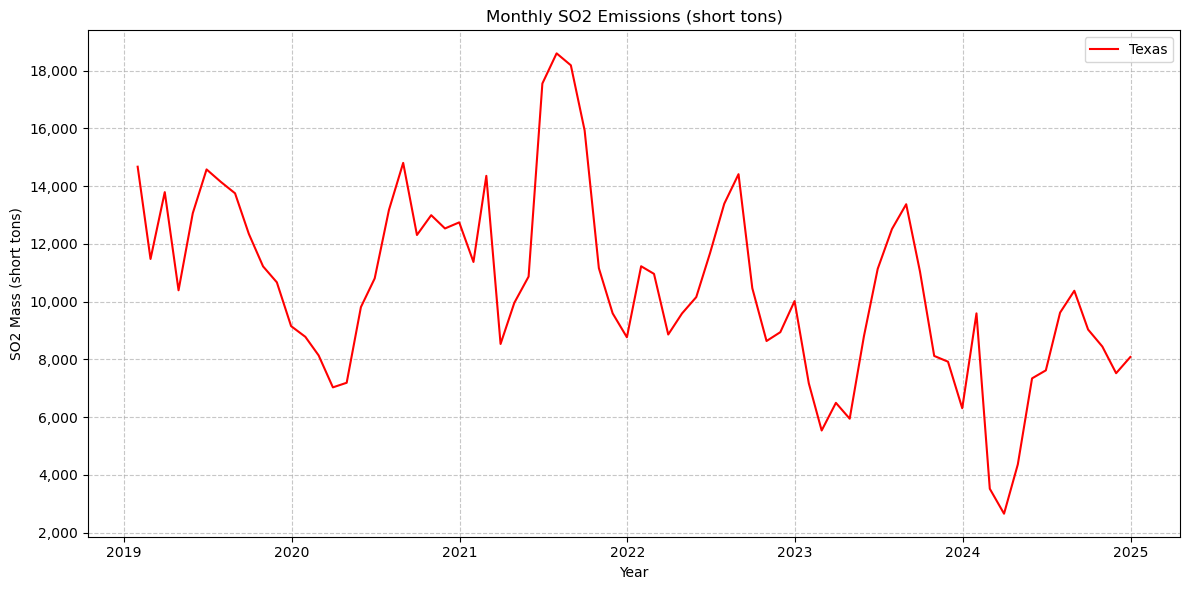

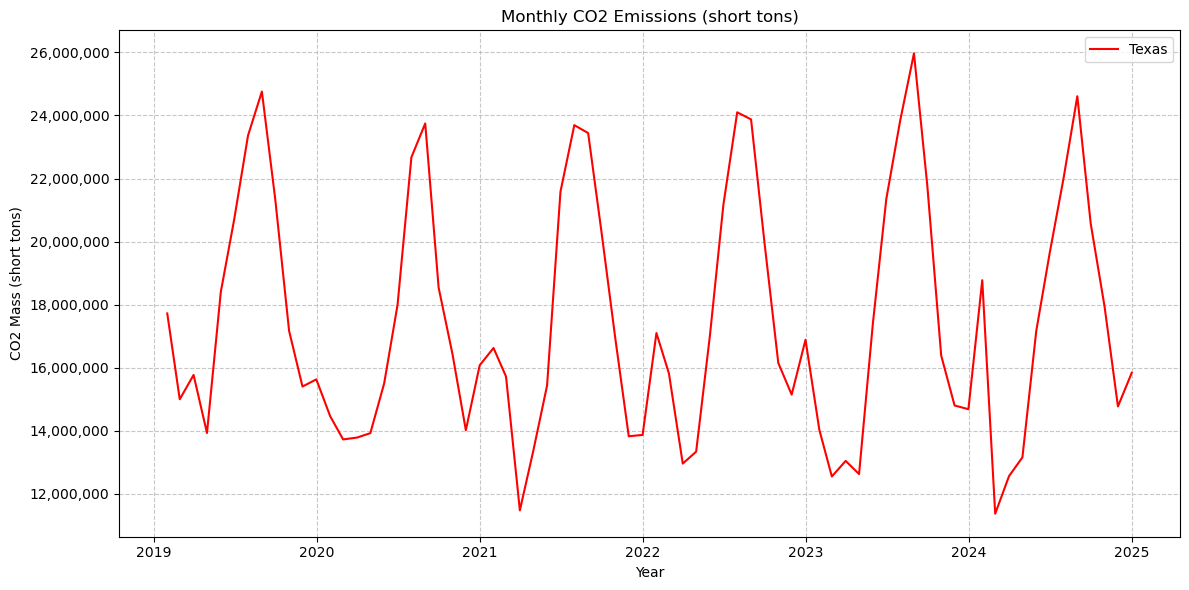

In [ ]:
# Resample to monthly NOx emissions (sum)
emissions_by_month_tx = campd_tx["NOx Mass (short tons)"].resample('ME').sum()

# NOx
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')
plt.title('Monthly NOx Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('NOx Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

# Resample to monthly SO2 emissions (sum)
emissions_by_month_tx = campd_tx["SO2 Mass (short tons)"].resample('ME').sum()

# SO2
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')
plt.title('Monthly SO2 Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('SO2 Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

# Resample to monthly CO2 emissions (sum)
emissions_by_month_tx = campd_tx["CO2 Mass (short tons)"].resample('ME').sum()

# CO2
plt.figure(figsize=(12, 6))
plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')
plt.title('Monthly CO2 Emissions (short tons)')
plt.xlabel('Year')
plt.ylabel('CO2 Mass (short tons)')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
plt.tight_layout()
plt.show()

In [125]:
# reset indices (datetime) to a column again
campd_ny = campd_ny.reset_index()
campd_tx = campd_tx.reset_index()
campd_wy = campd_wy.reset_index()

<h4>Autocorrelation</h4>

for each state and emission type we calculate autocorrelation using all_hour data at an alpha of 5%. specficially, we:
- plot daily sum acf across 400 days for a specific unit using the built-in function from statsmodels 
- calculate and plot averaged daily acf across 400 days for all units + units where acf is significant
- plot averaged hourly acf across a week for all units

In [4]:
# Some global styling for plots

sns.set_style("darkgrid") # seaborn grid
plt.rc("figure", figsize=(16, 12)) # standard fig size

<h5>Texas</h5>

<h6>CO2</h6>

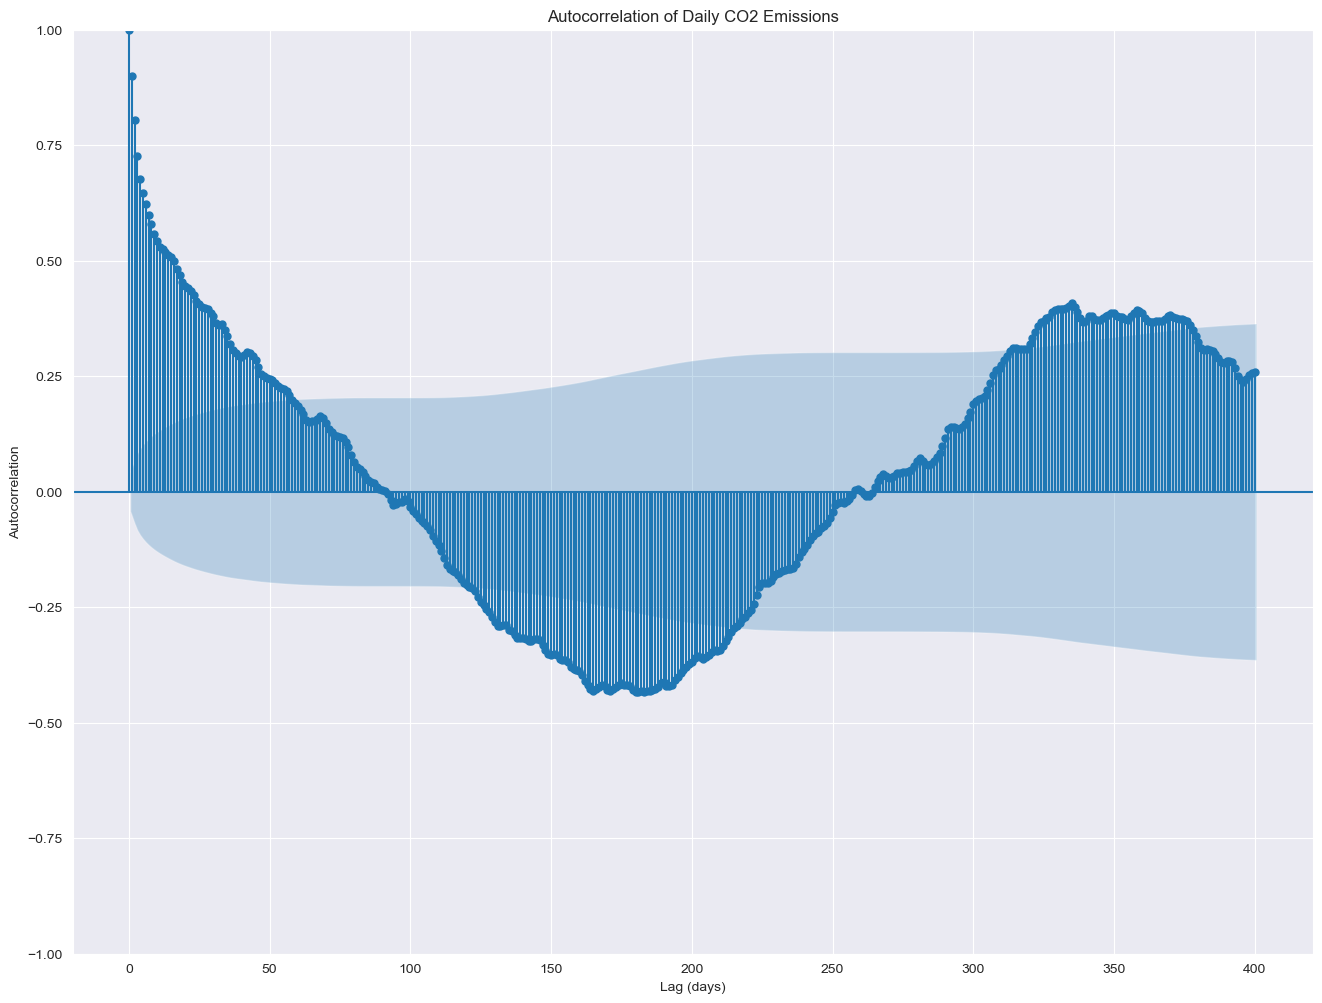

In [ ]:
# Look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['CO2 Mass (short tons)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily CO2 Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


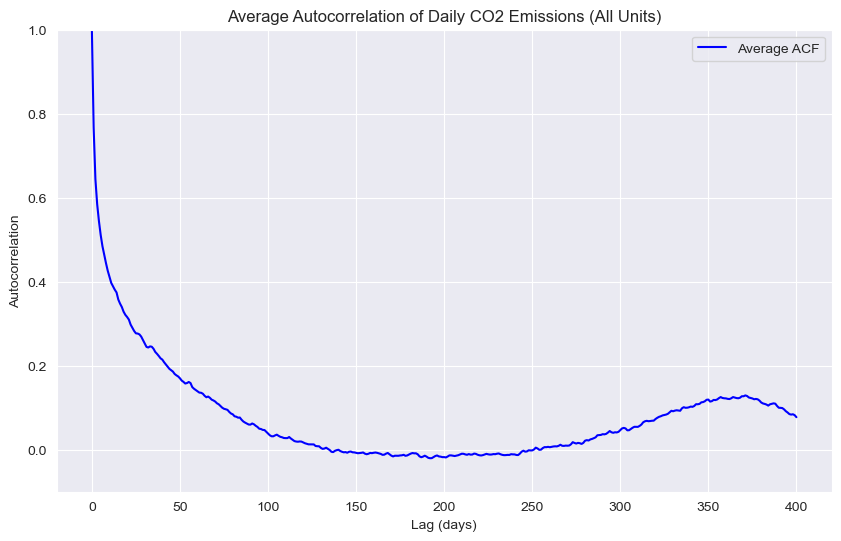

In [160]:
# Filter for units that emit CO2 at all
sample_units = campd_tx_all_hours[campd_tx_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha=0.05
acf_values_list = []
confidence_intervals_list = []

# Loop through each unit and calculate ACF
for (facility_id, unit_id), group in daily_emissions.groupby(['Facility ID', 'Unit ID']):
    group = group.sort_values(by='Date')
    
    acf_values, confint = acf(group['Daily Emissions'], nlags=400, alpha=0.05)
    
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1) # set fixed y-axis limits for comparability
plt.legend()
plt.grid(True)
plt.show()

In [83]:
# Get units with significant ACF values at the 1-year mark

significant_units = []

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags at 365 days
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 # conf int is centered around acf values per default, have to adjust them to center around x-axis (see https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.acf.html)
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if ((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(3441, '8'), (3441, '9'), (3443, '9'), (3452, '2'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY1'), (3460, 'CBY2'), (3470, 'WAP2'), (3476, '5'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3504, '1'), (3601, '1'), (3601, '2'), (3611, '1'), (3612, '1'), (3612, '3'), (3612, 'CGT5'), (3628, '2'), (4937, 'CT-2'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6243, '1'), (7900, 'SH4'), (50109, 'HRSG1'), (50109, 'HRSG2'), (54817, 'EAST'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-1'), (55137, 'CTG-2'), (55137, 'CTG-3'), (55139, 'CTG1'), (55139, 'CTG2'), (55144, 'STK1'), (55144, 'STK2'), (55144, 'STK3'), (55154, '1'), (55154, '2'), (55172, 'GT-3'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT

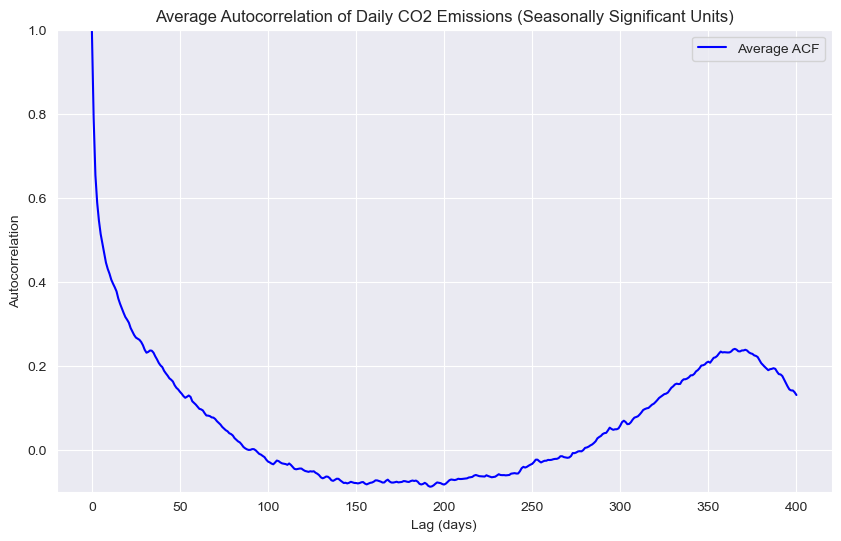

In [ ]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for (facility_id, unit_id), group in daily_emissions.groupby(['Facility ID', 'Unit ID']):
    group = group.sort_values(by='Date')
    
    acf_values, confint = acf(group['Daily Emissions'], nlags=400, alpha=0.05)
    
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# much stronger seasonality

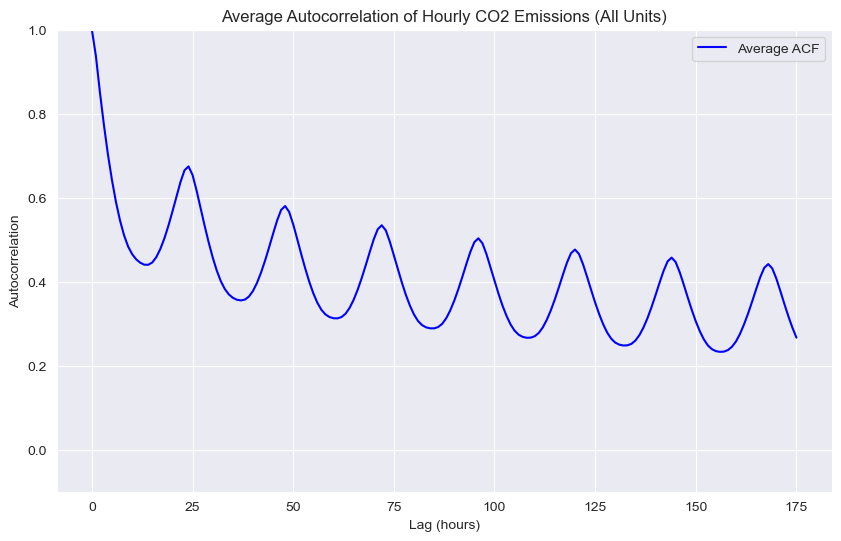

In [ ]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# # Get acf values and confidence intervals for all units up to 24*7 = 168 lags (1 week) with confidence intervals at alpha 0.05 (we actually compute for 175 hours to make the x axis cleaner)
acf_values_list = []
confidence_intervals_list = []

for (facility_id, unit_id), group in sampled_data.groupby(['Facility ID', 'Unit ID']):
    group = group.sort_values(by='datetime')
    
    acf_values, confint = acf(group['CO2 Mass (short tons)'], nlags=175, alpha=0.05)
    
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)


# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

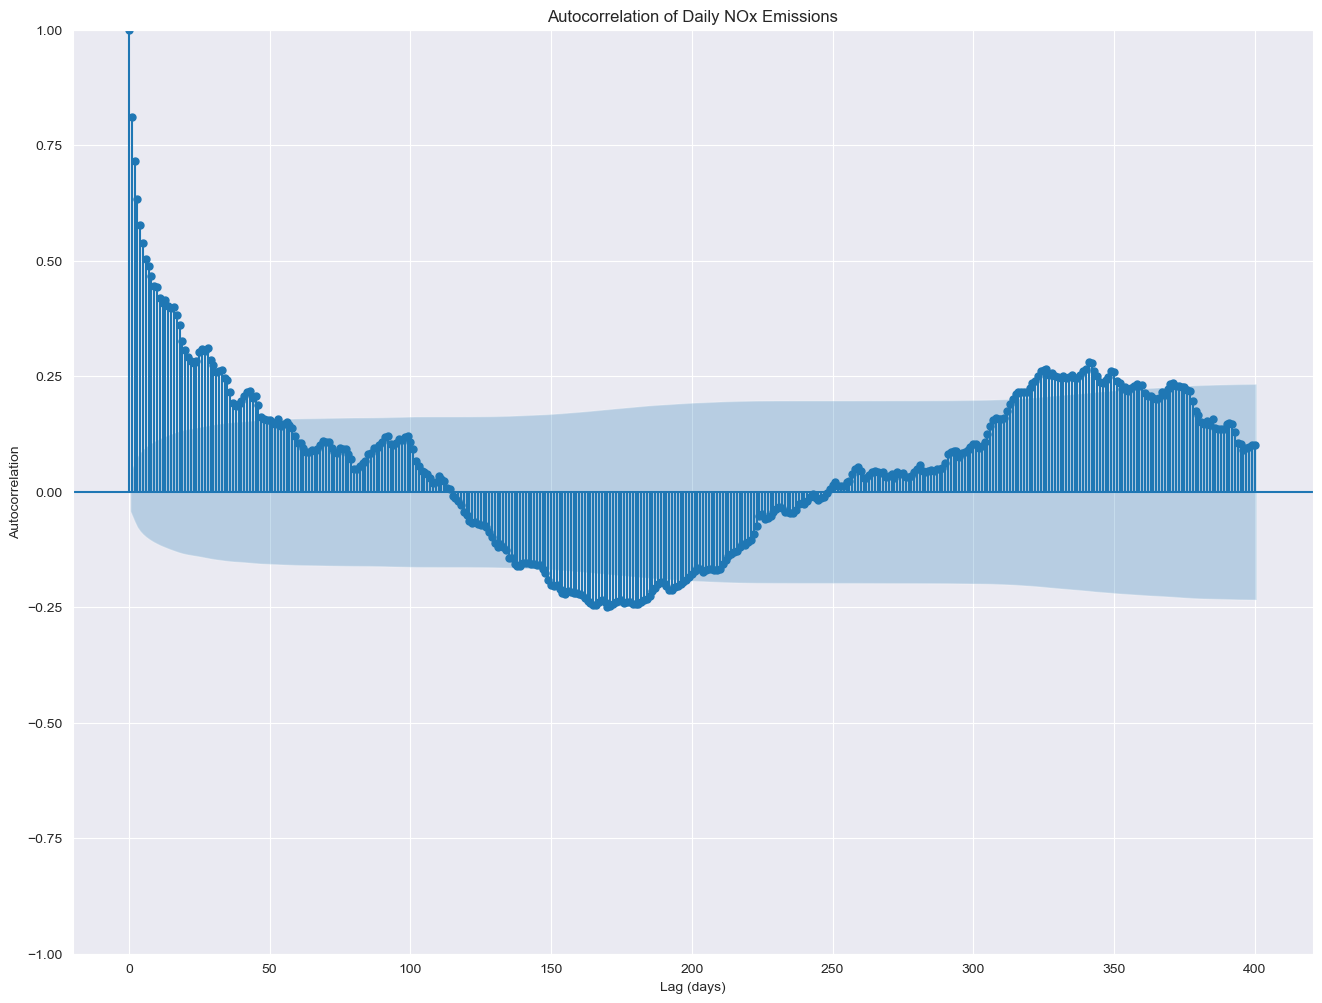

In [52]:
# look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['NOx Mass (lbs)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily NOx Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


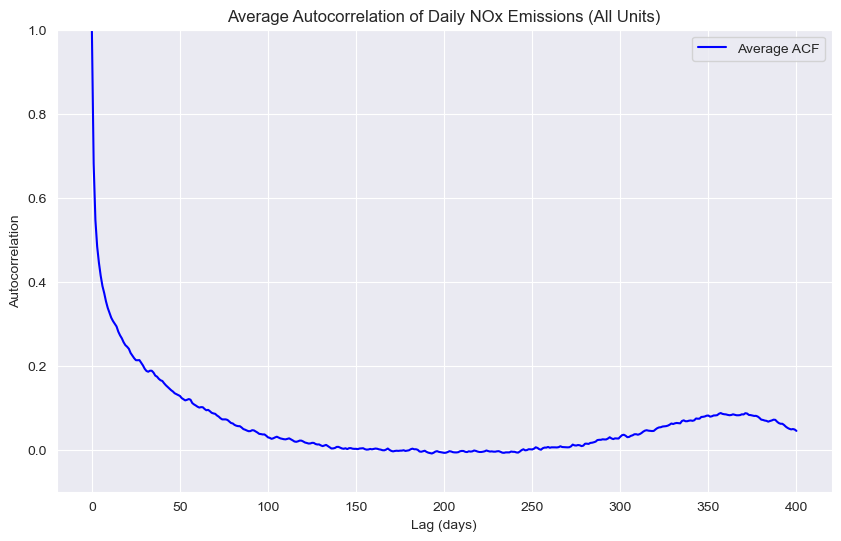

In [ ]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_tx_all_hours[campd_tx_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 # conf int is centered around acf values per default, have to adjust them to center around x-axis (see https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.acf.html)
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(3441, '8'), (3443, '9'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY2'), (3470, 'WAP2'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3576, 'BW2'), (3601, '1'), (3601, '2'), (3628, '2'), (4195, '2'), (4266, '5'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6194, '172B'), (6243, '1'), (7030, 'U2'), (50109, 'HRSG1'), (50109, 'HRSG2'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK1'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-2'), (55139, 'CTG1'), (55139, 'CTG2'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT-4'), (55664, 'GT-1'), (55664, 'GT-2'), (55708, 'BFB-1'), (56611, 'S01'), (56806, 'CBY41'), (58001, 'CTG3'), (58001, 'CTG4'), (58005, 'CTG1'), (58005, 'CTG2'), (58562, 'GT-2'), (59812, 'CGT5')]
Of a total  390  unit

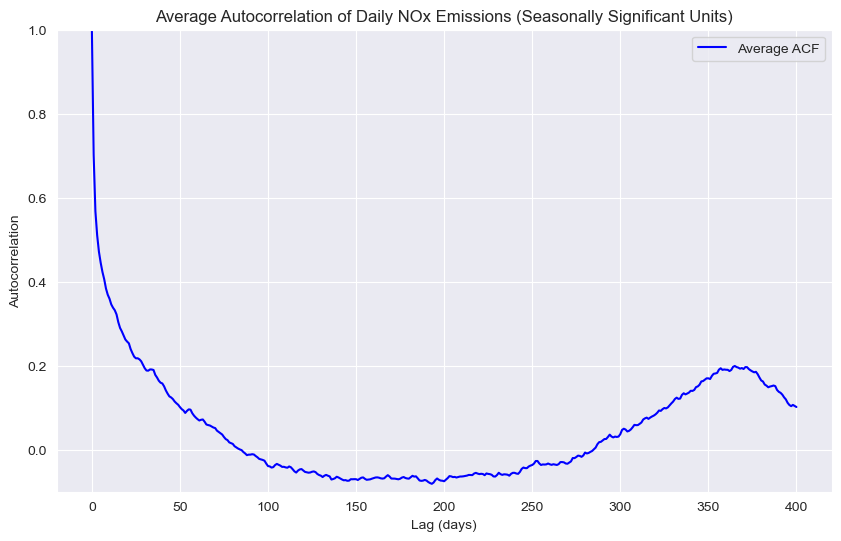

In [ ]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

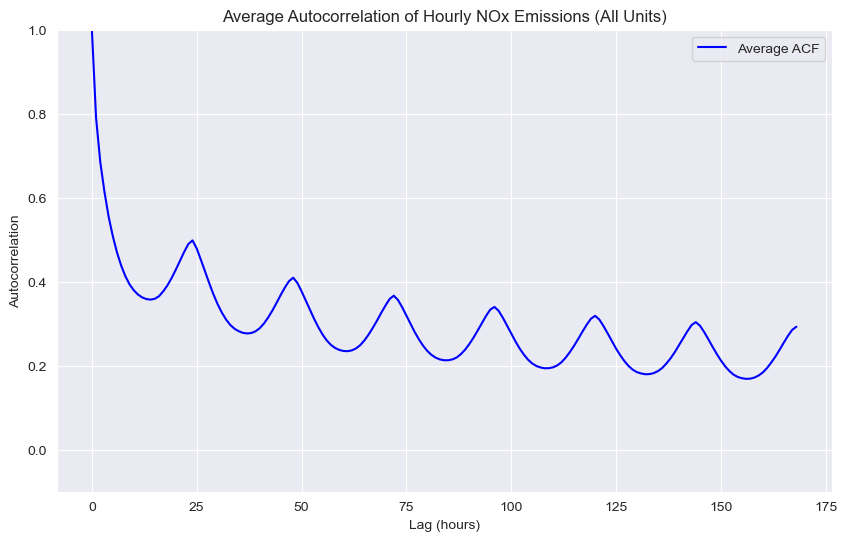

In [ ]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

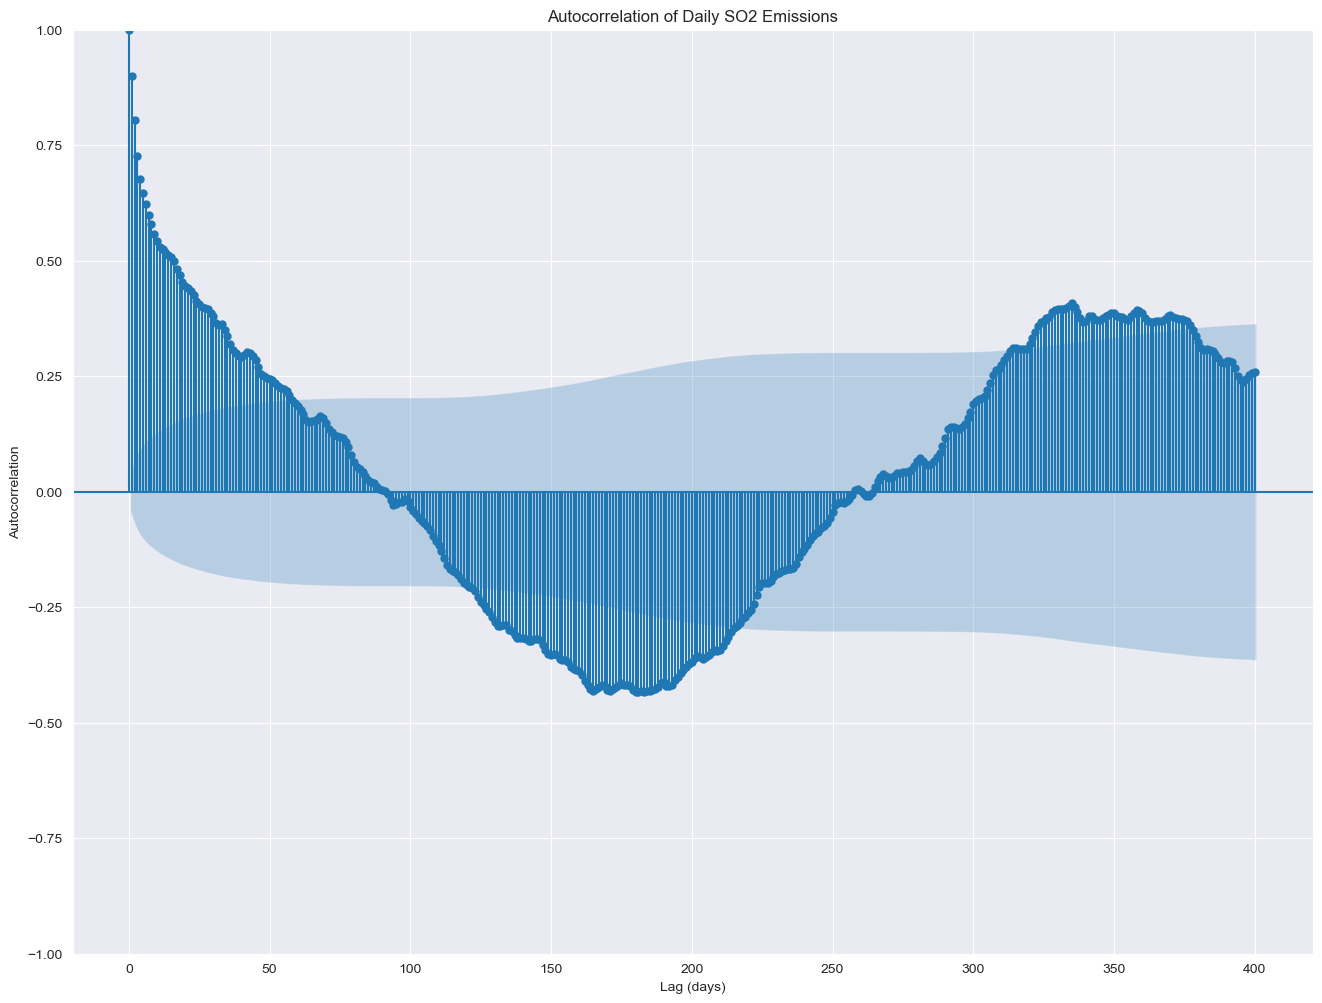

In [59]:
# look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['SO2 Mass (lbs)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily SO2 Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


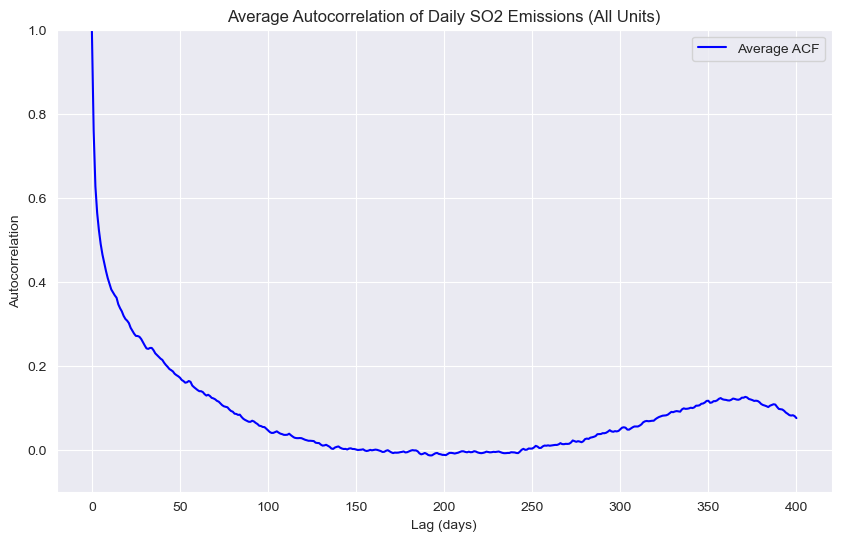

In [ ]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit SO2
sample_units = campd_tx_all_hours[campd_tx_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(3441, '8'), (3441, '9'), (3443, '9'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY1'), (3460, 'CBY2'), (3470, 'WAP2'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3504, '1'), (3601, '1'), (3601, '2'), (3611, '1'), (3612, '1'), (3612, '3'), (3612, 'CGT5'), (3612, 'CGT8'), (4937, 'CT-2'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6243, '1'), (7900, 'SH4'), (50109, 'HRSG1'), (50109, 'HRSG2'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-1'), (55137, 'CTG-2'), (55137, 'CTG-3'), (55139, 'CTG1'), (55139, 'CTG2'), (55144, 'STK1'), (55144, 'STK2'), (55144, 'STK3'), (55154, '1'), (55154, '2'), (55172, 'GT-3'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT-3'), (55230, 'CT-4'), (55320, 'GT-1'), 

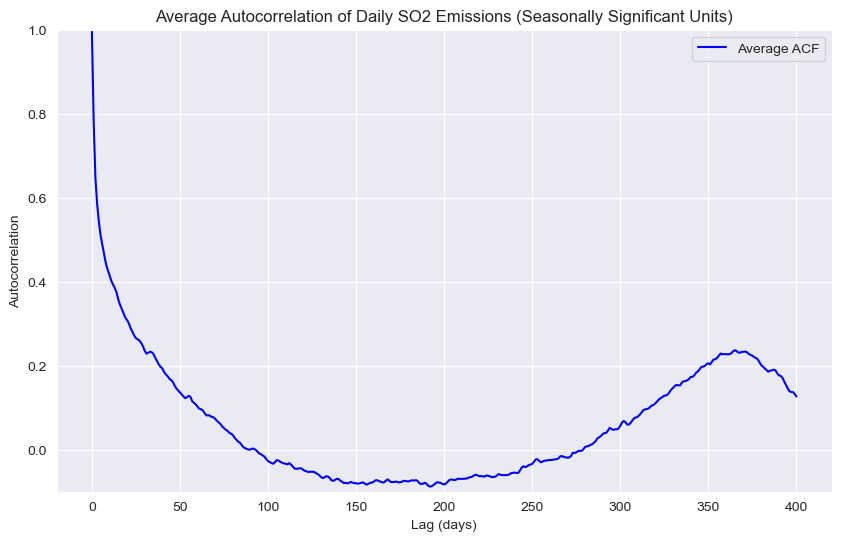

In [ ]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily SO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

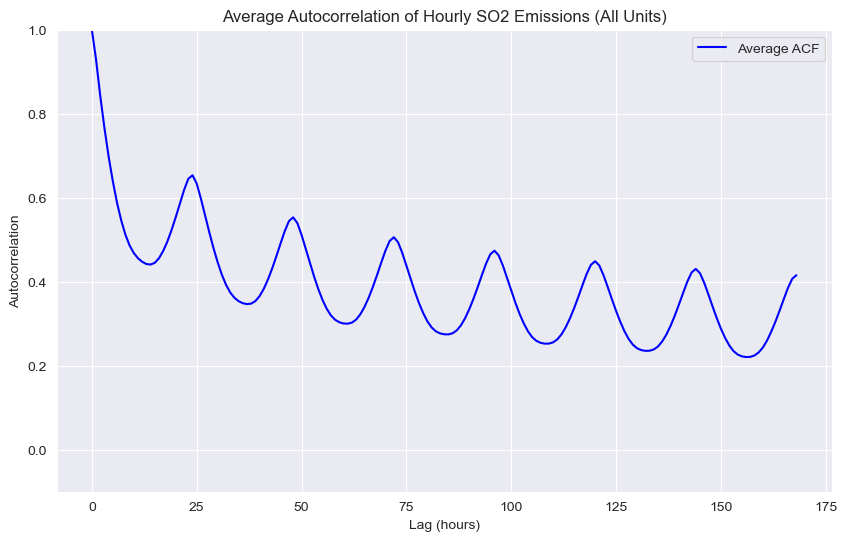

In [ ]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h5>New York</h5>

<h6>CO2</h6>

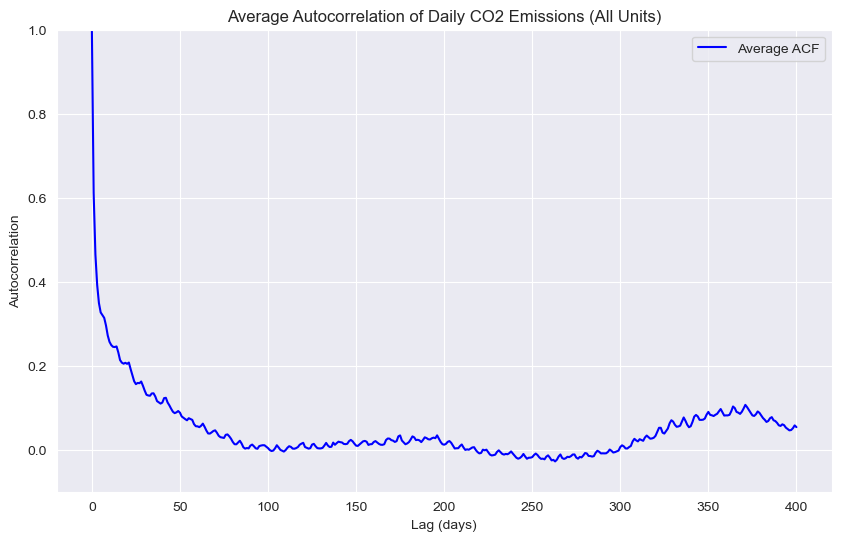

In [110]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit CO2
sample_units = campd_ny_all_hours[campd_ny_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(2493, '1'), (2493, '2'), (2493, '60'), (2500, '10'), (2500, '20'), (2504, '121'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2517, '4'), (2517, 'UGT002'), (2517, 'UGT003'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2682, '10'), (6082, '1'), (7146, 'UGT007'), (7869, 'UGT012'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8007, 'U00011'), (8007, 'U00012'), (8007, 'U00013'), (8007, 'U00014'), (8007, 'U00015'), (8007, 'U00016'), (8007, 'U00017'), (8007, 'U00018'), (8007, 'U00019'), (8007, 'U00020'), (8053, 'PT01'), (10619, '1'), (10620, '1'), (50449, '1'), (50450, '1'), (50451, '1'), (50978, 'A'), (54149, '1'), (54547, '2'), (54547, '3'), (54547, '4'), (54574, '1'), (55375, 'CT3'), (55375, 'CT4'), (55405, '2'), (55699, '1'), (55699, '2'), (55786, 'CT01'), (55786, 'CT02'), (55969, 'U-01'),

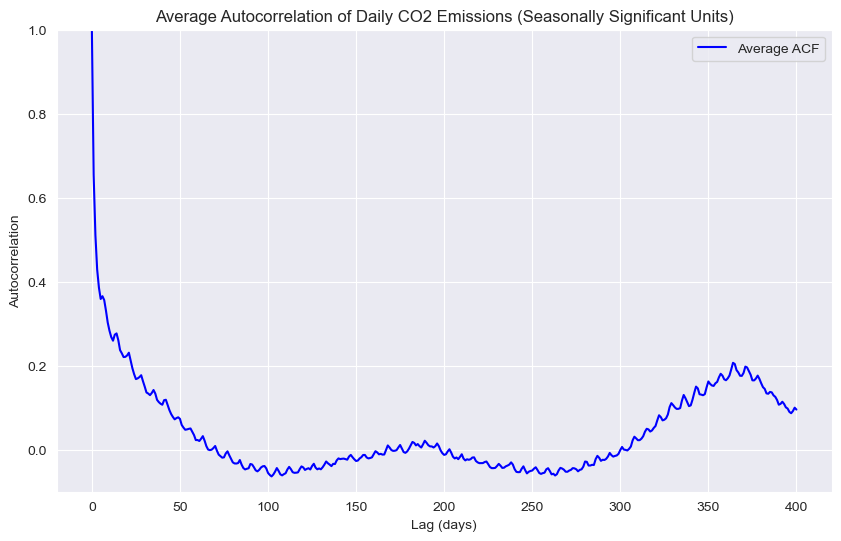

In [112]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_ny_all_hours[campd_ny_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

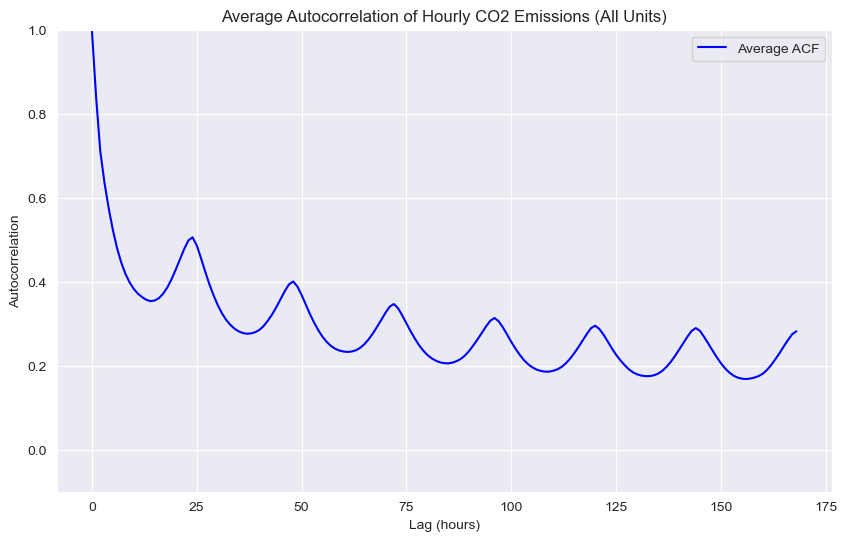

In [113]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='CO2 Mass (short tons)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

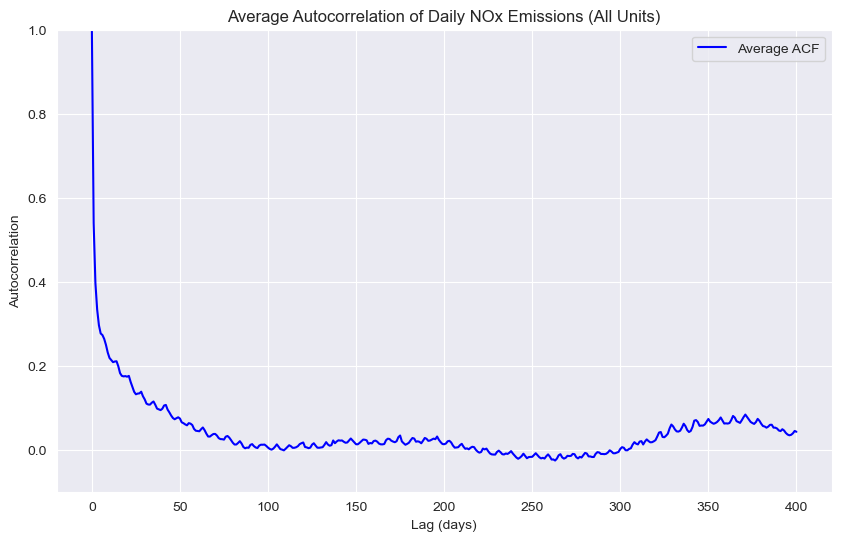

In [114]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_ny_all_hours[campd_ny_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [115]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(2490, '20'), (2493, '1'), (2493, '2'), (2493, '60'), (2500, '10'), (2500, '20'), (2504, '121'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2517, 'UGT002'), (2517, 'UGT003'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2682, '10'), (6082, '1'), (7146, 'UGT007'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8007, 'U00011'), (8007, 'U00012'), (8007, 'U00013'), (8007, 'U00014'), (8007, 'U00017'), (8007, 'U00018'), (8007, 'U00019'), (8007, 'U00020'), (8053, 'PT01'), (10190, '1'), (10619, '1'), (50449, '1'), (50450, '1'), (50451, '1'), (50978, 'A'), (54149, '1'), (54547, '1'), (54547, '2'), (54547, '3'), (54547, '4'), (54574, '1'), (55405, '2'), (55699, '2'), (55786, 'CT01'), (55786, 'CT02'), (55969, 'U-01'), (56196, 'CTG7A')]
Of a total  197  units,  56  have a significant seasonality


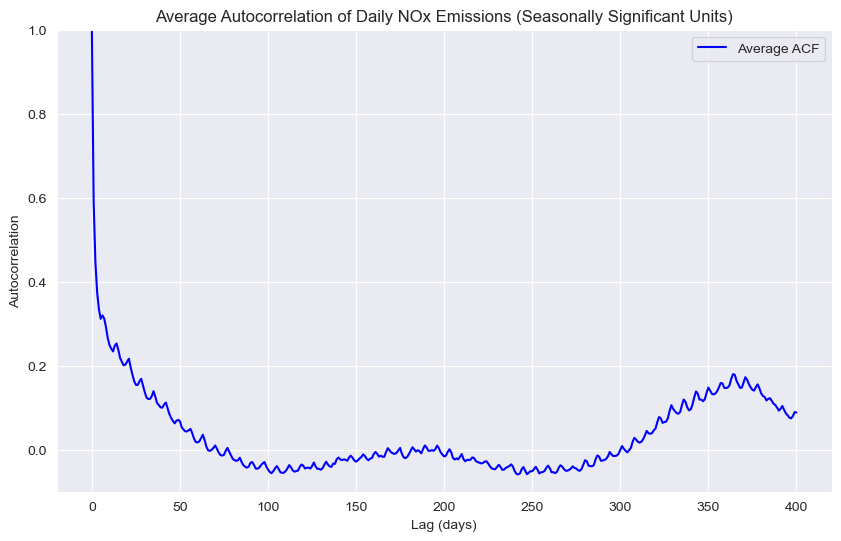

In [118]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_ny_all_hours[campd_ny_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

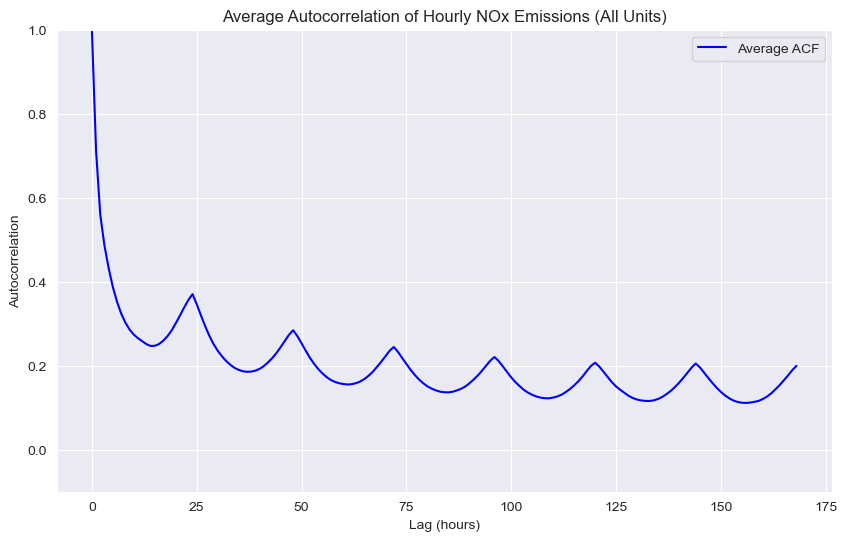

In [120]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

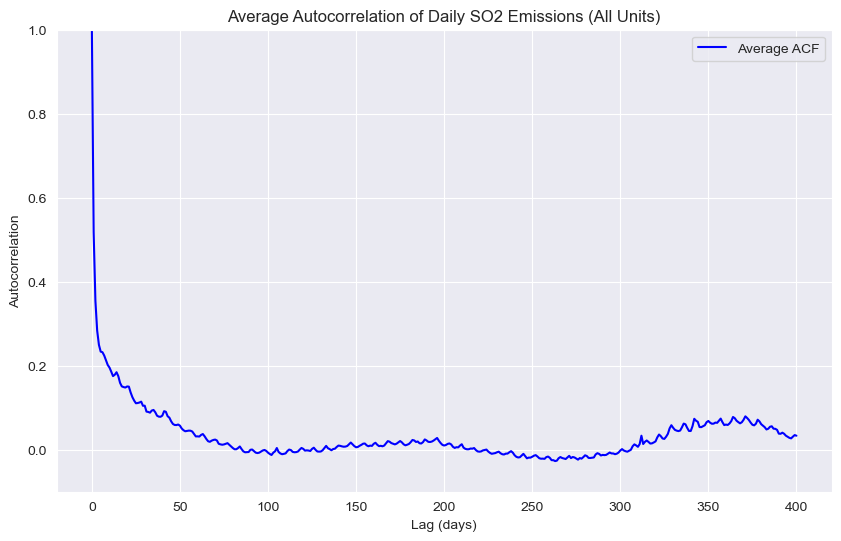

In [121]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit SO2
sample_units = campd_ny_all_hours[campd_ny_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [122]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(2493, '1'), (2493, '2'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2516, '4'), (2517, 'UGT002'), (2517, 'UGT003'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2682, '10'), (6082, '1'), (7146, 'UGT007'), (7869, 'UGT012'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8007, 'U00003'), (8007, 'U00004'), (8007, 'U00011'), (8007, 'U00012'), (8007, 'U00013'), (8007, 'U00014'), (8007, 'U00015'), (8007, 'U00016'), (8007, 'U00017'), (8007, 'U00018'), (8007, 'U00019'), (8007, 'U00020'), (8053, 'PT01'), (10619, '1'), (10620, '1'), (50449, '1'), (50450, '1'), (50451, '1'), (50978, 'A'), (54149, '1'), (54547, '2'), (54547, '3'), (54547, '4'), (54574, '1'), (55375, 'CT4'), (55405, '2'), (55699, '1'), (55699, '2'), (55786, 'CT01'), (55786, 'CT02'), (55969, 'U-01'), (56032, '0001'), (56196, 'CTG7A'), (

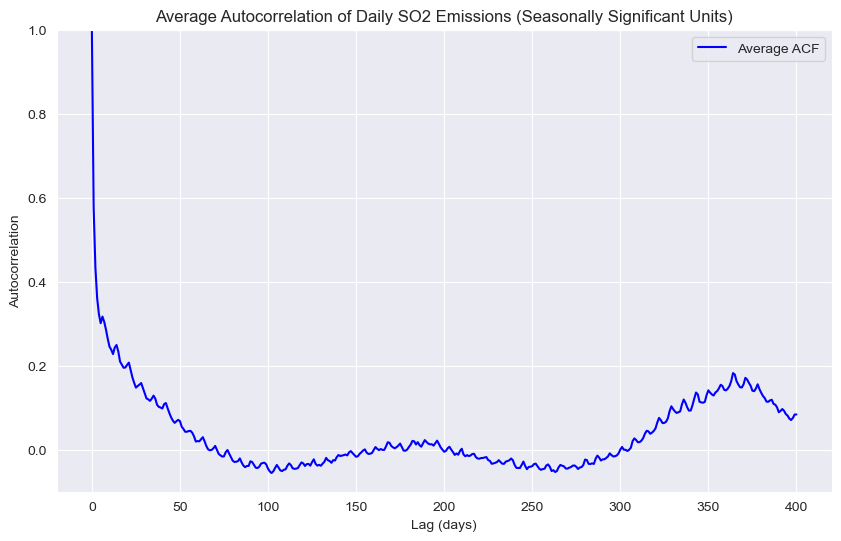

In [124]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_ny_all_hours[campd_ny_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily SO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

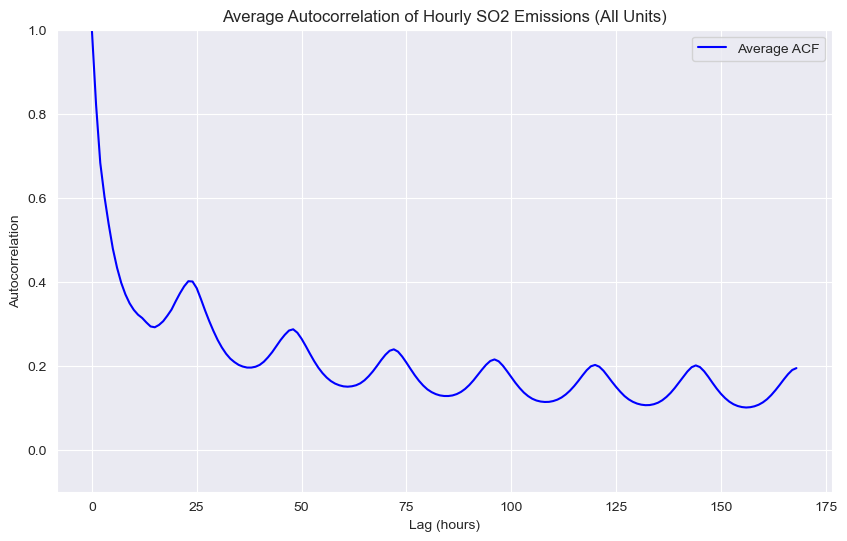

In [123]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h5>Wyoming</h5>

<h6>CO2</h6>

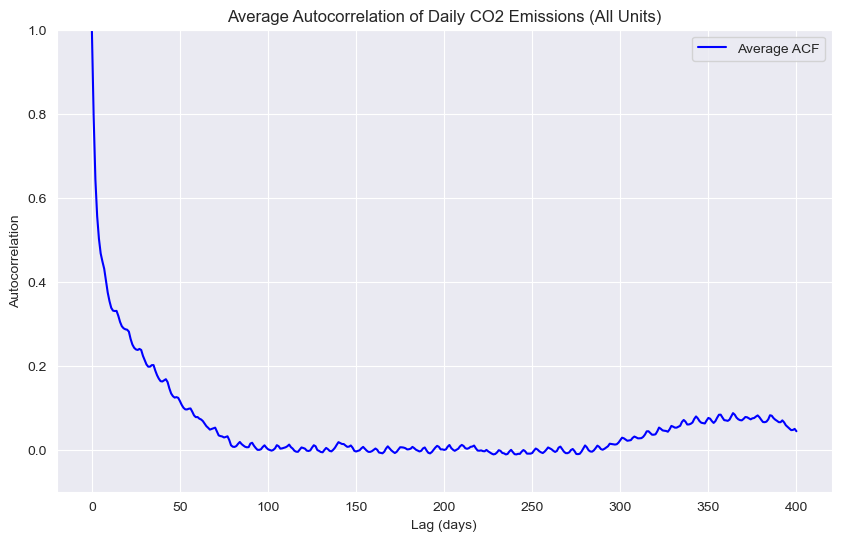

In [125]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit CO2
sample_units = campd_wy_all_hours[campd_wy_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [126]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(4162, '1'), (55477, 'CT2')]
Of a total  25  units,  2  have a significant seasonality


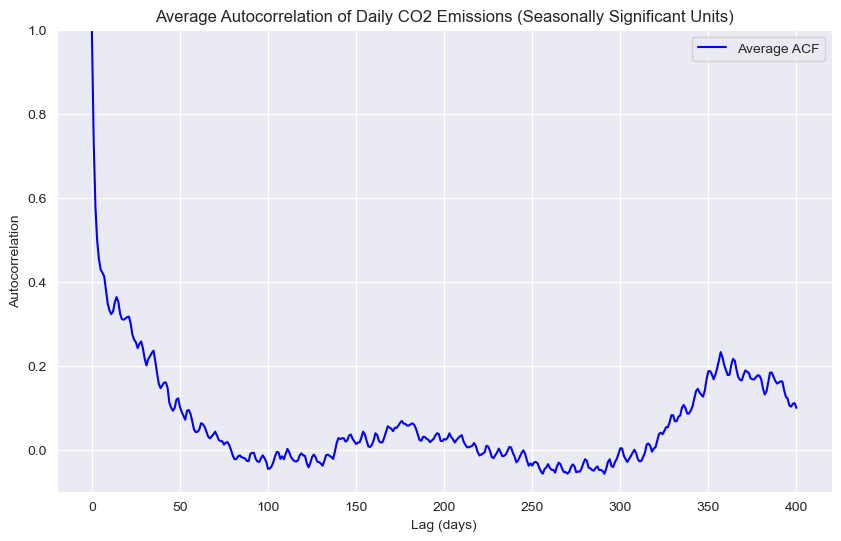

In [127]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_wy_all_hours[campd_wy_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

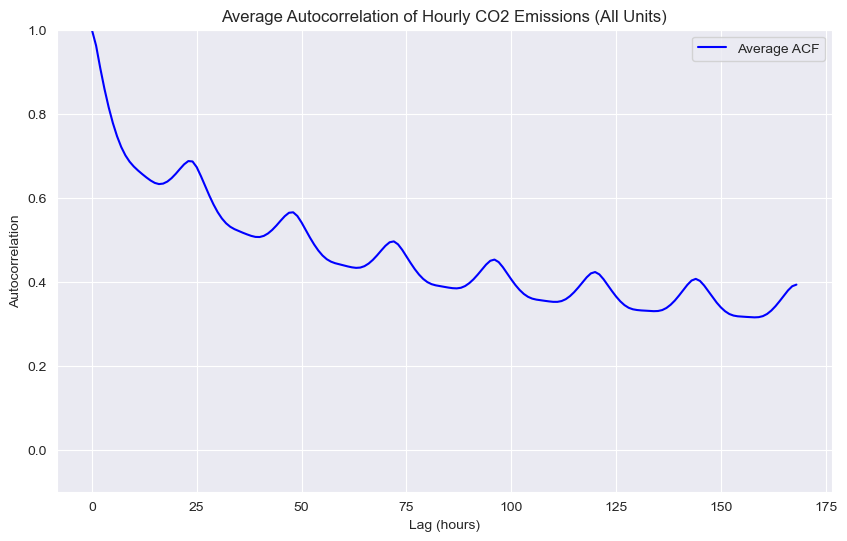

In [128]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='CO2 Mass (short tons)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

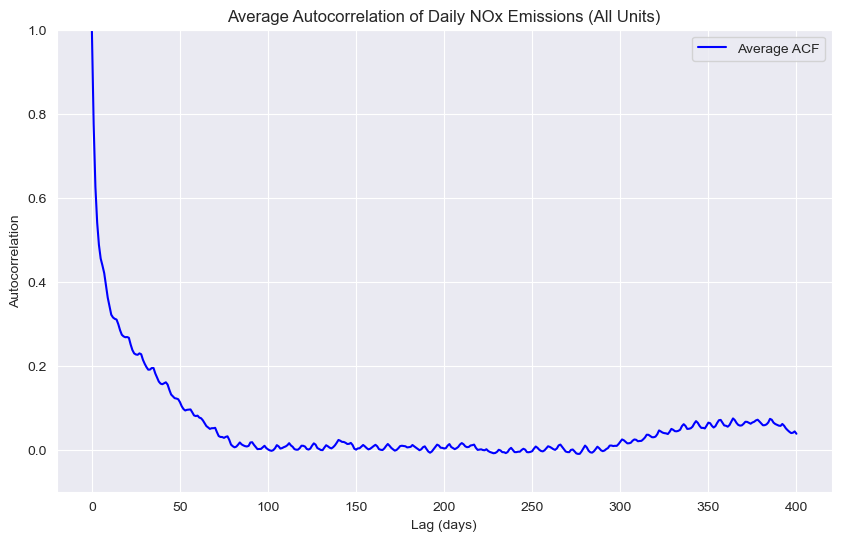

In [129]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_wy_all_hours[campd_wy_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [130]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(55477, 'CT2')]
Of a total  25  units,  1  have a significant seasonality


In [147]:
print(np.array(confidence_intervals_list).shape)

print(np.array(acf_values_list).shape)

(1, 401, 2)
(1, 401)


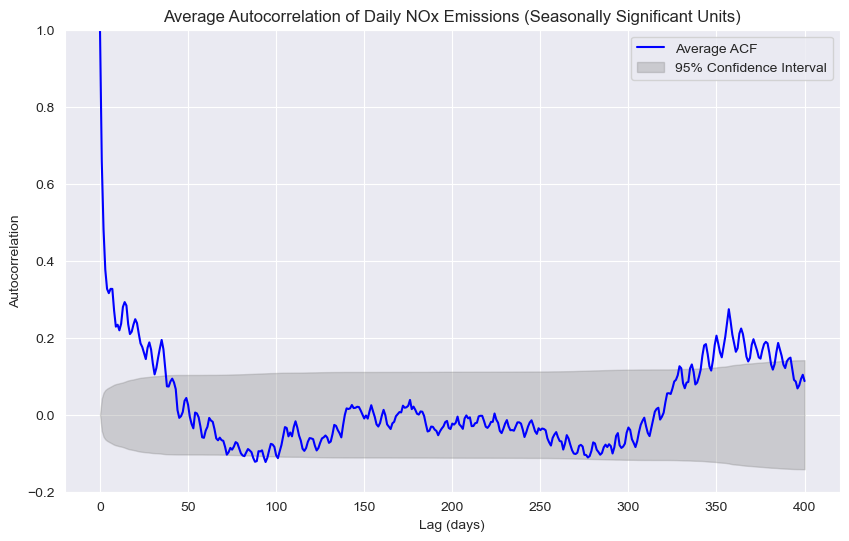

In [ ]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_wy_all_hours[campd_wy_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# since there is only one unit, we can just add the raw confidence intervals to the plot
lower_conf = np.mean([conf[:, 0] - acf for conf, acf in zip(confidence_intervals_list, acf_values_list)], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - acf for conf, acf in zip(confidence_intervals_list, acf_values_list)], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(acf_values)), acf_values, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(acf_values)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.2, 1)
plt.legend()
plt.grid(True)
plt.show()

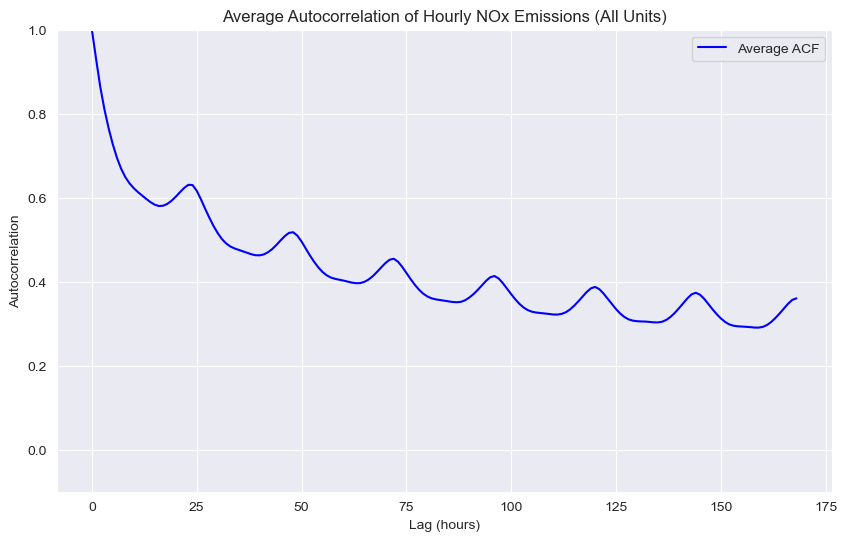

In [152]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

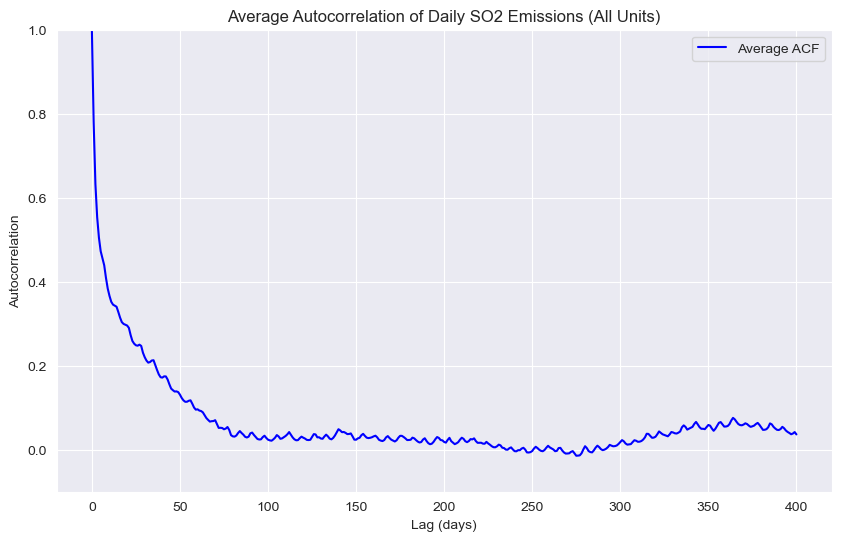

In [153]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit SO2
sample_units = campd_wy_all_hours[campd_wy_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

In [154]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lag 365
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Units with significant ACF values at lag 365: [(55477, 'CT2')]
Of a total  25  units,  1  have a significant seasonality


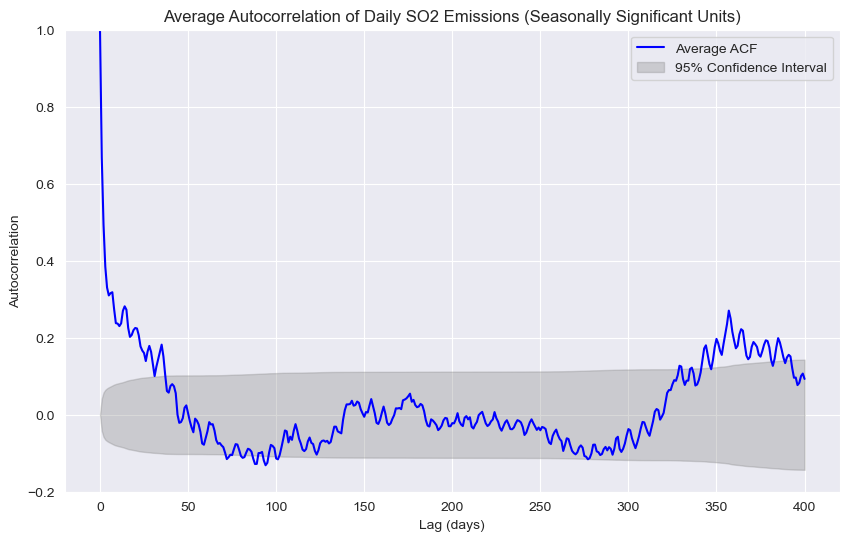

In [155]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_wy_all_hours[campd_wy_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# since there is only one unit, we can just add the raw confidence intervals to the plot
lower_conf = np.mean([conf[:, 0] - acf for conf, acf in zip(confidence_intervals_list, acf_values_list)], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - acf for conf, acf in zip(confidence_intervals_list, acf_values_list)], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(acf_values)), acf_values, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(acf_values)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily SO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.2, 1)
plt.legend()
plt.grid(True)
plt.show()

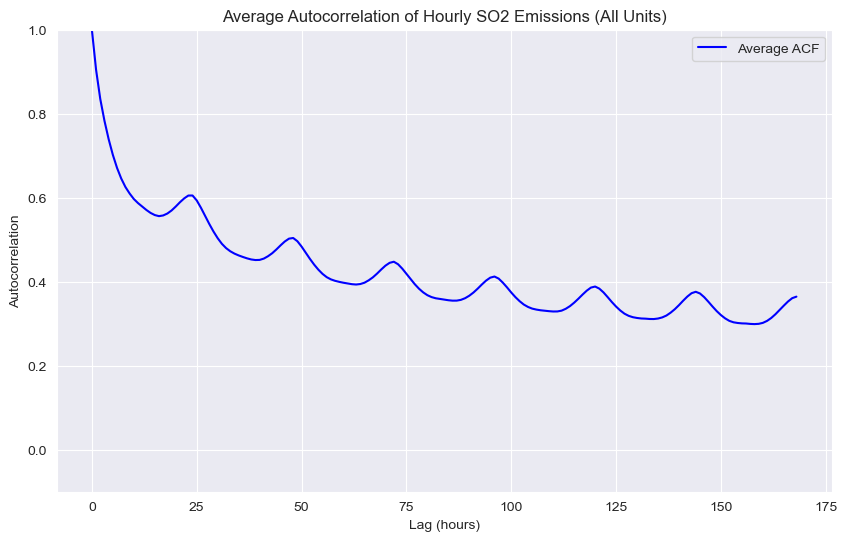

In [156]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at alpha 0.05
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation
average_acf = np.mean(acf_values_list, axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-0.1, 1)
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h3>Rel. Freq. NOx Controls</h3>

- manually one-hot-encode NOx controls (split strings in the NOx controls column. need a large function to do this since separators vary)
- create a plot to compare relative frequency of NOx controls in hourly datasets between states

In [158]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # create a df from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use


In [159]:
campd_ny_processed, ny_control_cols = preprocess_nox_controls(campd_ny)
campd_tx_processed, tx_control_cols = preprocess_nox_controls(campd_tx)
campd_wy_processed, wy_control_cols = preprocess_nox_controls(campd_wy)

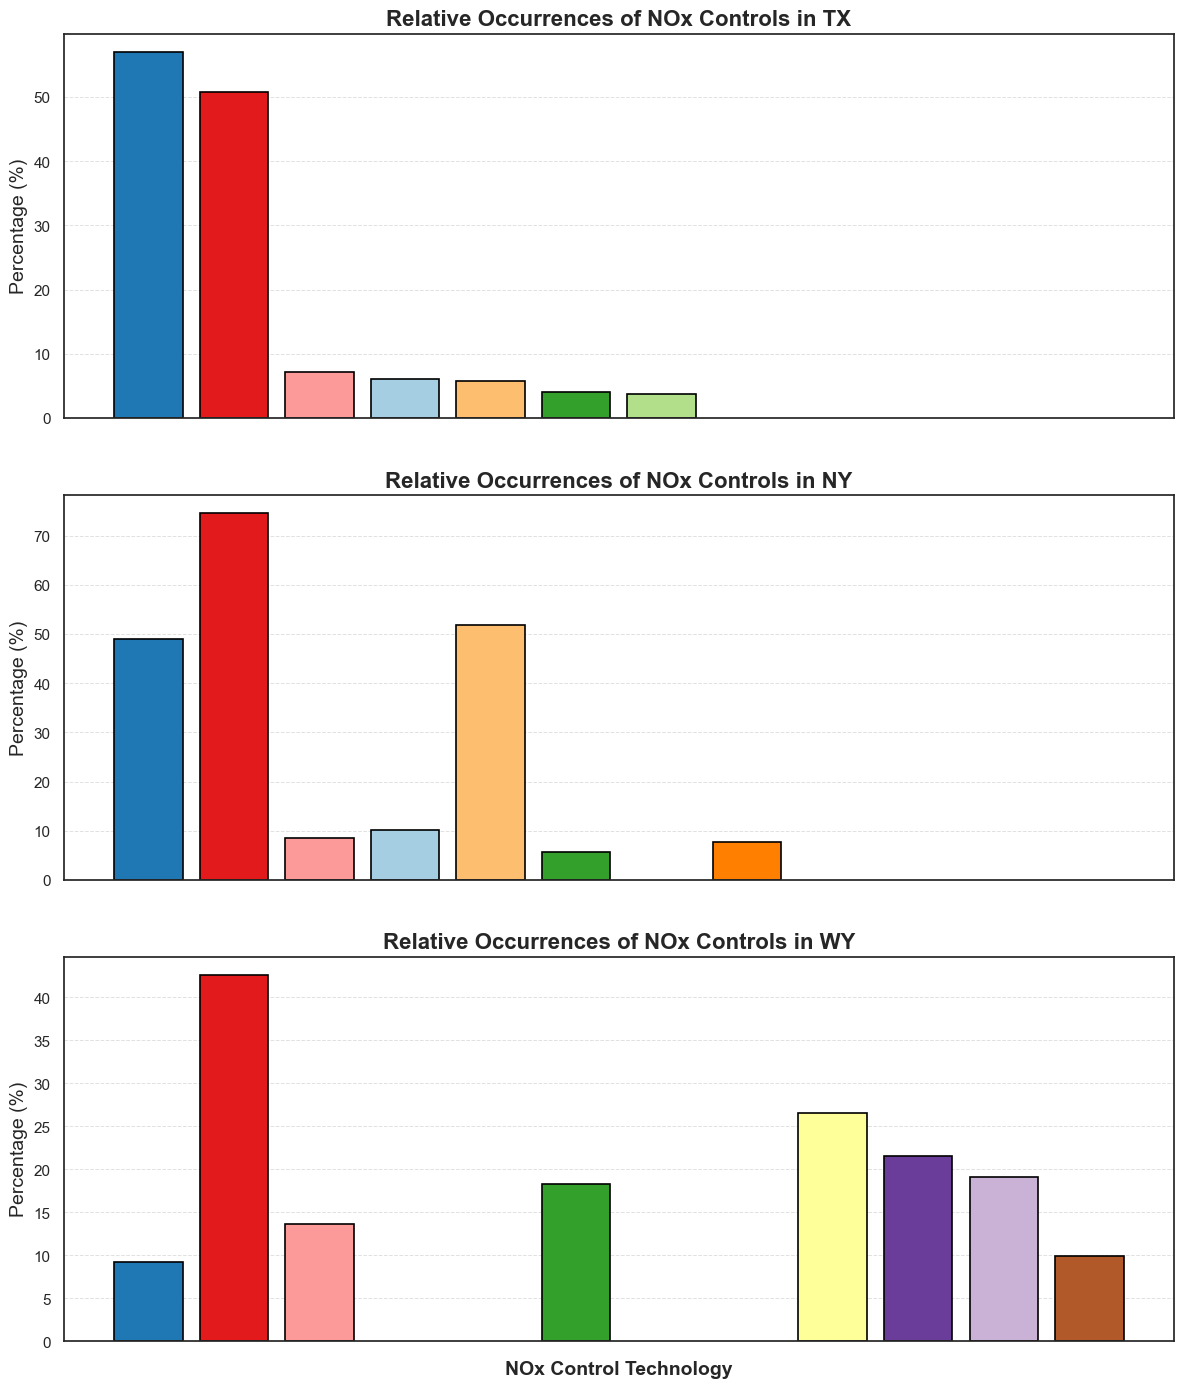

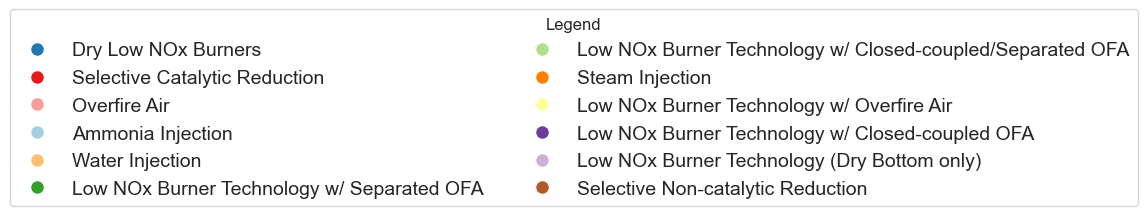

In [ ]:
# Compute percentage occurrence of each NOx control among those with controls
def compute_control_percentages(df, control_columns):
    df = df[df["Nothing"] != 1]  # Exclude rows without NOx controls
    
    percentages = df[control_columns].mean() * 100
    return pd.DataFrame({
        'Control Name': percentages.index,
        'Percentage': percentages.values
    })

# Calculate percentages from one-hot encoded DataFrames
nox_df_tx = compute_control_percentages(campd_tx_processed, tx_control_cols)
nox_df_ny = compute_control_percentages(campd_ny_processed, ny_control_cols)
nox_df_wy = compute_control_percentages(campd_wy_processed, wy_control_cols)

# Apply threshold (for better visibility, we exclude controls that appear in less than 3% of the rows)
min_threshold = 3.0
filtered_dfs = {
    "TX": nox_df_tx[nox_df_tx['Percentage'] >= min_threshold],
    "NY": nox_df_ny[nox_df_ny['Percentage'] >= min_threshold],
    "WY": nox_df_wy[nox_df_wy['Percentage'] >= min_threshold]
}

# Get all unique control names
all_controls = pd.concat([df["Control Name"] for df in filtered_dfs.values()]).unique()

# Define consistent color mapping
colors = plt.colormaps["Paired"](range(len(all_controls)))
color_map = {control: colors[i] for i, control in enumerate(all_controls)}

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

for (title, df), ax in zip(filtered_dfs.items(), axes):
    df_sorted = df.sort_values(by="Percentage", ascending=False)
    
    bars = ax.bar(
        df_sorted["Control Name"], df_sorted["Percentage"],
        color=[color_map[control] for control in df_sorted["Control Name"]],
        edgecolor="black", linewidth=1.2
    )
    
    ax.set_title(f"Relative Occurrences of NOx Controls in {title}", fontsize=16, fontweight="bold")
    ax.set_ylabel("Percentage (%)", fontsize=14)
    ax.tick_params(axis="x", rotation=45, labelsize=12)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.6)
    ax.set_xticklabels([])  # suppress individual x-axis labels

# Improve spacing
plt.tight_layout()
plt.subplots_adjust(bottom=0.25, hspace=0.2)
plt.xlabel("NOx Control Technology", fontsize=14, fontweight='bold')
plt.show()

# Sort controls for legend (sequentially by percentage in TX, NY, WY)
legend_controls_sorted = []
def add_unique_values(df):
    df= df.sort_values(by='Percentage', ascending=False)
    for name in df["Control Name"]:
        if name not in legend_controls_sorted:
            legend_controls_sorted.append(name)
add_unique_values(nox_df_tx[nox_df_tx["Percentage"] >= 3])
add_unique_values(nox_df_ny[nox_df_ny["Percentage"] >= 3])
add_unique_values(nox_df_wy[nox_df_wy["Percentage"] >= 3])

# Legend as separate figure
legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=color_map[control], markersize=10)
    for control in legend_controls_sorted
]
fig_legend = plt.figure(figsize=(10, 2))
plt.legend(
    legend_handles, legend_controls_sorted, title="Legend",
    bbox_to_anchor=(0.5, 0.5), loc="center", fontsize=14, ncol=2
)
plt.axis("off")
plt.show()

<h3>Unit Type Energy Contribution</h3>

- create pie charts for the relative contribution to gross load by unit type

In [34]:
# function to calc relative unit type frequencies based on a col to normalize by e. g. Gross Load
def get_unit_type_relative_freq(df, col_to_normalize_by):
    # group by unit type and sum for each unit type
    unit_type_sum = df.groupby('Unit Type')[col_to_normalize_by].sum()

    # normalize by the total sum for the state
    total_sum = unit_type_sum.sum()
    unit_type_relative_sum = unit_type_sum / total_sum
    
    # sort values in desc
    return unit_type_relative_sum.sort_values(ascending=False)

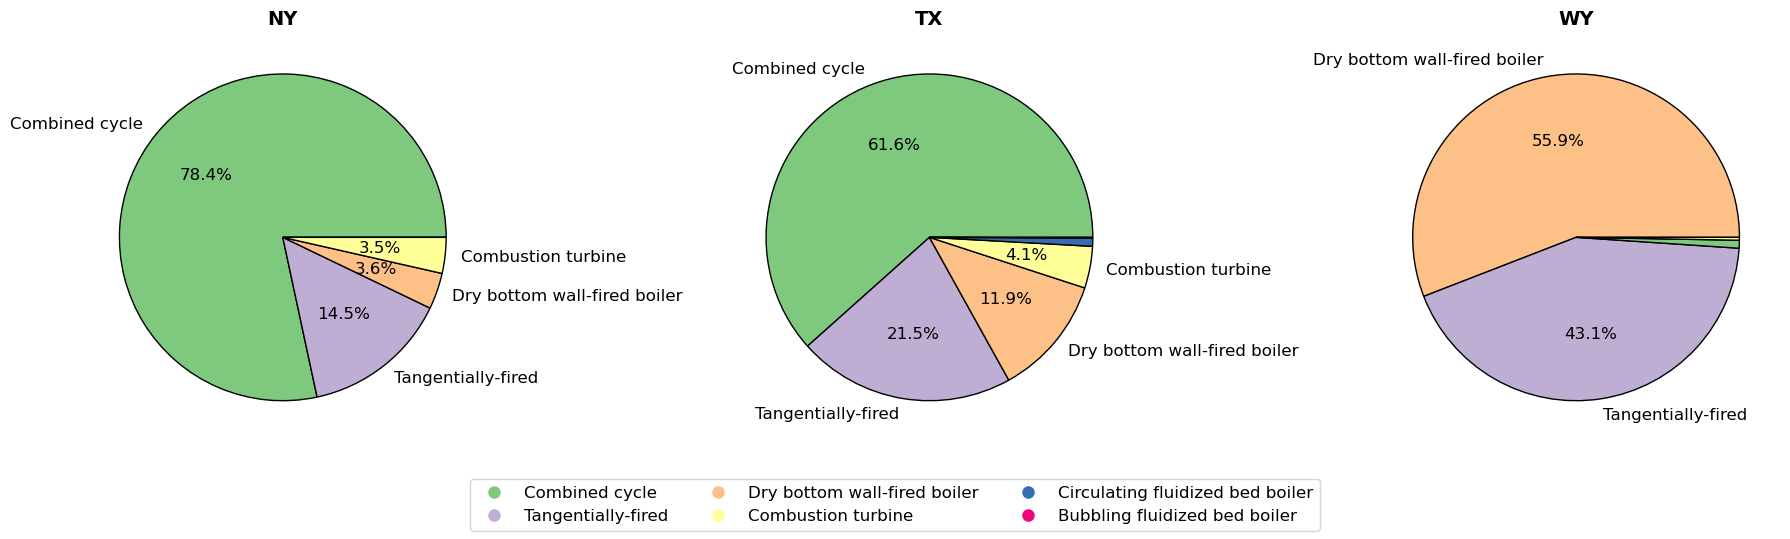

In [ ]:
# calc rel. freq. for each df
unit_type_counts_ny = get_unit_type_relative_freq(campd_ny, "Gross Load (MW)")
unit_type_counts_tx = get_unit_type_relative_freq(campd_tx, "Gross Load (MW)")
unit_type_counts_wy = get_unit_type_relative_freq(campd_wy, "Gross Load (MW)")

# combine dfs
all_unit_types = pd.concat([unit_type_counts_ny, unit_type_counts_tx, unit_type_counts_wy]).index.unique()

# consistent color palette
colors = plt.cm.Accent(range(len(all_unit_types)))

# map each unit type to a color
unit_type_to_color = {unit: color for unit, color in zip(all_unit_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

datasets = [
    ("NY", unit_type_counts_ny, axes[0]),
    ("TX", unit_type_counts_tx, axes[1]),
    ("WY", unit_type_counts_wy, axes[2])
]

# Function to format labels based on percentage threshold
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 2.5 else ""

# Create pie charts for each dataset
for title, unit_type_counts, ax in datasets:
    percentages = unit_type_counts.values / unit_type_counts.values.sum() * 100
    labels = [unit if pct > 2.5 else "" for unit, pct in zip(unit_type_counts.index, percentages)]  # Show names only for values >2.5%
    
    ax.pie(
        unit_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),  # Show percentages only above 1%
        colors=[unit_type_to_color[unit] for unit in unit_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12}
    )
    ax.set_title(title, fontsize=14, fontweight="bold")

# Add shared legend outside the plots
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=unit,
        markersize=10,
        markerfacecolor=unit_type_to_color[unit]
    )
    for unit in all_unit_types
]

fig.legend(
    handles=handles,
    labels=[unit for unit in all_unit_types],
    loc="lower center",
    ncol=3,
    fontsize=12
)

plt.tight_layout()
plt.show()

<h3>Fuel Type Energy Contribution</h3>

- create a pie chart for the relative contribution to gross load by fuel type

In [8]:
# Function to calculate relative fuel type frequencies based on Gross Load
def get_fuel_type_relative_counts_by_load(df):
    fuel_type_load = df.groupby('Primary Fuel Type')['Gross Load (MW)'].sum()
    total_load = fuel_type_load.sum()
    fuel_type_relative_load = fuel_type_load / total_load
    return fuel_type_relative_load.sort_values(ascending=False)

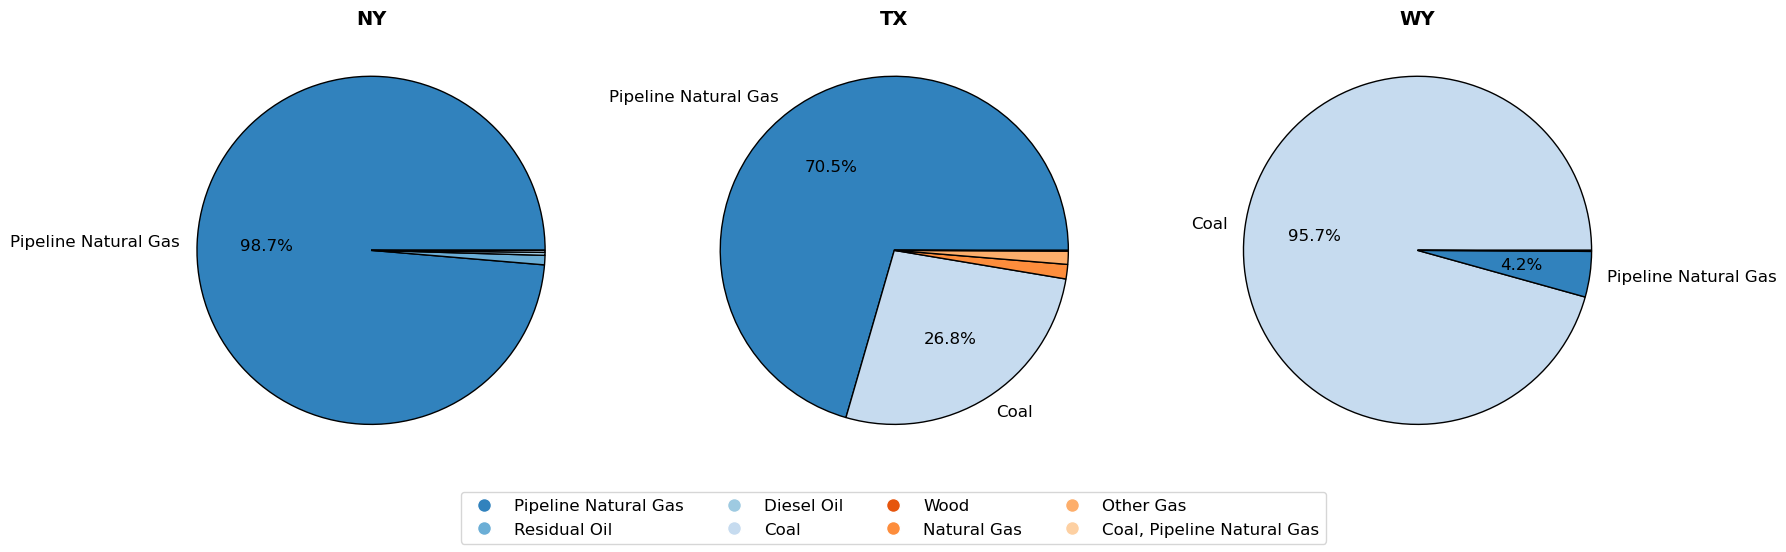

In [ ]:
# Calculate relative frequency for each state
fuel_type_counts_ny = get_fuel_type_relative_counts_by_load(campd_ny)
fuel_type_counts_tx = get_fuel_type_relative_counts_by_load(campd_tx)
fuel_type_counts_wy = get_fuel_type_relative_counts_by_load(campd_wy)

# Combine indexes to get unique fuel types across all states
all_fuel_types = pd.concat([fuel_type_counts_ny, fuel_type_counts_tx, fuel_type_counts_wy]).index.unique()

# Assign consistent colors
colors = plt.cm.tab20c(range(len(all_fuel_types)))

fuel_type_to_color = {fuel: color for fuel, color in zip(all_fuel_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Define datasets for plotting
datasets = [
    ("NY", fuel_type_counts_ny, axes[0]),
    ("TX", fuel_type_counts_tx, axes[1]),
    ("WY", fuel_type_counts_wy, axes[2])
]

# Function to show label if >%2.5
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 2.5 else ""

for title, fuel_type_counts, ax in datasets:
    percentages = fuel_type_counts.values / fuel_type_counts.values.sum() * 100
    labels = [fuel if pct > 2.5 else "" for fuel, pct in zip(fuel_type_counts.index, percentages)]
    
    ax.pie(
        fuel_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),
        colors=[fuel_type_to_color[fuel] for fuel in fuel_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12},
    )
    ax.set_title(title, fontsize=14, fontweight="bold")

# Add shared legend outside the plots
handles = [ # make the 
    plt.Line2D([0], [0], marker='o', color='w',
               label=fuel,
               markersize=10, markerfacecolor=fuel_type_to_color[fuel])
    for fuel in all_fuel_types
]
fig.legend(
    handles=handles,
    labels=[fuel for fuel in all_fuel_types],
    loc="lower center",
    ncol=4,
    fontsize=12
)

plt.tight_layout()
plt.show()


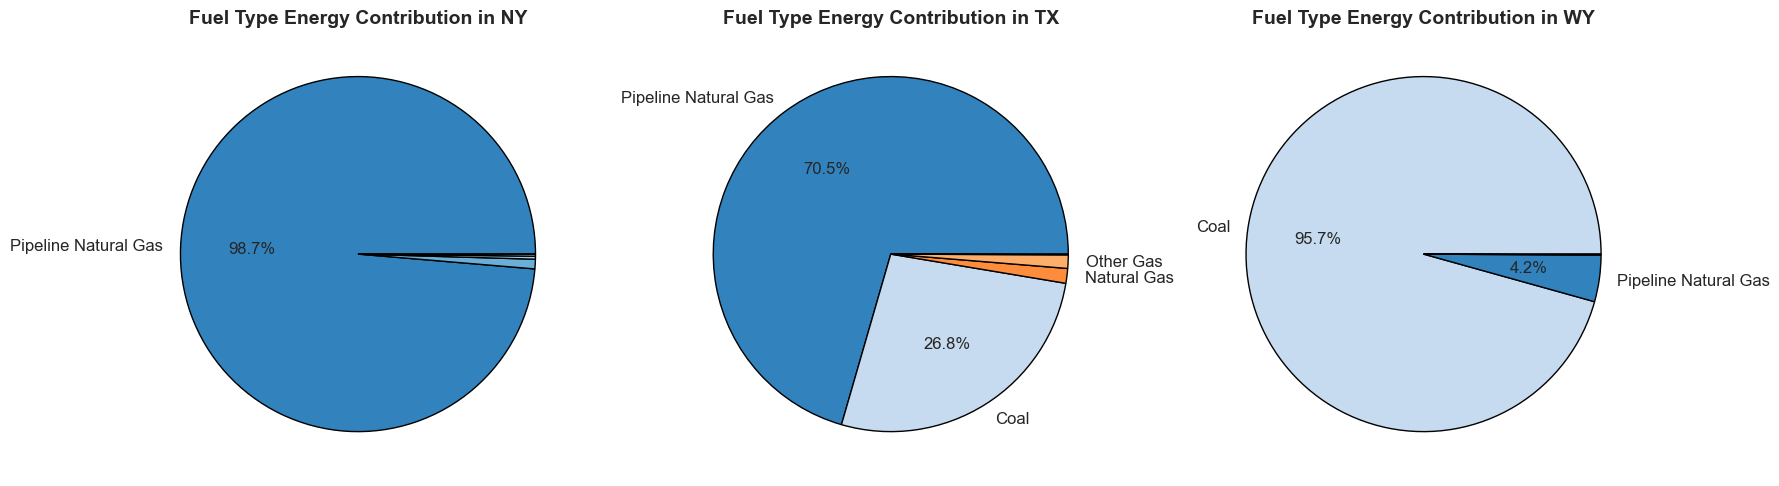

In [ ]:
# Calculate relative frequency for each state
fuel_type_counts_ny = get_fuel_type_relative_counts_by_load(campd_ny)
fuel_type_counts_tx = get_fuel_type_relative_counts_by_load(campd_tx)
fuel_type_counts_wy = get_fuel_type_relative_counts_by_load(campd_wy)

# Combine indexes to get unique fuel types across all states
all_fuel_types = pd.concat([fuel_type_counts_ny, fuel_type_counts_tx, fuel_type_counts_wy]).index.unique()

# Assign consistent colors
colors = plt.cm.tab20c(range(len(all_fuel_types)))

fuel_type_to_color = {fuel: color for fuel, color in zip(all_fuel_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Define datasets for plotting
datasets = [
    ("NY", fuel_type_counts_ny, axes[0]),
    ("TX", fuel_type_counts_tx, axes[1]),
    ("WY", fuel_type_counts_wy, axes[2])
]

# Function to show label if >%2.5
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 2,5 else ""

for title, fuel_type_counts, ax in datasets:
    percentages = fuel_type_counts.values / fuel_type_counts.values.sum() * 100
    labels = [fuel if pct > 1 else "" for fuel, pct in zip(fuel_type_counts.index, percentages)]
    
    ax.pie(
        fuel_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),
        colors=[fuel_type_to_color[fuel] for fuel in fuel_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12},
    )
    ax.set_title(f"Fuel Type Energy Contribution in {title}", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()


<h3>Scatter Plots</h3>

- create scatter plots of the variable relationships for heat input, gross load, and unit age

<h4>Heat Input</h4>

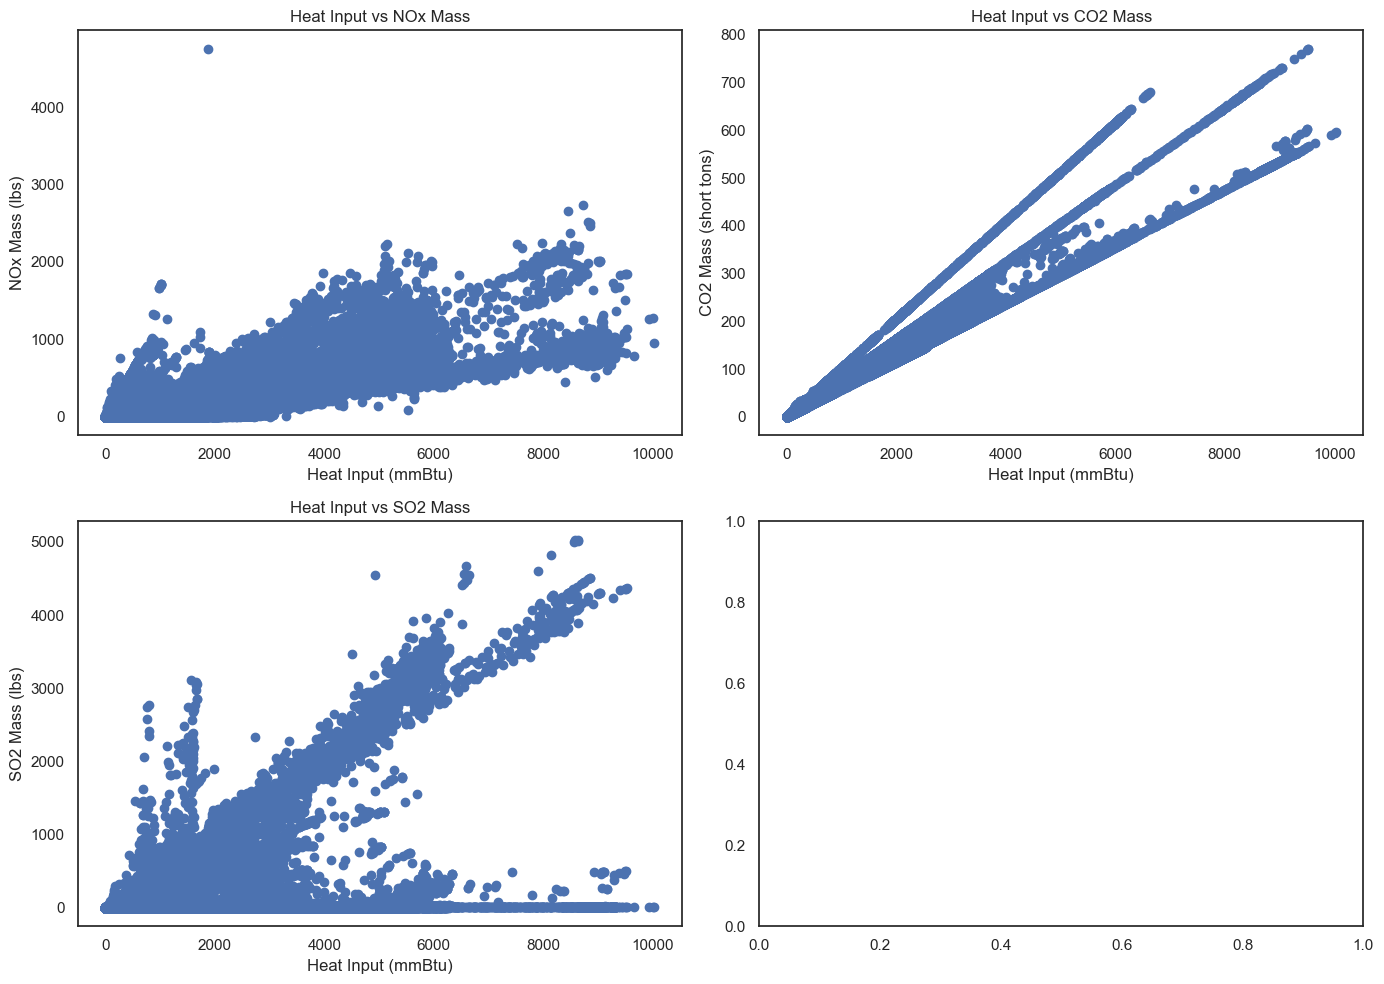

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(campd_ny['Heat Input (mmBtu)'], campd_ny['NOx Mass (lbs)'])
axes[0, 0].set_xlabel('Heat Input (mmBtu)')
axes[0, 0].set_ylabel('NOx Mass (lbs)')
axes[0, 0].set_title('Heat Input vs NOx Mass')

axes[0, 1].scatter(campd_ny['Heat Input (mmBtu)'], campd_ny['CO2 Mass (short tons)'])
axes[0, 1].set_xlabel('Heat Input (mmBtu)')
axes[0, 1].set_ylabel('CO2 Mass (short tons)')
axes[0, 1].set_title('Heat Input vs CO2 Mass')

axes[1, 0].scatter(campd_ny['Heat Input (mmBtu)'], campd_ny['SO2 Mass (lbs)'])
axes[1, 0].set_xlabel('Heat Input (mmBtu)')
axes[1, 0].set_ylabel('SO2 Mass (lbs)')
axes[1, 0].set_title('Heat Input vs SO2 Mass')

plt.tight_layout()
plt.show()

# we can see just how linear the relationships between HI and CO2 are, similarly with SO2 
# NOx shows the least directly linear relationship


<h4>Gross Load</h4>

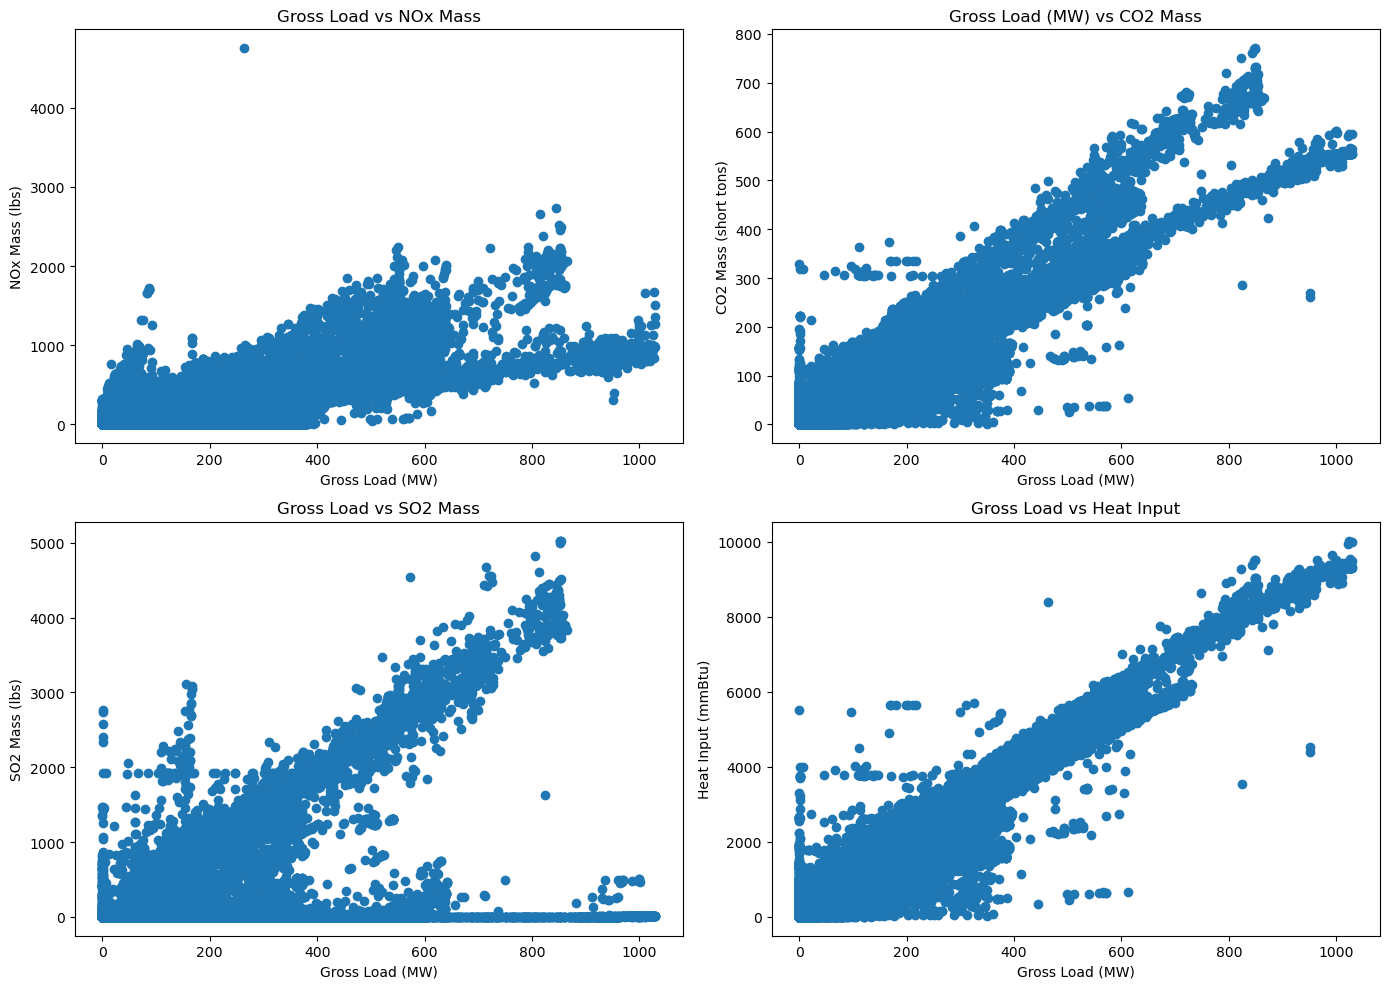

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(campd_ny['Gross Load (MW)'], campd_ny['NOx Mass (lbs)'])
axes[0, 0].set_xlabel('Gross Load (MW)')
axes[0, 0].set_ylabel('NOx Mass (lbs)')
axes[0, 0].set_title('Gross Load vs NOx Mass')

axes[0, 1].scatter(campd_ny['Gross Load (MW)'], campd_ny['CO2 Mass (short tons)'])
axes[0, 1].set_xlabel('Gross Load (MW)')
axes[0, 1].set_ylabel('CO2 Mass (short tons)')
axes[0, 1].set_title('Gross Load (MW) vs CO2 Mass')

axes[1, 0].scatter(campd_ny['Gross Load (MW)'], campd_ny['SO2 Mass (lbs)'])
axes[1, 0].set_xlabel('Gross Load (MW)')
axes[1, 0].set_ylabel('SO2 Mass (lbs)')
axes[1, 0].set_title('Gross Load vs SO2 Mass')

axes[1, 1].scatter(campd_ny['Gross Load (MW)'], campd_ny['Heat Input (mmBtu)'])
axes[1, 1].set_xlabel('Gross Load (MW)')
axes[1, 1].set_ylabel('Heat Input (mmBtu)')
axes[1, 1].set_title('Gross Load vs Heat Input')

plt.tight_layout()
plt.show()


<h4>Unit Age</h4>

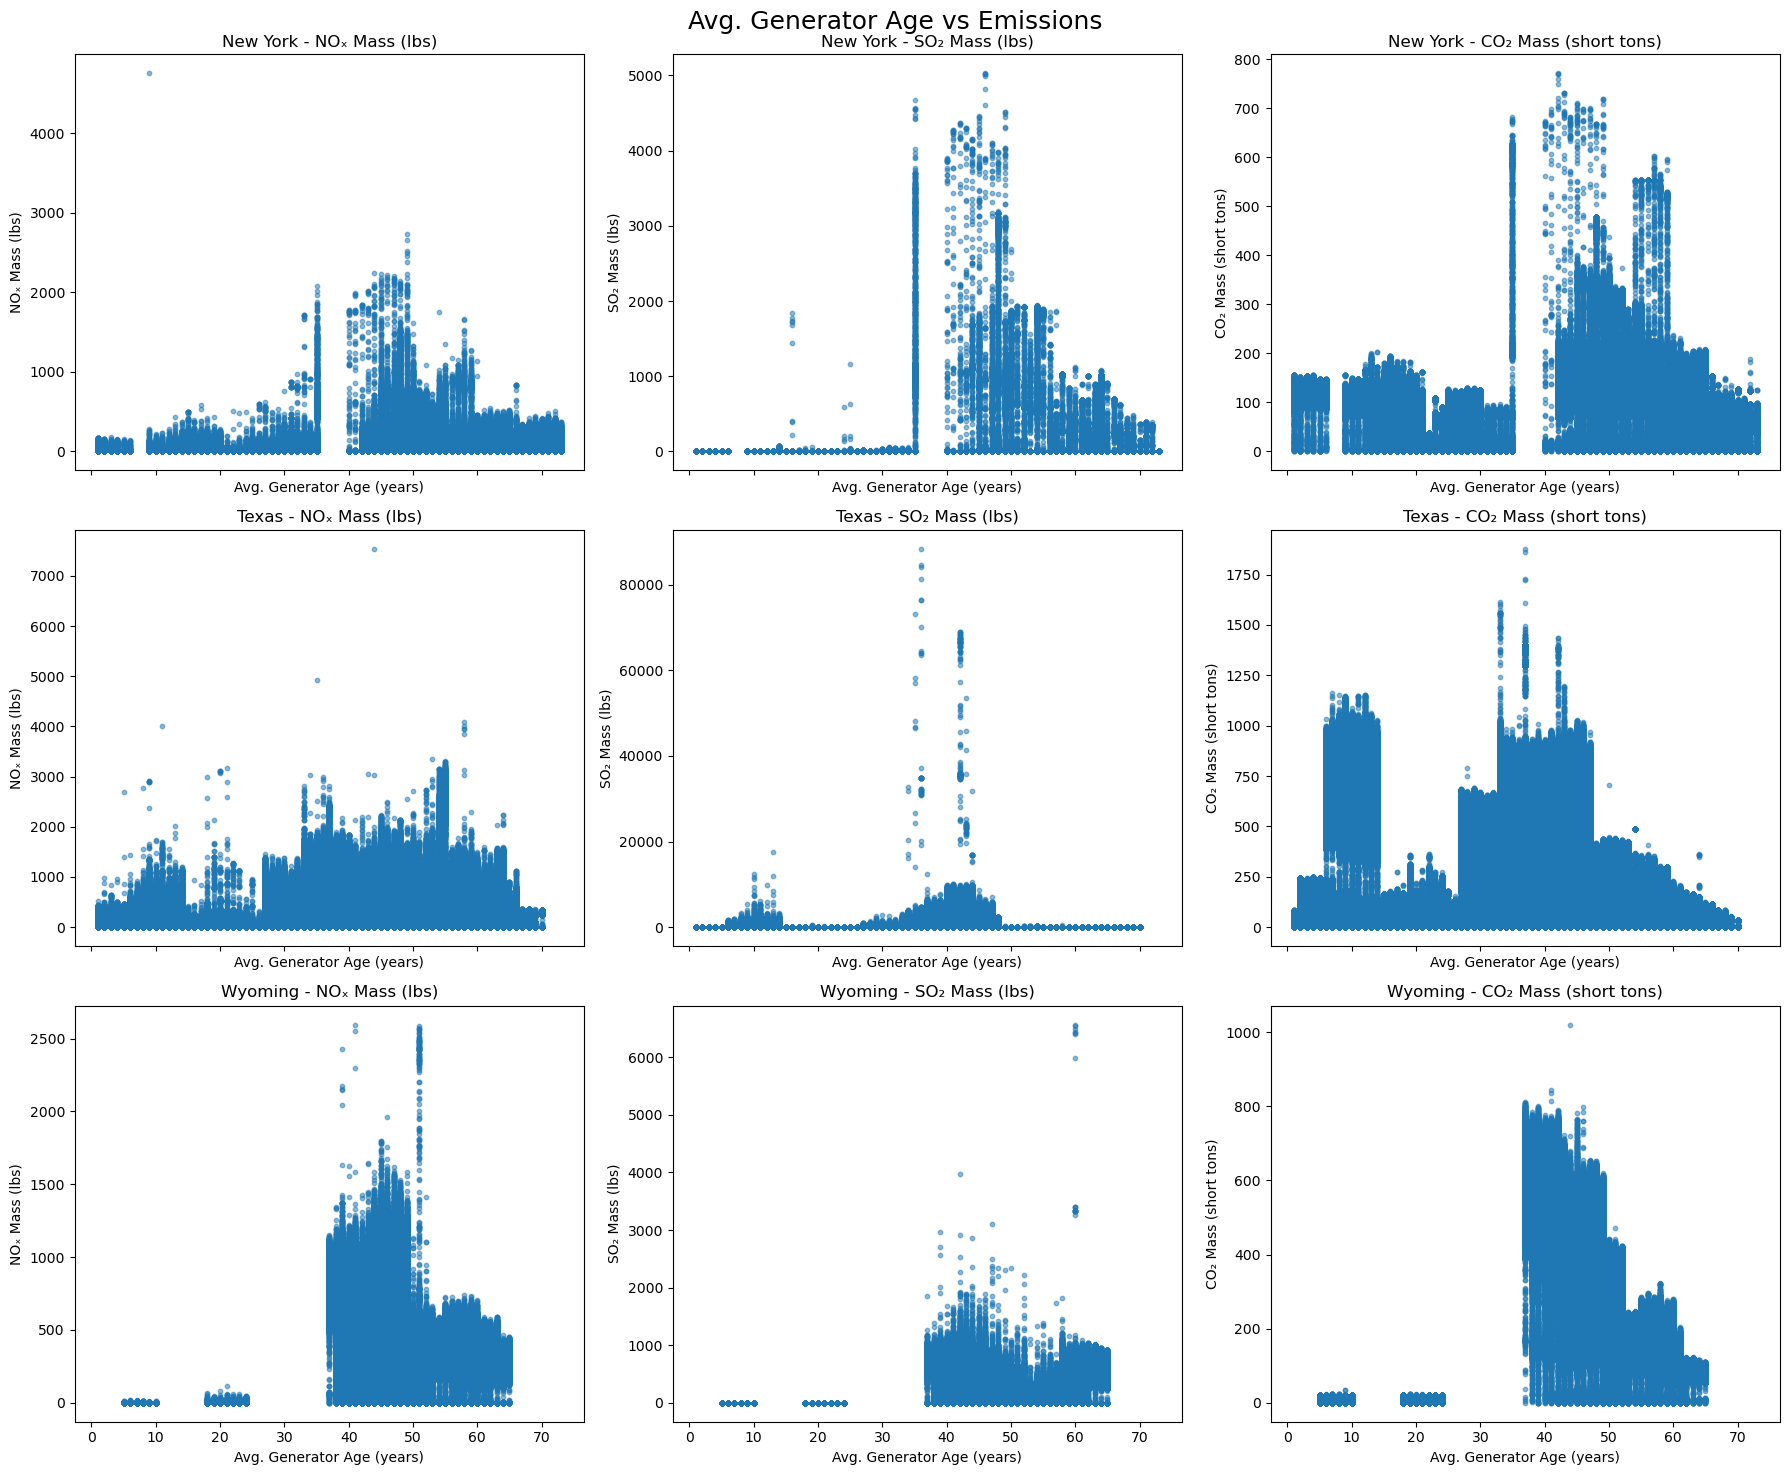

In [ ]:
states_data = {
    "New York": campd_ny,
    "Texas": campd_tx,
    "Wyoming": campd_wy
}

emissions = [
    ("NOx Mass (lbs)", "NOₓ Mass (lbs)"),
    ("SO2 Mass (lbs)", "SO2 Mass (lbs)"),
    ("CO2 Mass (short tons)", "CO2 Mass (short tons)")
]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15), sharex=True)
fig.suptitle("Avg. Generator Age vs Emissions", fontsize=18)

for i, (state_name, df) in enumerate(states_data.items()):
    for j, (em_col, em_label) in enumerate(emissions):
        ax = axes[i, j]
        ax.scatter(df["unit_age_mean"], df[em_col], alpha=0.5, s=10)
        ax.set_title(f"{state_name} - {em_label}")
        ax.set_xlabel("Avg. Generator Age (years)")
        ax.set_ylabel(em_label)

plt.tight_layout()
plt.show()

In [ ]:
# distribution of mean generator age is unlikely to be a good (causal) predictor
# we find little evidence of the expected positive relationship between age and emissions
# instead specific ages show major vertical spikes
# -> would therefore probably act as more of a proxy for facility or unit id

<h3>Top Emitting Facilities</h3>

- plot the top emitting facilities per state and emission type (only CO2 is included here)

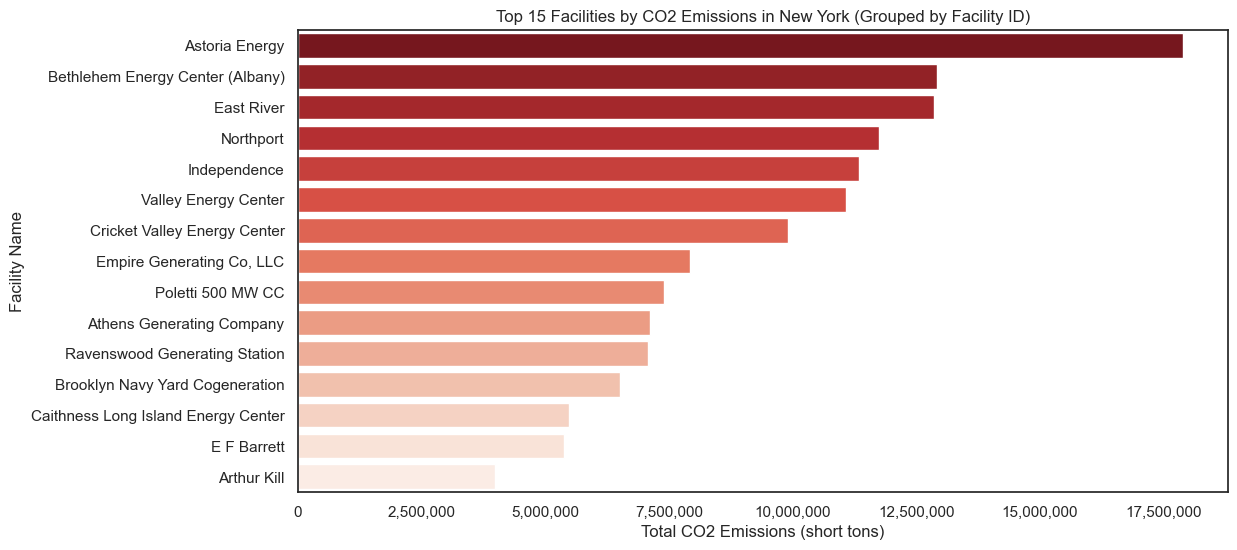

In [ ]:
# Top emitters by facility

facility_co2 = campd_ny.groupby("Facility ID")["CO2 Mass (short tons)"].sum().reset_index()

latest_facility_names = campd_ny.sort_values(by="Year", ascending=False).drop_duplicates(subset="Facility ID")[["Facility ID", "Facility Name"]]

facility_co2 = facility_co2.merge(latest_facility_names, on="Facility ID", how="left")

facility_co2 = facility_co2.sort_values(by="CO2 Mass (short tons)", ascending=False).head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x="CO2 Mass (short tons)",
    y="Facility Name",
    hue="Facility Name", 
    data=facility_co2,
    palette="Reds_r",
    legend=False 
)

# Format x-axis with commas
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.xlabel("Total CO2 Emissions (short tons)")
plt.ylabel("Facility Name")
plt.title("Top 15 Facilities by CO2 Emissions in New York (Grouped by Facility ID)")
plt.show()

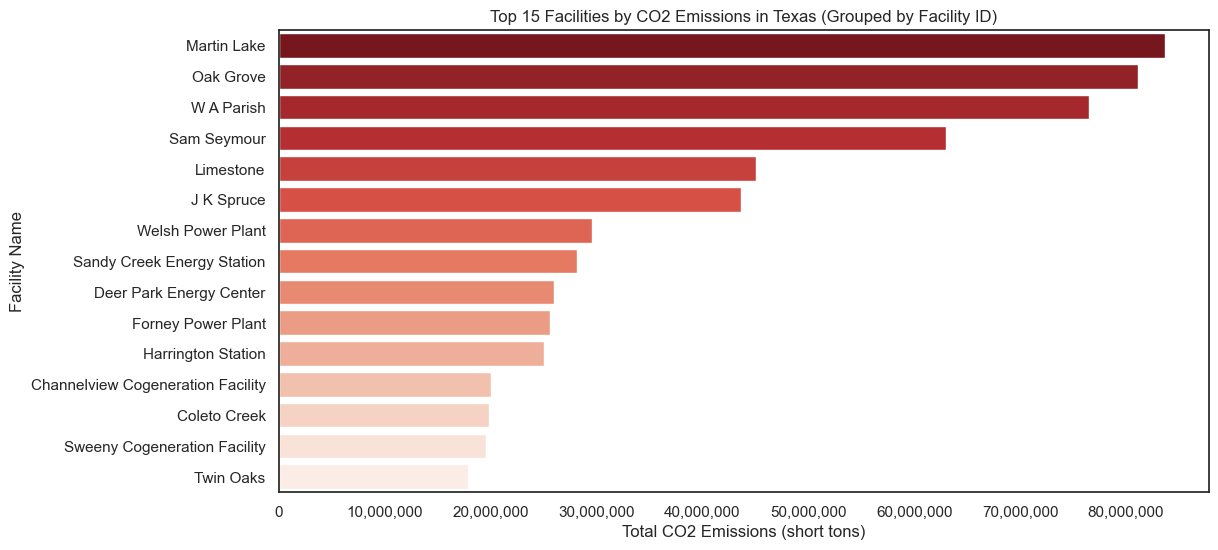

In [182]:
# Top emitters by facility

facility_co2 = campd_tx.groupby("Facility ID")["CO2 Mass (short tons)"].sum().reset_index()

latest_facility_names = campd_tx.sort_values(by="Year", ascending=False).drop_duplicates(subset="Facility ID")[["Facility ID", "Facility Name"]]

facility_co2 = facility_co2.merge(latest_facility_names, on="Facility ID", how="left")

facility_co2 = facility_co2.sort_values(by="CO2 Mass (short tons)", ascending=False).head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x="CO2 Mass (short tons)",
    y="Facility Name",
    hue="Facility Name", 
    data=facility_co2,
    palette="Reds_r",
    legend=False 
)

# Format x-axis with commas
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.xlabel("Total CO2 Emissions (short tons)")
plt.ylabel("Facility Name")
plt.title("Top 15 Facilities by CO2 Emissions in Texas (Grouped by Facility ID)")
plt.show()

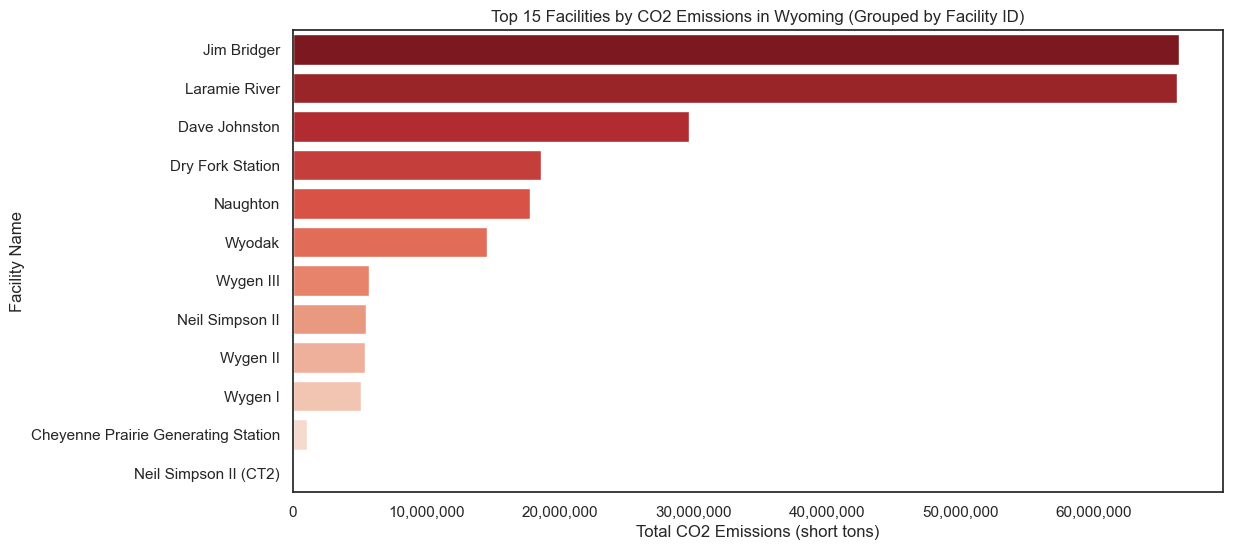

In [ ]:
# Top emitters by facility

facility_co2 = campd_wy.groupby("Facility ID")["CO2 Mass (short tons)"].sum().reset_index()

latest_facility_names = campd_wy.sort_values(by="Year", ascending=False).drop_duplicates(subset="Facility ID")[["Facility ID", "Facility Name"]]

facility_co2 = facility_co2.merge(latest_facility_names, on="Facility ID", how="left")

facility_co2 = facility_co2.sort_values(by="CO2 Mass (short tons)", ascending=False).head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x="CO2 Mass (short tons)",
    y="Facility Name",
    hue="Facility Name", 
    data=facility_co2,
    palette="Reds_r",
    legend=False 
)

# Format x-axis with commas
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.xlabel("Total CO2 Emissions (short tons)")
plt.ylabel("Facility Name")
plt.title("Facilities by CO2 Emissions in Wyoming (Grouped by Facility ID)") # there are only 12 unique facilities in wyoming
plt.show()

In [185]:
len(campd_wy["Facility ID"].unique())

12

<h3>Boxplots</h3>

- first look at general distributions of energy generation and emissions
- then plot yearly boxplots for emissions and state as well as complete boxplots for the entire year interval

In [ ]:
# TX

print("")
print(round(campd_tx[campd_tx["NOx Mass (lbs)"] <= 500]["NOx Mass (lbs)"].count() / campd_tx["NOx Mass (lbs)"].count(),2)*100, "% of NOx Mass entries are below 500 lbs")
print("")
print(round(campd_tx[campd_tx["SO2 Mass (lbs)"] <= 200]["SO2 Mass (lbs)"].count() / campd_tx["SO2 Mass (lbs)"].count(),2)*100, "% of SO2 Mass entries are below 200 lbs")
pd.reset_option('display.float_format')


,Gross Load (MW),NOx Mass (lbs),CO2 Mass (short tons),SO2 Mass (lbs)
count,9166954.00,9262325.00,9262325.00,9262325.00
mean,214.00,110.64,135.69,163.09
std,159.13,214.68,159.09,676.25
min,0.00,0.00,0.00,0.00
25%,99.00,15.70,57.80,0.57
50%,203.00,31.00,99.24,1.00
75%,267.00,67.10,122.10,1.29
max,1000.00,8746.60,1877.00,88366.60



93.0 % of NOx Mass entries are below 500 lbs

90.0 % of SO2 Mass entries are below 200 lbs


In [ ]:
# WY

print("")
print(round(campd_wy[campd_wy["NOx Mass (lbs)"] <= 500]["NOx Mass (lbs)"].count() / campd_wy["NOx Mass (lbs)"].count(),2)*100, "% of NOx Mass entries are below 500 lbs")
print("")
print(round(campd_wy[campd_wy["SO2 Mass (lbs)"] <= 200]["SO2 Mass (lbs)"].count() / campd_wy["SO2 Mass (lbs)"].count(),2)*100, "% of SO2 Mass entries are below 200 lbs")
pd.reset_option('display.float_format')


,Gross Load (MW),NOx Mass (lbs),CO2 Mass (short tons),SO2 Mass (lbs)
count,993428.00,993428.00,993428.00,993428.00
mean,216.24,305.33,237.43,305.87
std,166.89,272.30,185.05,261.52
min,0.00,0.00,0.00,0.00
25%,90.00,112.86,107.90,74.50
50%,162.00,208.39,176.00,257.80
75%,340.00,441.46,371.70,497.40
max,618.00,2595.10,1020.40,6564.70



80.0 % of NOx Mass entries are below 500 lbs

42.0 % of SO2 Mass entries are below 200 lbs


In [ ]:
# NY

print("")
print(round(campd_ny[campd_ny["NOx Mass (lbs)"] <= 500]["NOx Mass (lbs)"].count() / campd_ny["NOx Mass (lbs)"].count(),2)*100, "% of NOx Mass entries are below 500 lbs")
print("")
print(round(campd_ny[campd_ny["SO2 Mass (lbs)"] <= 200]["SO2 Mass (lbs)"].count() / campd_ny["SO2 Mass (lbs)"].count(),2)*100, "% of SO2 Mass entries are below 200 lbs")
pd.reset_option('display.float_format')


,Gross Load (MW),NOx Mass (lbs),CO2 Mass (short tons),SO2 Mass (lbs)
count,2175690.00,2400701.00,2400701.00,2400701.00
mean,154.93,36.10,71.10,7.10
std,112.18,74.30,50.30,97.49
min,0.00,0.00,0.00,0.00
25%,48.00,8.70,26.70,0.28
50%,133.00,13.30,67.80,0.73
75%,253.00,31.60,107.60,1.11
max,1030.00,4754.10,771.00,5029.30



99.0 % of NOx Mass entries are below 500 lbs

99.0 % of SO2 Mass entries are below 200 lbs


<h4>Yearly Emission Distribution</h4>

<h5>TX</h5>

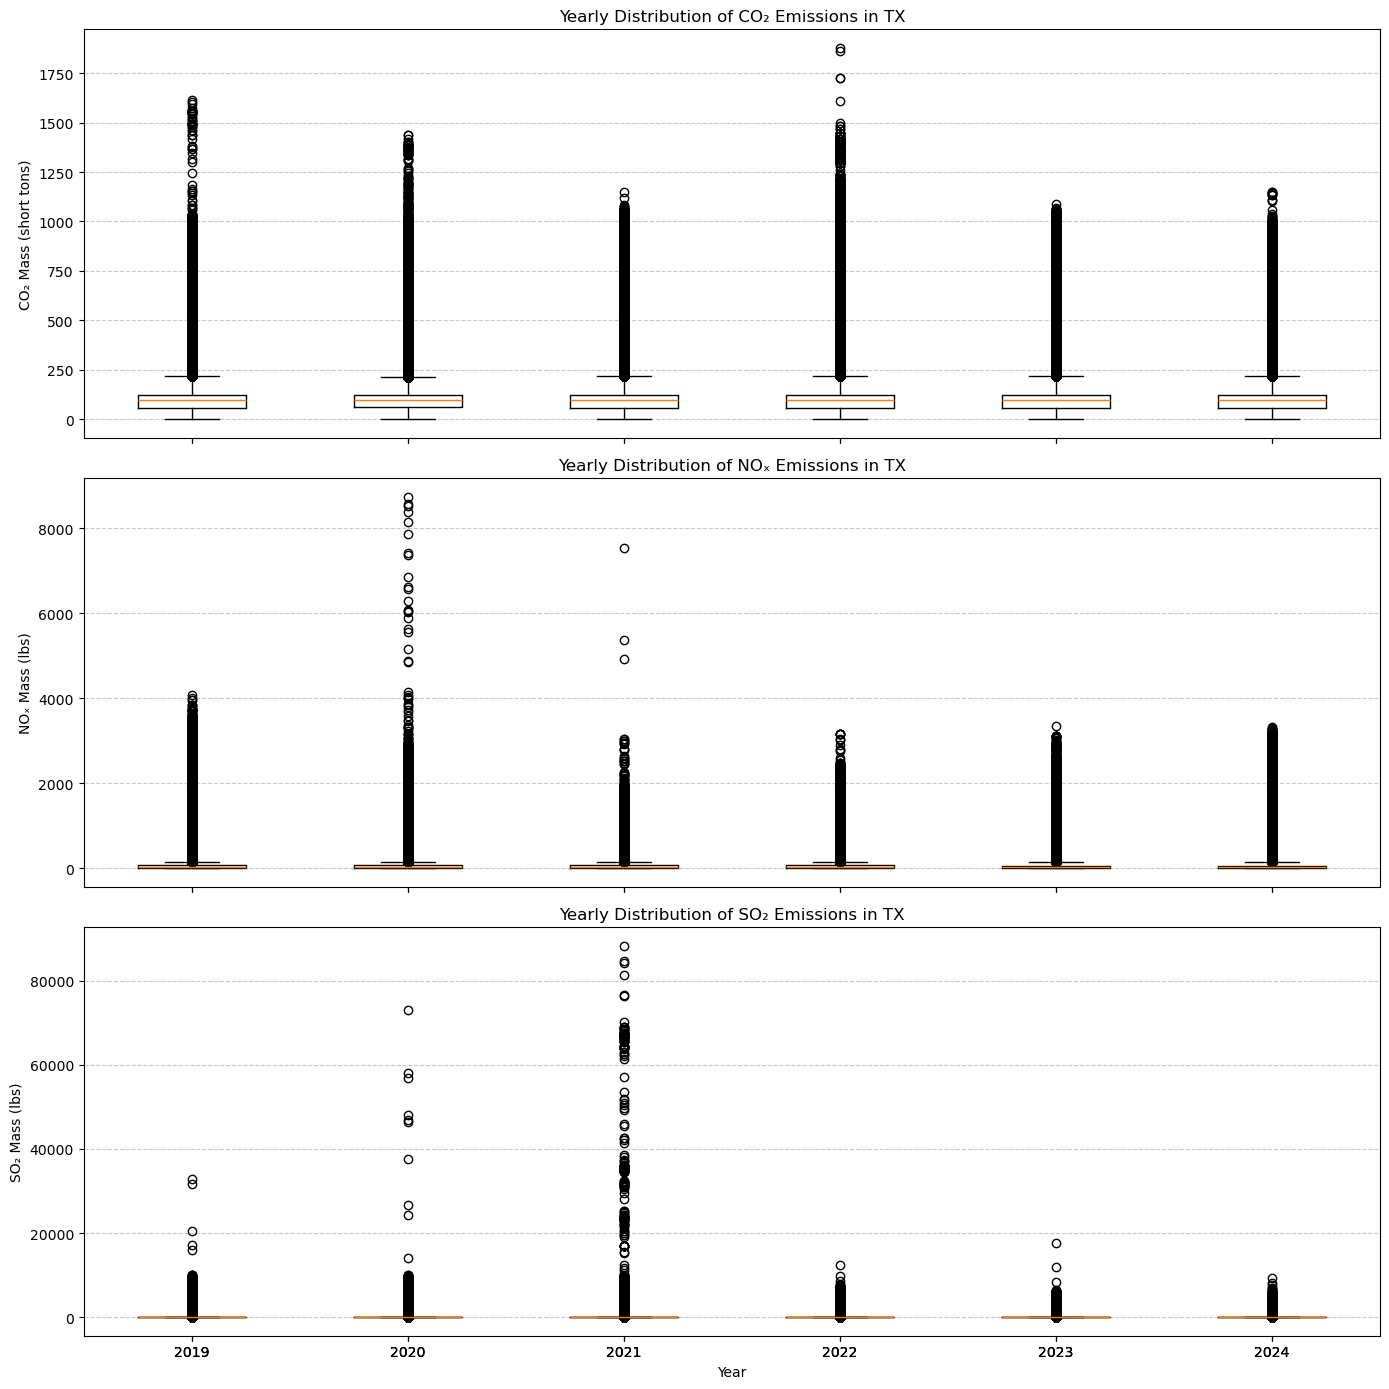

In [ ]:
df = campd_tx[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO2 Emissions in TX")
axes[0].set_ylabel("CO2 Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in TX")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO2 Emissions in TX")
axes[2].set_ylabel("SO2 Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


<h5>NY</h5>

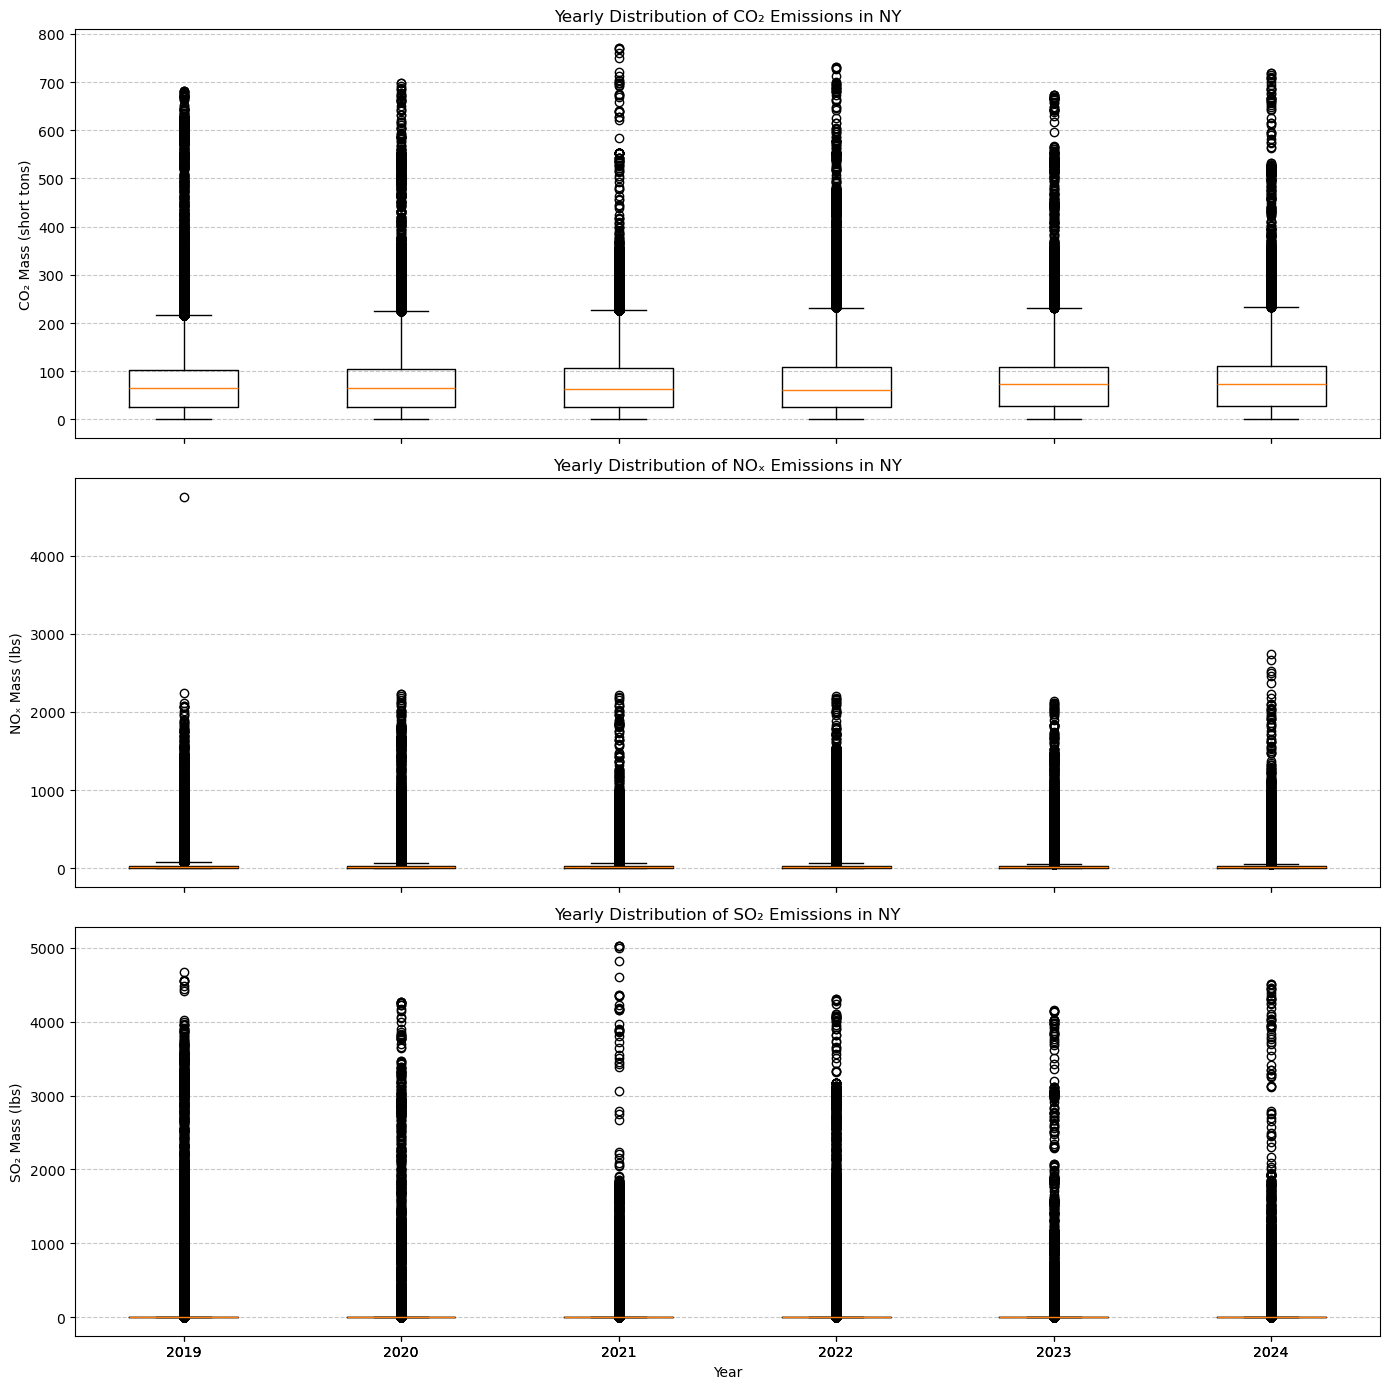

In [ ]:
df = campd_ny[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO2 Emissions in NY")
axes[0].set_ylabel("CO2 Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in NY")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO2 Emissions in NY")
axes[2].set_ylabel("SO2 Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


<h5>WY</h5>

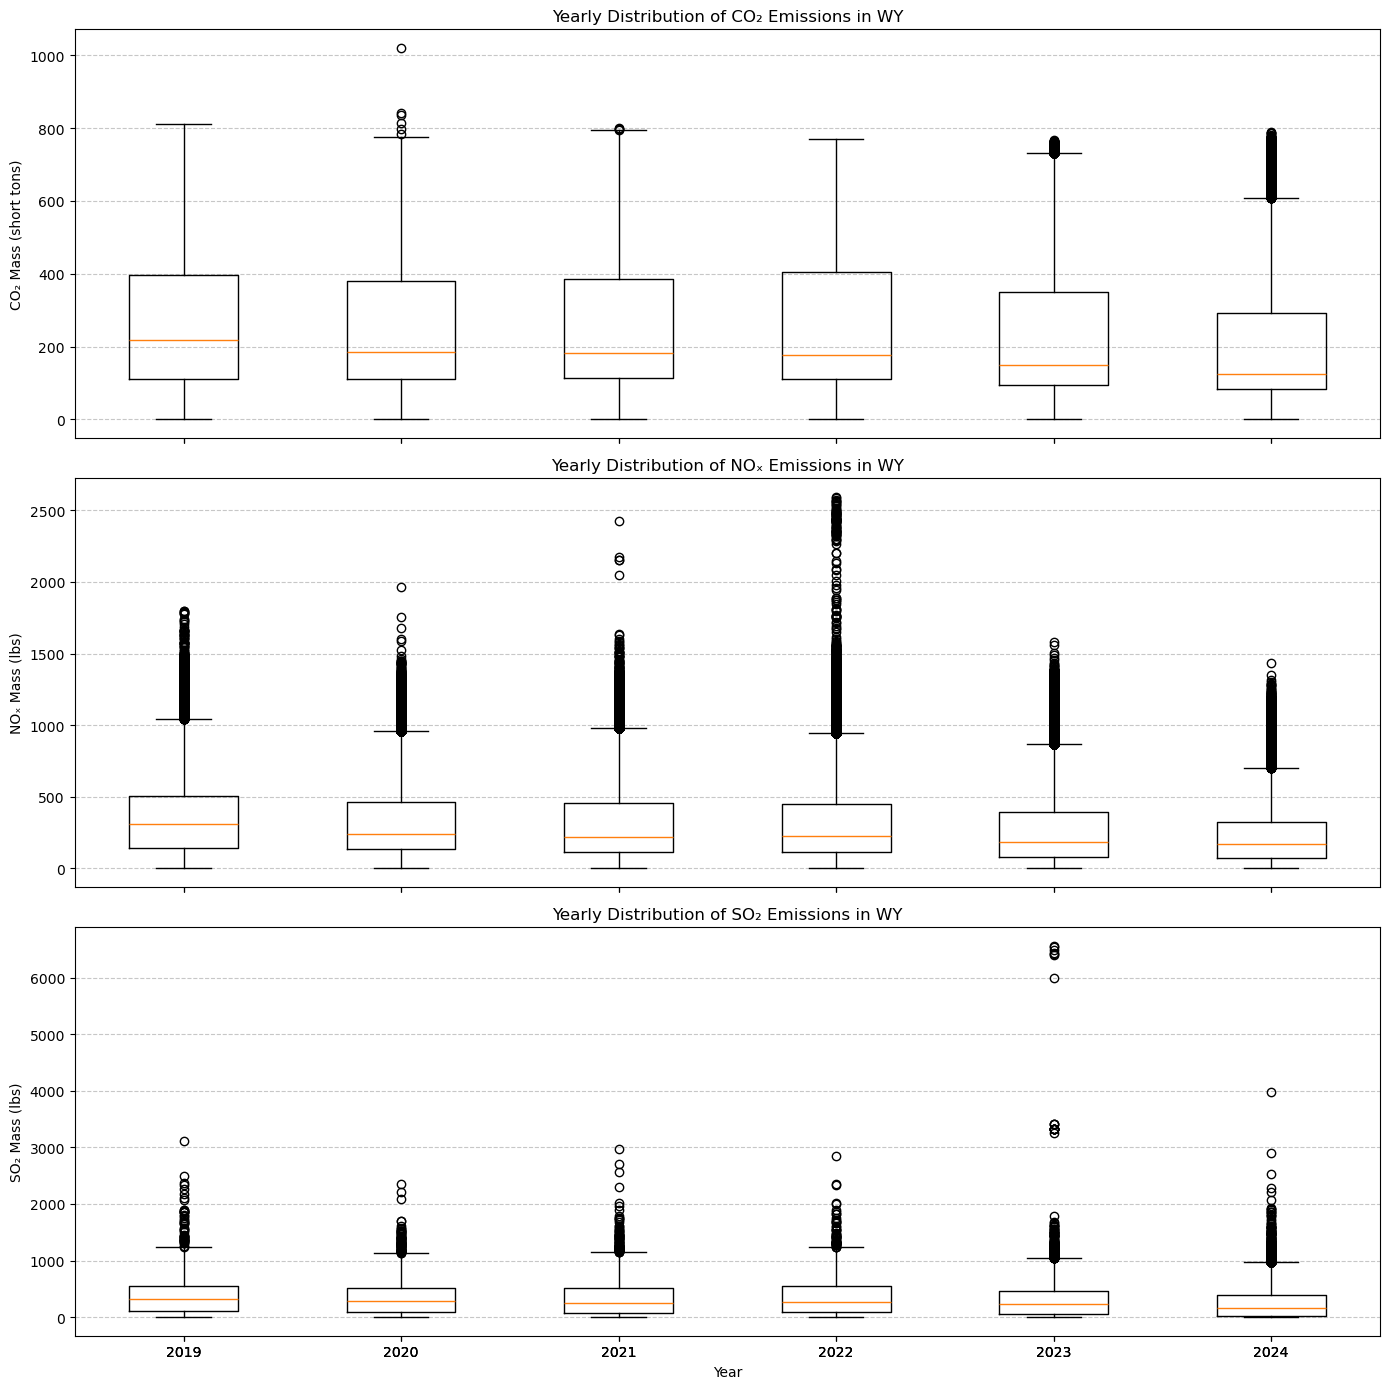

In [ ]:
df = campd_wy[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO2 Emissions in WY")
axes[0].set_ylabel("CO2 Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in WY")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO2 Emissions in WY")
axes[2].set_ylabel("SO2 Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


<h4>Complete Emission Distribution</h4>

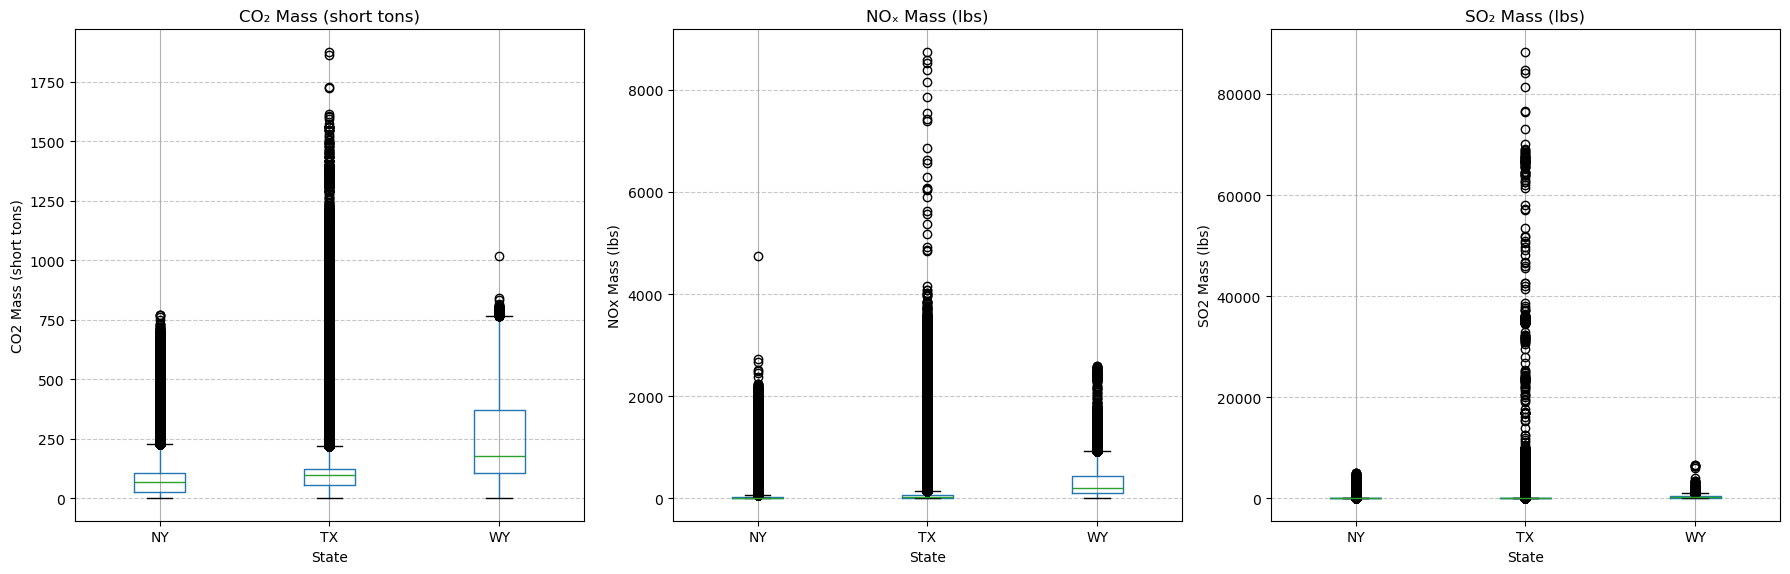

In [ ]:
# absolute

# Add a state column to each df
campd_tx["State"] = "TX"
campd_wy["State"] = "WY"
campd_ny["State"] = "NY"

df = pd.concat([campd_tx, campd_wy, campd_ny])

df = df[["State", "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)"]].dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

# Emissions and labels
emissions = [
    ("CO2 Mass (short tons)", "CO2 Mass (short tons)"),
    ("NOx Mass (lbs)", "NOₓ Mass (lbs)"),
    ("SO2 Mass (lbs)", "SO2 Mass (lbs)")
]

# Plot boxplots by state for each emission type
for ax, (col, title) in zip(axes, emissions):
    df.boxplot(column=col, by="State", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("State")
    ax.set_ylabel(col)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle("")
plt.tight_layout()
plt.show()


<h3>Histograms</h3>

- create histogram plots of the emission distributions with 100 bins
- log-scale them in a second step

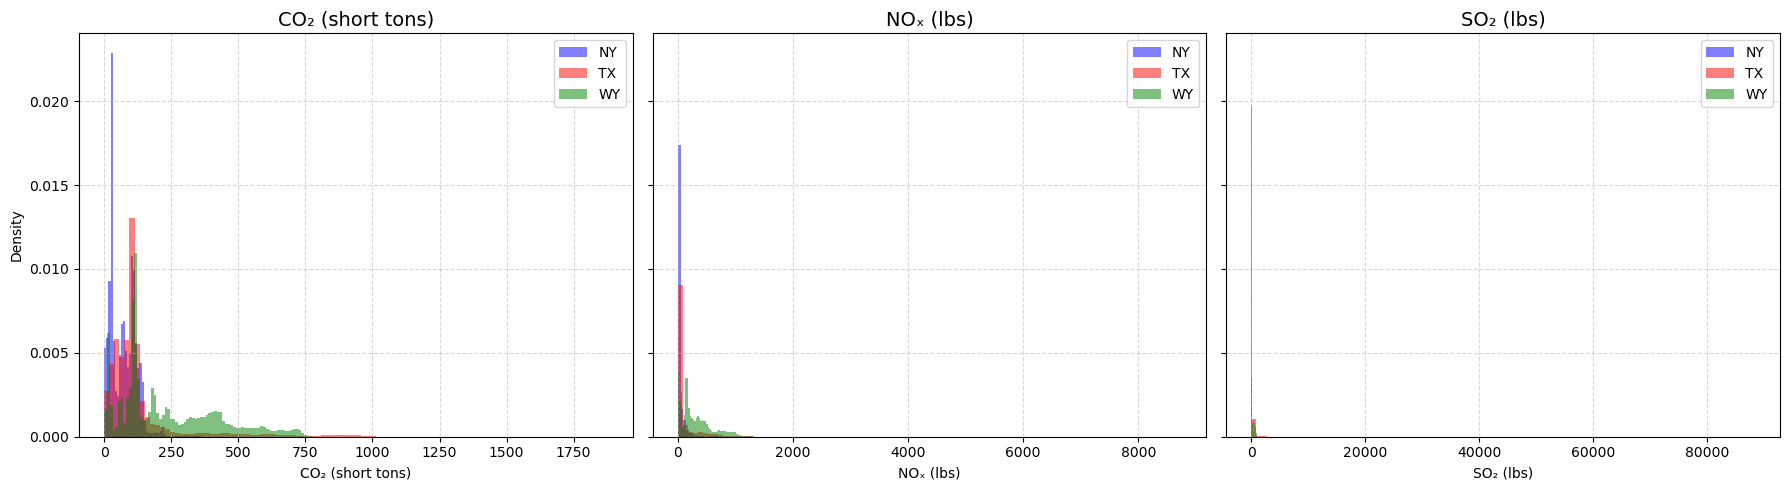

In [ ]:
co2_cols = ["State", "CO2 Mass (short tons)"]
nox_cols = ["State", "NOx Mass (lbs)"]
so2_cols = ["State", "SO2 Mass (lbs)"]

df_co2 = pd.concat([
    campd_ny[co2_cols].assign(Pollutant="CO2"),
    campd_tx[co2_cols].assign(Pollutant="CO2"),
    campd_wy[co2_cols].assign(Pollutant="CO2")
])

df_nox = pd.concat([
    campd_ny[nox_cols].assign(Pollutant="NOx"),
    campd_tx[nox_cols].assign(Pollutant="NOx"),
    campd_wy[nox_cols].assign(Pollutant="NOx")
])

df_so2 = pd.concat([
    campd_ny[so2_cols].assign(Pollutant="SO2"),
    campd_tx[so2_cols].assign(Pollutant="SO2"),
    campd_wy[so2_cols].assign(Pollutant="SO2")
])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

pollutants = {
    "CO2": ("CO2 Mass (short tons)", "CO2 (short tons)"),
    "NOx": ("NOx Mass (lbs)", "NOₓ (lbs)"),
    "SO2": ("SO2 Mass (lbs)", "SO2 (lbs)")
}

colors = {"NY": "blue", "TX": "red", "WY": "green"}

for ax, (poll, (col, title)) in zip(axes, pollutants.items()):
    for state, color in colors.items():
        if poll == "CO2":
            data = df_co2[df_co2["State"] == state][col].dropna()
        elif poll == "NOx":
            data = df_nox[df_nox["State"] == state][col].dropna()
        else:
            data = df_so2[df_so2["State"] == state][col].dropna()
        
        ax.hist(data, bins=100, alpha=0.5, label=state, color=color,
                density=True, log=False)  

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(title)
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


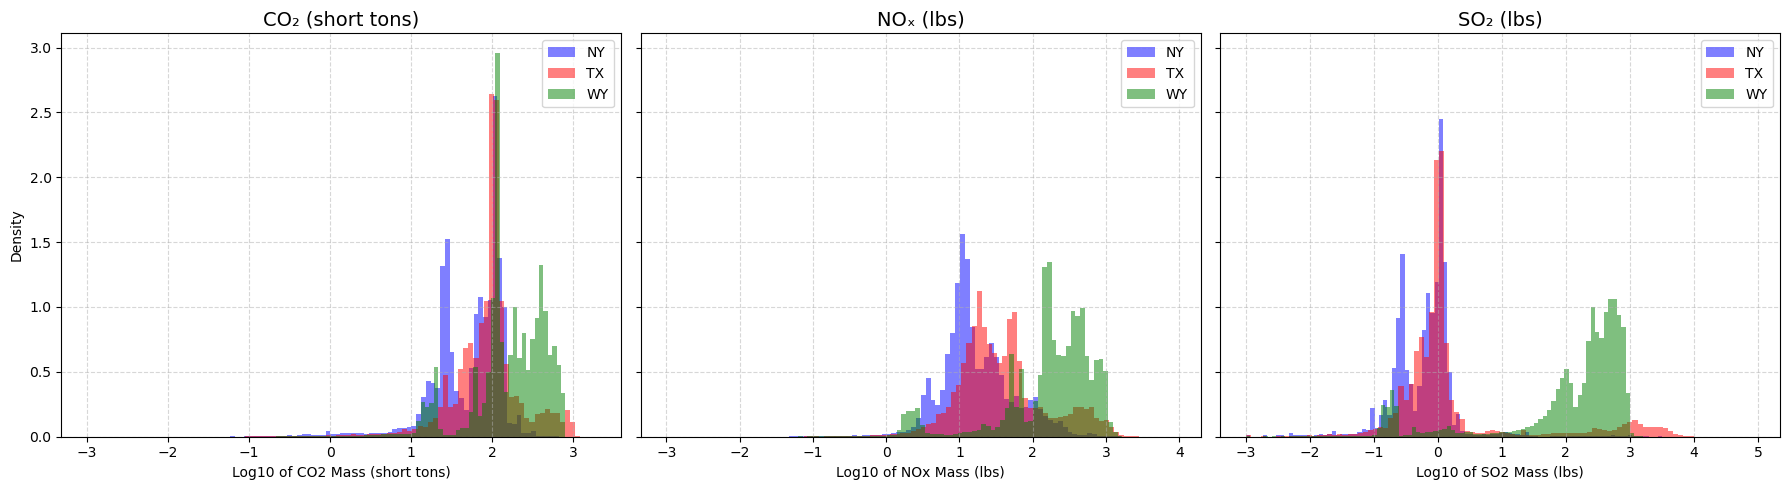

In [ ]:
# log-scaled emission distribution

co2_cols = ["State", "CO2 Mass (short tons)"]
nox_cols = ["State", "NOx Mass (lbs)"]
so2_cols = ["State", "SO2 Mass (lbs)"]

df_co2 = pd.concat([
    campd_ny[co2_cols].assign(Pollutant="CO2"),
    campd_tx[co2_cols].assign(Pollutant="CO2"),
    campd_wy[co2_cols].assign(Pollutant="CO2")
])

df_nox = pd.concat([
    campd_ny[nox_cols].assign(Pollutant="NOx"),
    campd_tx[nox_cols].assign(Pollutant="NOx"),
    campd_wy[nox_cols].assign(Pollutant="NOx")
])

df_so2 = pd.concat([
    campd_ny[so2_cols].assign(Pollutant="SO2"),
    campd_tx[so2_cols].assign(Pollutant="SO2"),
    campd_wy[so2_cols].assign(Pollutant="SO2")
])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

pollutants = {
    "CO2": ("CO2 Mass (short tons)", "CO2 (short tons)"),
    "NOx": ("NOx Mass (lbs)", "NOₓ (lbs)"),
    "SO2": ("SO2 Mass (lbs)", "SO2 (lbs)")
}

colors = {"NY": "blue", "TX": "red", "WY": "green"}

for ax, (poll, (col, title)) in zip(axes, pollutants.items()):
    for state, color in colors.items():
        if poll == "CO2":
            data = df_co2[df_co2["State"] == state][col].dropna()
        elif poll == "NOx":
            data = df_nox[df_nox["State"] == state][col].dropna()
        else:
            data = df_so2[df_so2["State"] == state][col].dropna()
        
        # Filter out zero values before log-transform
        data_pos = data[data > 0]
        
        # Log-transform the data
        log_data = np.log10(data_pos)
        
        ax.hist(log_data, bins=100, alpha=0.5, label=state, color=color, density=True)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(f'Log10 of {col}')
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


<h3>Relationship Analysis</h3>

- compute spearman correlation of numerical features (excluding coordinates and temperature)
- compute Kruskal-Wallis test H-statistic, p-value, and eta-squared to explore how much of the emission distribution can be explained by categorical features

<h4>Spearman Correlation</h4>

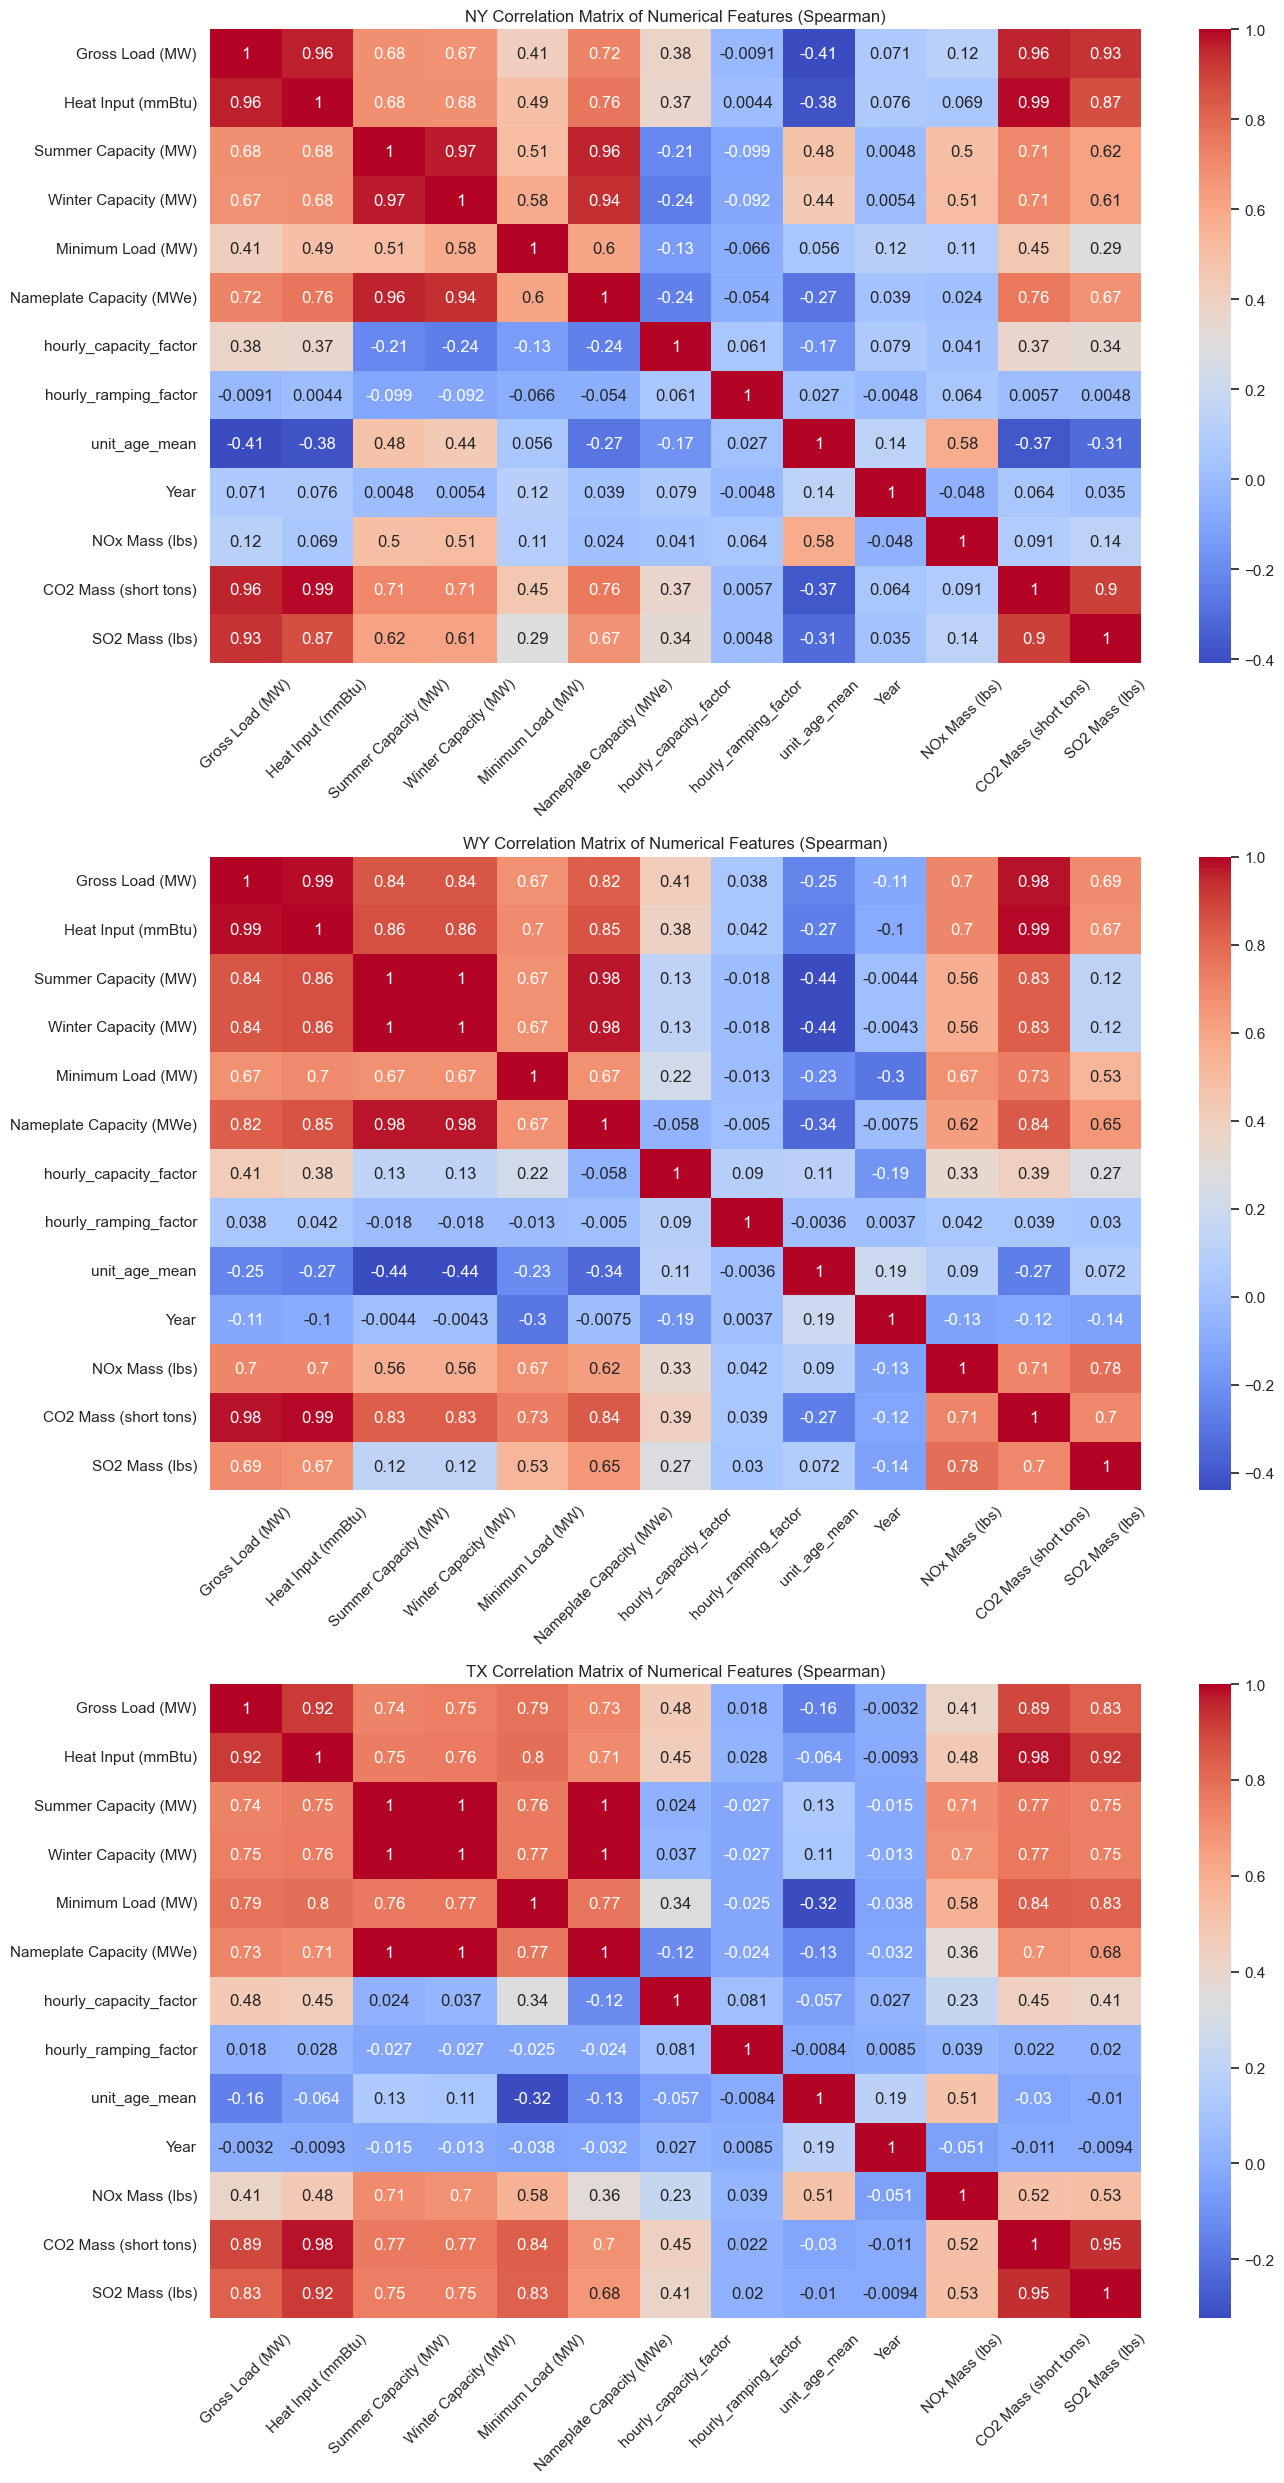

In [189]:
# Define numerical features
num_features = [
    'Gross Load (MW)', 'Heat Input (mmBtu)',
    # 'Latitude', 'Longitude', 
    "Summer Capacity (MW)", "Winter Capacity (MW)", 'Minimum Load (MW)',
    'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
    'hourly_ramping_factor', 'unit_age_mean', 'Year',
    'NOx Mass (lbs)', "CO2 Mass (short tons)", "SO2 Mass (lbs)"
]

# Compute Spearman correlation matrices
corr_matrices = {
    "NY": campd_ny[num_features].corr(method='spearman'),
    "WY": campd_wy[num_features].corr(method='spearman'),
    "TX": campd_tx[num_features].corr(method='spearman')
}

# Plot heatmaps
fig, axes = plt.subplots(3, 1, figsize=(14, 25))

for ax, (state, corr_matrix) in zip(axes, corr_matrices.items()):
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", ax=ax)
    ax.set_title(f"{state} Correlation Matrix of Numerical Features (Spearman)")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
    ax.set_yticklabels(ax.get_yticklabels())

plt.tight_layout()
plt.show()

<h4>Kruskal-Wallis Test</h4>

In [ ]:
# prerequisites for ANOVA not given, NOx is neither normally distributed nor does it have equal variance among groups
# instead we use the non-parametric Kruskal-Wallis test which only requires ordinality

<h5>NOx</h5>

In [83]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "NOx Mass (lbs)"


In [ ]:
NOx_emissions = campd_ny["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:
    feature_names.append(feature)

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  # Track total sample size across groups
    num_groups = len(campd_ny[feature].unique())

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = NOx_emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-Squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
5,NOx Controls,11804.509,0.000,0.664
7,SO2 Controls,834.644,0.000,0.556
6,Program Code,4674.343,0.000,0.552
4,Secondary Fuel Type,1666.061,0.000,0.475
3,Primary Fuel Type,1066.277,0.000,0.426
2,Unit Type,1217.719,0.000,0.405
8,SO2 Phase,207.193,0.000,0.137
0,Source Category,101.694,0.000,0.067
1,NOx Phase,81.943,0.000,0.040
9,Random_Category,2.851,0.322,0.001


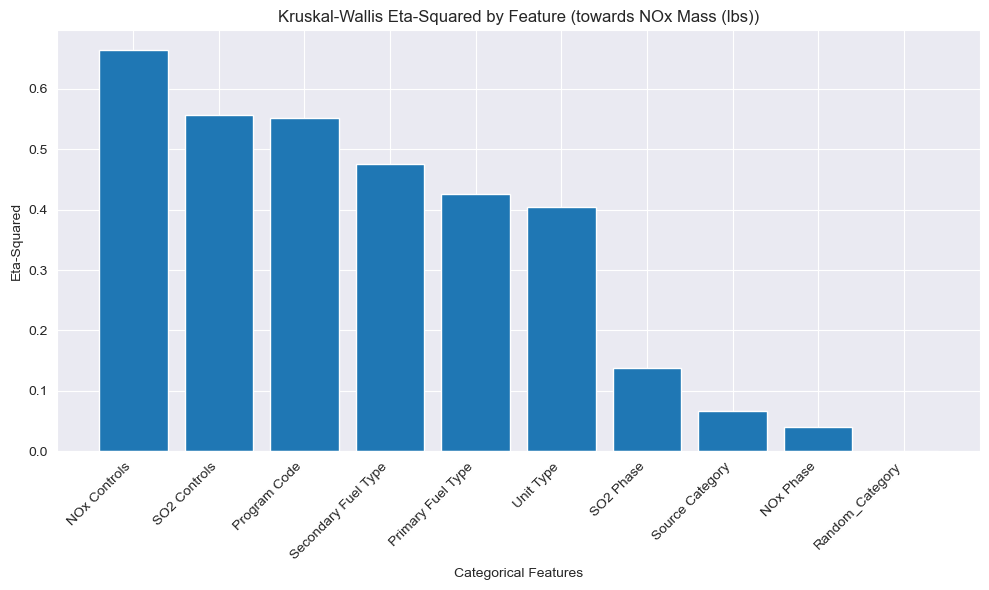

In [ ]:
# eta squared scales from 0 to 1
# it measures the variance in the dependent variable explained by the independent variable (akin to R^2)

plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

# ~66% of the variance in NOx Mass can be explained by NOx Controls

In [ ]:
NOx_emissions = campd_tx["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']  # Define the possible categories
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:
    feature_names.append(feature)

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0 
    num_groups = len(campd_tx[feature].unique()) 

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = NOx_emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (Eta-Squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
3,Primary Fuel Type,1719.663,0.000,0.688
6,Program Code,1675.122,0.000,0.670
2,Unit Type,6994.167,0.000,0.668
5,NOx Controls,10948.953,0.000,0.654
1,NOx Phase,613.794,0.000,0.614
7,SO2 Controls,1415.100,0.000,0.566
4,Secondary Fuel Type,2623.165,0.000,0.476
0,Source Category,310.267,0.000,0.206
8,SO2 Phase,95.246,0.000,0.094
9,Random_Category,2.050,0.430,0.000


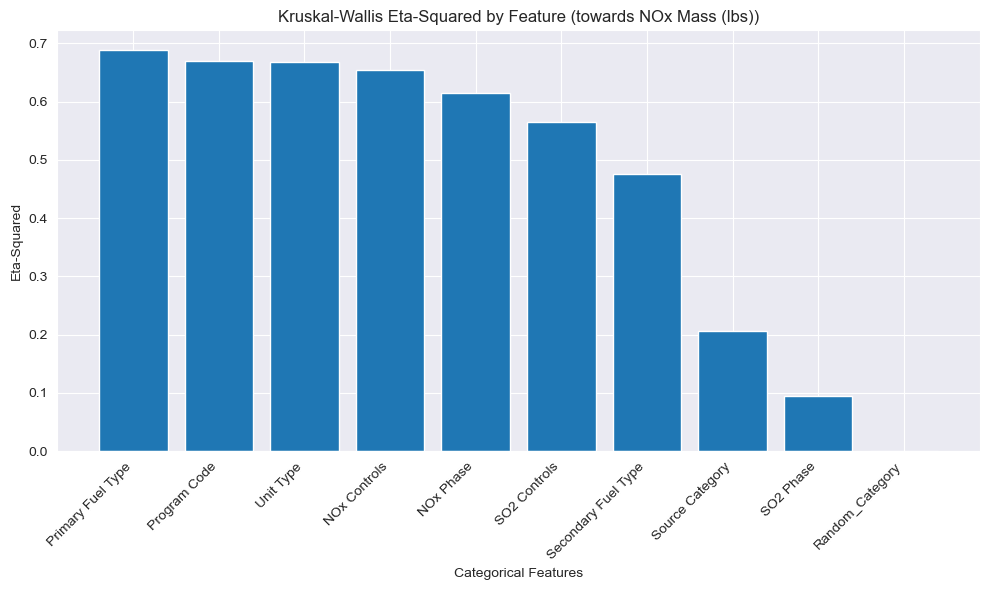

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

In [ ]:
NOx_emissions = campd_wy["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_wy[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = NOx_emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7575.831,0.000,0.797
1,Unit Type,1577.110,0.000,0.789
5,Program Code,502.525,0.000,0.503
0,NOx Phase,944.603,0.000,0.377
2,Primary Fuel Type,557.416,0.000,0.371
6,SO2 Controls,397.336,0.000,0.158
3,Secondary Fuel Type,51.262,0.000,0.050
7,Random_Category,1.033,0.619,-0.001


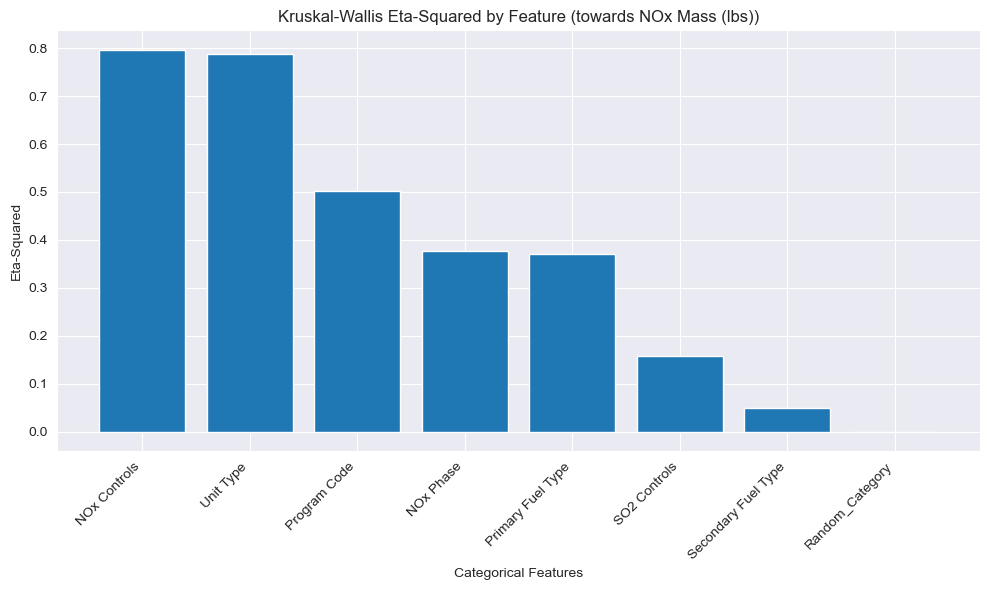

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

<h5>CO2</h5>

In [91]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "CO2 Mass (short tons)"


In [ ]:
emissions = campd_ny[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']  
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0
    num_groups = len(campd_ny[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
6,Program Code,6090.321,0.000,0.720
5,NOx Controls,11681.977,0.000,0.657
2,Unit Type,1674.163,0.000,0.558
3,Primary Fuel Type,1118.115,0.000,0.447
8,SO2 Phase,579.919,0.000,0.386
7,SO2 Controls,560.485,0.000,0.373
4,Secondary Fuel Type,863.137,0.000,0.245
0,Source Category,198.076,0.000,0.131
1,NOx Phase,144.840,0.000,0.071
9,Random_Category,2.696,0.478,0.000


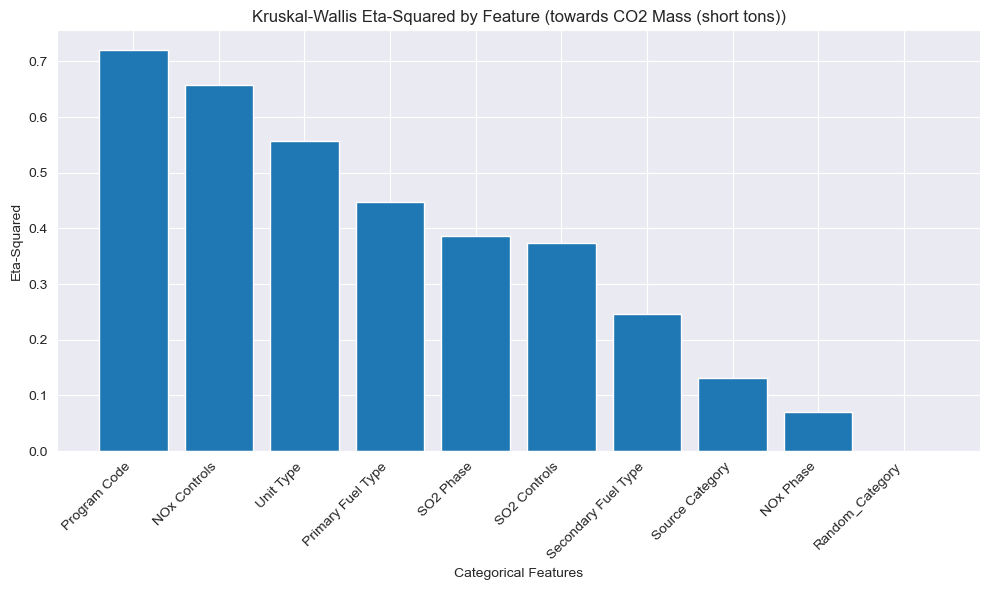

In [95]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_tx[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_tx[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
7,SO2 Controls,1745.498,0.000,0.698
6,Program Code,1741.968,0.000,0.697
5,NOx Controls,10712.208,0.000,0.639
1,NOx Phase,607.512,0.000,0.608
4,Secondary Fuel Type,3080.485,0.000,0.559
2,Unit Type,5669.588,0.000,0.541
3,Primary Fuel Type,1148.608,0.000,0.459
0,Source Category,262.678,0.000,0.174
8,SO2 Phase,152.374,0.000,0.152
9,Random_Category,2.806,0.385,0.001


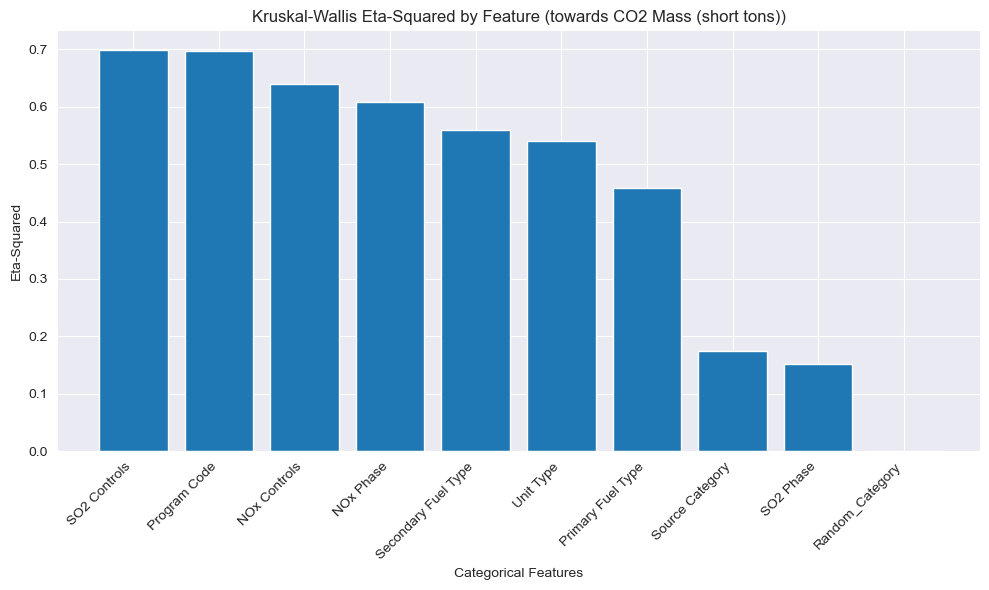

In [97]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_wy[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_wy[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7699.321,0.000,0.810
1,Unit Type,1436.046,0.000,0.718
5,Program Code,533.801,0.000,0.534
6,SO2 Controls,1273.443,0.000,0.509
2,Primary Fuel Type,568.101,0.000,0.378
0,NOx Phase,703.459,0.000,0.280
3,Secondary Fuel Type,8.142,0.008,0.007
7,Random_Category,0.645,0.743,-0.001


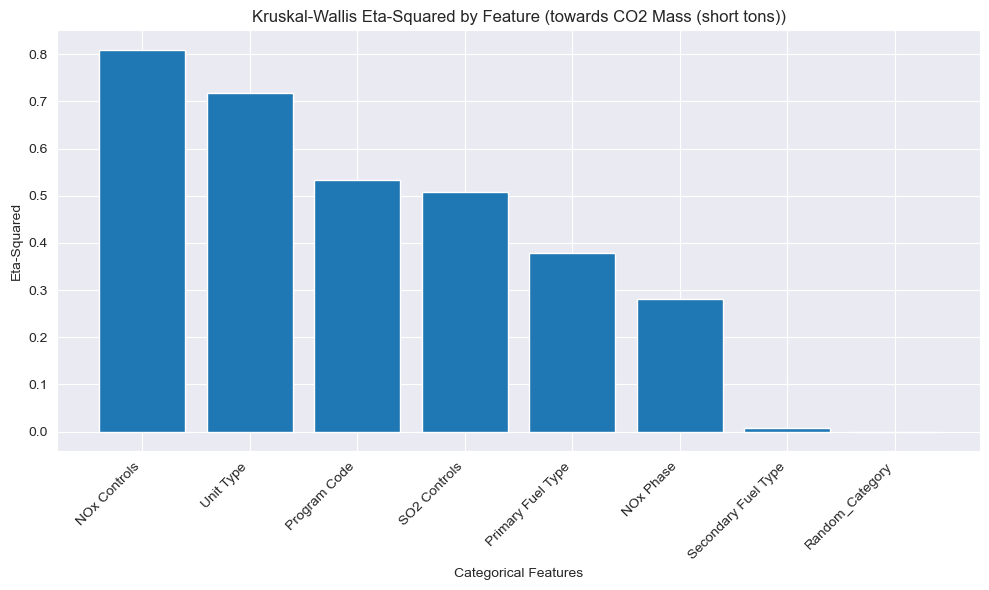

In [93]:
# eta squared scales from 0 to 1
# it measures the variance in the dependent variable explained by the independent variable (akin to R^2)

plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

<h5>SO2</h5>

In [98]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "SO2 Mass (lbs)"


In [ ]:
emissions = campd_ny[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_ny[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store the average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
5,NOx Controls,12430.316,0.000,0.699
7,SO2 Controls,994.624,0.000,0.663
6,Program Code,4910.146,0.000,0.580
3,Primary Fuel Type,1404.444,0.000,0.561
2,Unit Type,1027.088,0.000,0.341
8,SO2 Phase,294.184,0.000,0.195
4,Secondary Fuel Type,574.460,0.000,0.163
0,Source Category,234.598,0.000,0.155
1,NOx Phase,171.856,0.000,0.085
9,Random_Category,3.147,0.509,0.001


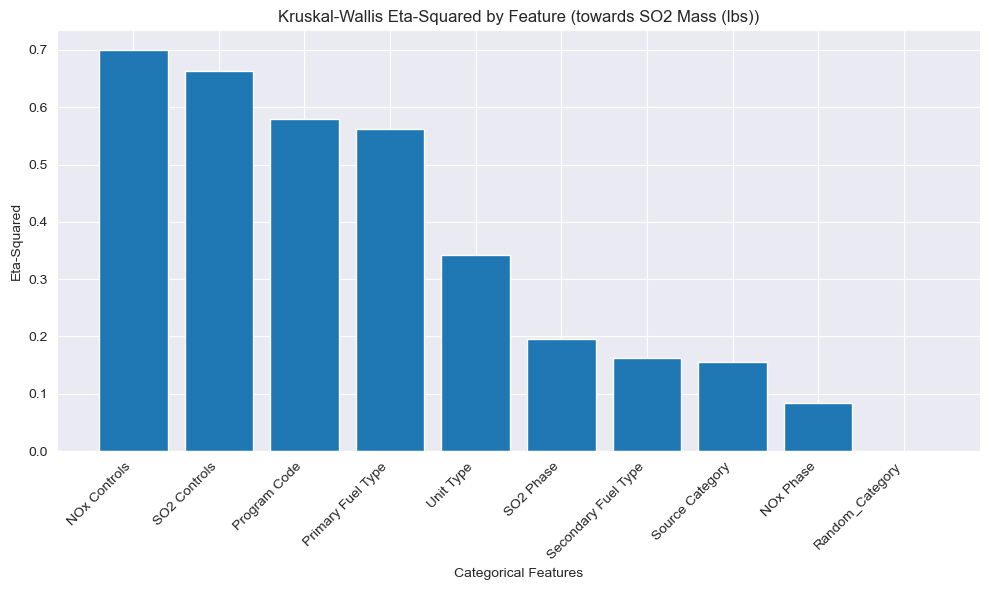

In [104]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_tx[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_tx[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Perform Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store the average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
6,Program Code,1901.497,0.000,0.761
1,NOx Phase,688.941,0.000,0.689
5,NOx Controls,11533.527,0.000,0.689
4,Secondary Fuel Type,3278.334,0.000,0.595
2,Unit Type,5718.638,0.000,0.545
3,Primary Fuel Type,1217.761,0.000,0.486
7,SO2 Controls,1163.095,0.000,0.465
0,Source Category,319.372,0.000,0.212
8,SO2 Phase,197.643,0.000,0.197
9,Random_Category,1.932,0.452,-0.000


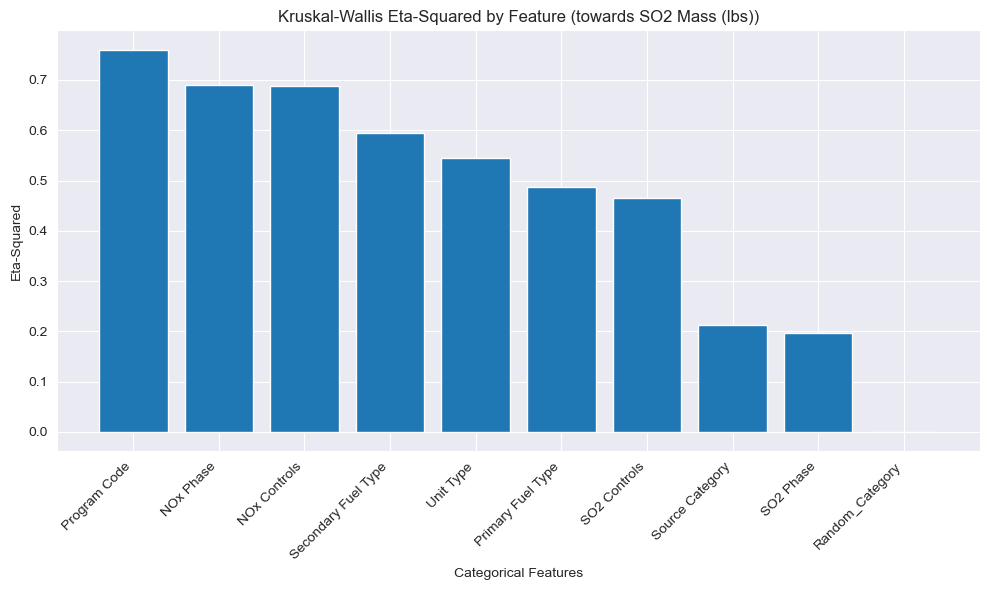

In [102]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_wy[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0 
    num_groups = len(campd_wy[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7070.167,0.000,0.744
1,Unit Type,1410.486,0.000,0.705
5,Program Code,702.895,0.000,0.703
0,NOx Phase,1423.050,0.000,0.569
2,Primary Fuel Type,522.898,0.000,0.348
6,SO2 Controls,268.036,0.000,0.106
3,Secondary Fuel Type,18.792,0.000,0.018
7,Random_Category,1.735,0.546,-0.000


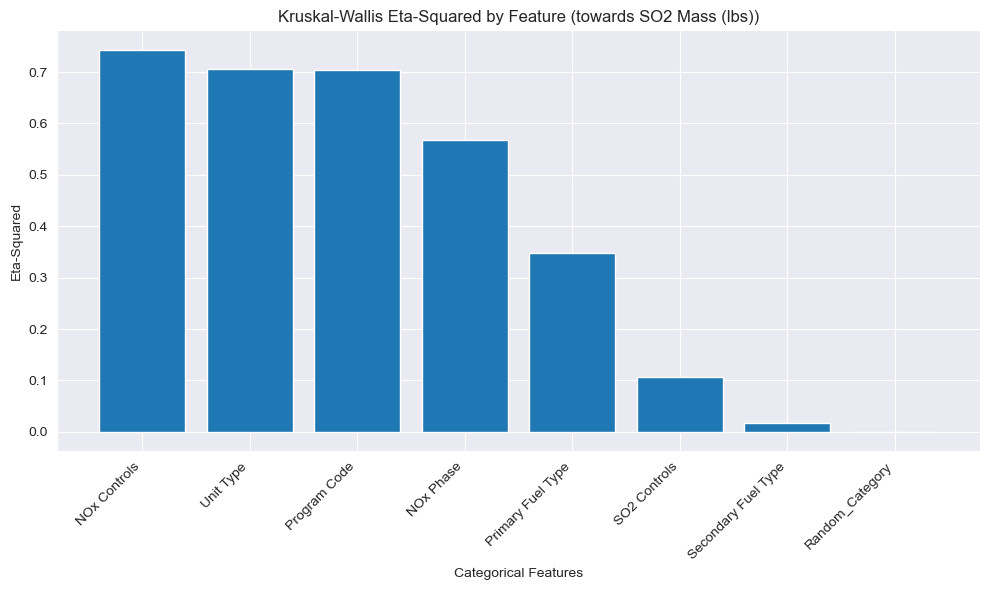

In [100]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()